# Belajar kode ML Essenza — pelan-pelan dari awal

Kita mau ngerti **apa yang dilakukan kode**, bukan sekadar bisa menjalankannya.

Gambaran besarnya begini: **SMILES diubah jadi angka → model belajar dari angka itu dan label aroma → model yang sudah belajar bisa memberi skor untuk molekul lain.**

Kamu nggak perlu paham semuanya sekaligus. Baca satu bagian, lihat contoh hasilnya, lalu coba ceritakan lagi pakai bahasamu sendiri.

**Buat sekarang, cukup baca hasil yang sudah tampil.** Nggak perlu menekan Run All. Kalau nanti dijalankan, sel kode di notebook ini cuma membaca file hasil, menghitung fitur contoh, mengecek hitungan, dan memakai model tersimpan untuk prediksi. Kode training yang panjang ditaruh sebagai teks untuk dibaca.

Nama seperti V7 pada file cuma penanda arsip. Penelitian utama kita tetap membandingkan **XGBoost dan LightGBM** pada lima sumber data, **Morgan 2048**, dan **8 deskriptor**.

Output contoh diperbarui dengan menjalankan seluruh 31 sel ringan pada 25 Oktober 2026. Tidak ada training atau tuning.


**Kode aktif ada di `research/`.** Hasil utama tetap arsip V7; V9 tambahan. Notebook ini membaca hasil dan menjalankan contoh ringan. Training/tuning hanya tampil sebagai teks.

## Mau baca bagian yang mana?

Kalau baru mulai, baca bagian **1–4** dulu. Sisanya bisa nyusul.

1. [Kita lagi bikin apa?](#tujuan)
2. [Persiapan dan lokasi file](#setup)
3. [Data dibaca dan dibersihkan](#data)
4. [SMILES diubah jadi angka](#fitur)
5. [Data latihan, validasi, test, dan seed](#split)
6. [Model belajar dan bobot kelas](#model)
7. [Optuna mencari pengaturan model](#optuna)
8. [Coba model lewat validasi dan pilih hasilnya](#oof)
9. [Latih model final dan cek hasil test](#evaluasi)
10. [Masukkan satu SMILES untuk prediksi](#prediksi)
11. [File hasilnya ada di mana?](#hasil)
12. [Latihan menjelaskan ke dosen](#latihan)
13. [Kode lengkap, kalau mau lihat lebih jauh](#lampiran)

Kalau bingung sama istilah atau simbol, buka bagian **library** dan **cara baca kode** di bawah. Nggak perlu menghafal semua nama library.


<a id="cara-baca-baris"></a>
## Cara baca notebook ini biar nggak numpuk di kepala

Kita ikutin **satu data dulu**, bukan menghafal semua kode sekaligus:

```text
SMILES → angka fitur → model → skor aroma → label yang dipilih
```

Di setiap bagian, baca dengan urutan ini:

1. **Data masuknya apa?** Misalnya satu SMILES atau tabel hasil eksperimen.
2. **Baris ini ngapain?** Lihat tabel penjelasan tepat di bawah kode.
3. **Hasilnya apa?** Misalnya angka fitur, satu model, atau skor aroma.
4. **Dipakai di mana lagi?** Ikutin variabelnya ke langkah berikutnya.

Ada dua jenis kotak kode di sini:

| Yang kamu lihat | Kalau klik Run All, apa yang terjadi? |
|---|---|
| Sel **Code** | Kodenya dijalankan. Contohnya baca hasil lama, bikin fitur contoh, dan pakai model yang sudah dilatih. |
| Kode di dalam penjelasan **Markdown** | Cuma ditampilkan buat dibaca. Kode training di sini nggak ikut dijalankan. |

**Nomor baris** pada tabel sel Code dihitung dari kotak kode di atasnya, mulai 1. Untuk potongan dari file asli, nomor baris mengikuti file tersebut kalau isinya masih cocok. Baris kosong cuma pemisah, jadi nggak perlu dijelaskan. Kalau satu perintah ditulis beberapa baris, penjelasannya tetap disambung ke perintah yang sama.

Kalau penjelasan fungsi di lampiran kepanjangan, klik judulnya buat buka-tutup bagian itu. Dahulukan **fitur → target → training satu label → validasi → Optuna → prediksi**. Bagian penyimpanan progres dan pemeriksaan file bisa dipelajari belakangan.

**Catatan revisi 25 Oktober 2026:** yang diubah adalah penjelasannya. Sel kode, urutan jalannya, nomor eksekusi, dan hasil lama tetap disimpan. Saat merapikan penjelasan ini, kita nggak training, mencari parameter, mengolah ulang dataset, atau memprediksi lagi. Jadi, angka yang terlihat tetap berasal dari eksekusi notebook sebelumnya.

**Langsung ke:** [Library](#library) · [Cara baca sintaks dan ukuran data](#sintaks) · [Pengaturan model](#parameter) · [Latihan kalau dosen menunjuk kode](#sidang-baris).


<a id="library"></a>
## 0A. Library yang dipakai: tugasnya masing-masing apa?

**Library** itu kumpulan alat yang sudah disediakan orang lain. Kita pakai alatnya lewat kode. Misalnya, RDKit sudah punya alat buat membaca SMILES, jadi kita nggak bikin pembaca SMILES dari nol.

**Modul proyek** beda lagi: itu file Python punya proyek kita sendiri, seperti `research/inference.py`.

Saat melihat `import`, bacanya **“siapkan alat ini supaya bisa dipakai”**. Fungsi yang diimpor belum tentu langsung dipanggil. Contohnya, mengimpor `fit` nggak otomatis melatih model. Tapi isi file yang berada di luar fungsi bisa jalan saat file itu diimpor. Itu sebabnya satu helper kadang ikut membutuhkan library lain.

### Library dari luar Python

Versi di bawah dicatat dari `.venv` proyek saat panduan dibuat pada **25 Oktober 2026**. Versi library inti penelitian juga tercatat di `research/config/experiment.json`. Merapikan panduan ini nggak memasang atau memperbarui library.

| Library dan nama di kode | Dipakai buat apa di proyek ini? | Contoh pemakaian | Versi yang tercatat |
|---|---|---|---|
| **NumPy** — paket `numpy`, biasa ditulis `np` | Mengurus kumpulan angka: fitur molekul, target 0/1, indeks baris, dan skor. | `np.load(...)` membuka file array; `np.mean(...)` menghitung rata-rata. | 1.26.4 |
| **pandas** — `pandas`, biasa ditulis `pd` | Membaca dan mengolah tabel, seperti CSV molekul dan tabel hasil trial. | `pd.read_csv(...)` membaca CSV jadi tabel. Membaca hasil lama nggak menjalankan training. | 2.2.3 |
| **Matplotlib** — `matplotlib.pyplot`, biasa ditulis `plt` | Membuat grafik yang kamu lihat di notebook. | `plt.show()` menampilkan grafik. Pengaturan grafik nggak mengubah model. | 3.10.6 |
| **RDKit** — `Chem`, `Descriptors`, `rdFingerprintGenerator`, `rdBase`, `RDLogger` | Membaca struktur dari SMILES, mengecek molekulnya, lalu menghitung Morgan dan deskriptor. | `Chem.MolFromSmiles(...)` membaca SMILES. RDKit sendiri nggak memprediksi aroma dan nggak memilih delapan deskriptor buat kita. | 2026.3.4 |
| **scikit-learn** — diimpor lewat `sklearn` | Membagi data berdasarkan grup dan menghitung nilai evaluasi, seperti AP, AUROC, precision, dan recall. | `GroupShuffleSplit` membagi train/test; `average_precision_score` menghitung AP. | 1.6.1 |
| **XGBoost** — `XGBClassifier`, `xgboost` | Melatih satu model aroma yang berisi banyak pohon. | `model.fit(...)` melatih model. `eval_metric='logloss'` adalah pengaturan evaluasi library; Optuna kita membandingkan model pakai AP validasi. | 2.1.4 |
| **LightGBM** — `LGBMClassifier` | Alternatif XGBoost untuk melatih model berbasis pohon. Setiap model tetap menjawab satu label aroma. | `LGBMClassifier(...)` menyiapkan model; `.fit(...)` baru melatihnya. | 4.6.0 |
| **Optuna** — `optuna`, `TPESampler`, `FixedTrial` | Mencoba pengaturan model dan mencatat hasil setiap percobaannya. | `study.ask()` memulai trial baru. `FixedTrial(...)` cuma membaca pengaturan yang sudah diberikan, bukan mencari yang baru. | 4.5.0 |
| **joblib** — `joblib` | Menyimpan model yang sudah dilatih dan membukanya lagi saat mau dipakai. Juga menyimpan keadaan pencarian Optuna. | `joblib.dump(...)` menyimpan; `joblib.load(...)` membuka. Membuka model nggak melatihnya lagi. | 1.6.0 |
| **psutil** — `psutil` | Mengecek RAM, proses yang masih jalan, dan informasi CPU saat eksperimen. | `psutil.virtual_memory()` membaca keadaan RAM. Pemeriksa `Limits` yang ditampilkan di sini nggak membaca suhu CPU. | 7.0.0 |
| **requests** — `requests` | Mengunduh CSV sumber kalau file yang dibutuhkan belum ada dan mode offline nggak aktif. | `requests.get(...)` dipakai di `load_sources`. Sel pembaca hasil dalam notebook ini nggak memanggil unduhan itu. | 2.32.5 |
| **IPython** — `display`, `Markdown` | Membuat tabel dan tautan tampil rapi di notebook. | `display(tabel)` menampilkan tabel. Ini alat tampilan, bukan bagian yang belajar memprediksi. | Belum terdeteksi di environment pembuat panduan |
| **ipykernel** — kernel Jupyter | Menghubungkan notebook dengan Python saat kamu menjalankan sel. | Dipakai editor untuk menjalankan kode. Membaca hasil yang sudah tersimpan nggak butuh kernel aktif. | Belum terdeteksi di environment pembuat panduan |
| **SciPy** — `scipy.sparse`, biasa ditulis `sp` | Ikut dibutuhkan helper lama di `research/source_identity.py` untuk menyimpan matriks yang kebanyakan nilainya nol secara hemat. | Terlihat lewat helper yang diimpor. Bukan berarti pengelompokan lain dari SciPy otomatis menjadi bagian training utama. | 1.15.3 |
| **PyYAML** — `yaml` | Membaca file pengaturan YAML pada helper lama. | `yaml.safe_load(...)` dipakai di `src/config.py`. Pengaturan penelitian utama tetap ada di `research/config/experiment.json`. | 6.0.2 |

### Alat bawaan Python

Yang ini sudah ikut Python, jadi nggak perlu dipasang satu-satu lewat pip.

| Nama di kode | Gunanya, pakai bahasa gampang |
|---|---|
| `pathlib` | Menyusun alamat file. Contohnya `ROOT / 'data' / 'records.csv'`. |
| `json` | Mengubah teks JSON jadi isi yang bisa dipakai Python, atau menyimpannya kembali sebagai JSON. |
| `hashlib` | Membuat SHA-256, semacam sidik jari file, untuk mengecek apakah isi file berubah. |
| `os` | Membaca pengaturan dari sistem, mengurus bagian alamat folder, dan membaca ID proses. |
| `sys` | Melihat Python mana yang dipakai dan memberi tahu Python lokasi modul proyek. |
| `argparse` | Membaca pilihan yang kamu ketik di terminal, misalnya `--smiles` atau `--run`. |
| `collections` | `Counter` menghitung kemunculan. `defaultdict(set)` membantu menggabungkan label tanpa menyimpan label yang sama berkali-kali. |
| `datetime` | Mencatat tanggal, jam, dan zona waktu eksperimen. |
| `time` | Mengukur waktu yang sudah dipakai. Contohnya untuk batas waktu tuning. |
| `contextlib` | Membantu menutup atau melepas sesuatu setelah dipakai, misalnya pengunci folder hasil. |
| `importlib` | Membaca versi library yang terpasang. |
| `platform` | Membaca nama komputer, sistem operasi, dan informasi perangkat. |
| `warnings` | Mengatur pesan peringatan yang muncul. Menyembunyikan peringatan nggak membuat model lebih akurat. |
| `shutil` | Di runner ini, dipakai mengecek ruang kosong di penyimpanan. |
| `io` | Membuat file sementara di memori supaya hasil unduhan bisa langsung dibaca pandas. |
| `re` | Mencari atau mengganti pola teks, misalnya merapikan spasi dalam istilah aroma. |
| `copy` | Membuat salinan isi variabel tertentu supaya bisa diolah terpisah. |
| `dataclasses` | Membantu menyusun satu objek berisi pengaturan fitur pada helper lama. |
| `functools` | Bisa menyimpan hasil fungsi yang pernah dihitung di memori supaya nggak perlu dihitung lagi. |
| `typing` | Memberi petunjuk tipe data pada kode supaya pembacanya tahu isi variabel yang diharapkan. |

### File kode buatan proyek kita sendiri

Kamu nggak perlu menghafal semua alamatnya sekarang. Tabel ini buat mencari bagian yang sedang dibahas.

| File | Fungsi yang dicari | Tugasnya |
|---|---|---|
| `KODE_ML/_lokasi.py` | `baca_json`, `hasil_penelitian` | Mencari file data dan hasil utama yang sudah ada. |
| `research/preprocessing.py` | `merge_sources`, `map_labels`, `encode_and_split` | Merapikan data, menyamakan istilah aroma, menggabungkan molekul yang sama, lalu menyiapkan target dan pembagian data. |
| `research/source_identity.py` | `_attach_smiles`, `_attach_sigma`, `_cas_bridge` | Membantu mencocokkan identitas molekul dengan SMILES. Beberapa fungsi lamanya dipakai ulang, bukan seluruh proses lamanya dijalankan. |
| `research/source_identity.py` | `normalize` | Merapikan teks istilah aroma. Kamus utama kita tetap dari IFRA, dengan padanan istilah di `perfume_data.py`. |
| `research/splits.py` | `structure_feature_groups`, `outer_split`, `inner_folds` | Membuat grup dan menentukan baris mana yang masuk train, validasi, atau test. |
| `research/features.py` | `calculate_morgan`, `calculate`, `verify` | Menghitung Morgan 2048 bit dan delapan deskriptor, lalu mengecek hasilnya. |
| `research/validation.py` | `make_model`, `fit`, `cross_validate`, `repeated_grouped_cv` | Menyiapkan model, menghitung bobot, melatih, dan menjalankan validasi. |
| `research/tuning.py` | `suggest`, `tune` | Menjalankan pencarian pengaturan memakai Optuna. Nama V6 ada karena file lama ini dipakai ulang. |
| `research/experiment.py` | `features`, `select_candidates`, `run_all` | Mengatur eksperimen utama A–D. Mengimpor `run_all` saja nggak menjalankan eksperimen. |
| `research/training.py` | `fit_final_models` | Melatih dan menyimpan model akhir untuk setiap aroma. |
| `research/metrics.py` | `binary_metrics`, `summarize` | Menghitung hasil evaluasi tiap aroma dan rata-ratanya. |
| `research/inference.py` | `predict` | Memakai 109 model tersimpan untuk memprediksi satu SMILES. |
| `alignment/data.py`, `src/artifacts.py` | `digest`, helper JSON/hash | Membaca atau menyimpan catatan dan mengecek file. Pemakaian helper ini nggak mengganti dataset utama kita. |
| `src/config.py` | `CONFIG`, `load_config` | Membaca pengaturan lama yang masih dibutuhkan helper. Aturan eksperimen utama tetap `protocol_v7.json`. |

Kalau ditanya **“library apa yang dipakai?”**, cukup mulai dari ini:

> “RDKit buat mengubah struktur molekul jadi angka. XGBoost dan LightGBM buat melatih model. Optuna buat mencari pengaturannya. scikit-learn buat membagi data dan menghitung evaluasi. NumPy dan pandas buat mengolah angka serta tabel, lalu joblib buat menyimpan model.”

Training utama kita **nggak memakai TensorFlow, PyTorch, SMOTE, GOSS, GPU, atau neural network**. ONNX berkaitan dengan pemakaian model di aplikasi, terpisah dari training Python yang dipelajari di sini. Catatan backend dan laporan soal Android berbeda, jadi status aplikasinya perlu dilihat dari bukti uji aplikasinya.


<a id="sintaks"></a>
## 0B. Kalau ketemu bentuk kode ini, bacanya gimana?

Kamu nggak harus hafal istilah sintaksnya. Pahami dulu **baris itu mengambil apa dan menghasilkan apa**.

| Kode | Bacanya | Contoh di proyek kita |
|---|---|---|
| `import numpy as np` | “Siapkan NumPy, lalu panggil dengan nama pendek np.” | `np` itu nama panggilan library, bukan nama model. |
| `from ... import fit` | “Ambil fungsi fit dari file itu.” | Fungsinya baru jalan saat kita menulis `fit(...)`. |
| `def f(x):` | “Bikin fungsi bernama f yang menerima x.” | Isi yang menjorok di bawahnya baru jalan ketika fungsi dipanggil. |
| `return hasil` | “Kirim hasil ini ke baris yang memanggil fungsi.” | `return` mengembalikan nilai; `print` cuma menampilkannya. |
| `x.shape` | “Ukuran data x berapa?” | `(5353,2056)` artinya 5353 baris molekul dan 2056 kolom fitur. |
| `y[:, j]` | “Ambil semua baris, tapi cuma kolom aroma nomor j.” | Hasilnya target untuk satu aroma, misalnya sweet. |
| `x[tr]` | “Ambil baris x yang nomornya ada di tr.” | Dipakai mengambil bagian latihan suatu fold. |
| `predict_proba(x)[:, 1]` | “Ambil skor kelas 1 untuk semua baris.” | Kelas 1 berarti label itu diprediksi ada. Ini bukan mengambil aroma kedua. |
| `x[None, :]` | “Buat satu baris tambahan yang membungkus angka-angka x.” | Daftar 2056 angka jadi tabel satu molekul: `(1,2056)`. |
| `axis=0` | “Untuk setiap kolom, hitung dari atas ke bawah.” | `y.sum(axis=0)` menghitung berapa molekul punya setiap label. |
| `axis=1` | “Untuk setiap baris, hitung dari kiri ke kanan.” | `y.sum(axis=1)` menghitung berapa label yang tercatat untuk setiap molekul. |
| `for j, name in enumerate(labels)` | “Ambil nomor urut dan nama label satu per satu.” | Nomor j dimulai dari 0; name berisi nama aroma pada nomor itu. |
| `[f(s) for s in smiles]` | “Jalankan f untuk setiap SMILES, lalu kumpulkan hasilnya.” | Cara ringkas menulis loop. Belum tentu training; tergantung f itu ngapain. |
| `{nama: nilai for ...}` | “Buat pasangan nama dan nilainya sambil mengulang data.” | Misalnya nama aroma dipasangkan dengan hasil evaluasinya. |
| `**params` | “Buka isi kumpulan pengaturan ini jadi pilihan fungsi.” | `{'n_estimators':100}` diteruskan sebagai `n_estimators=100`. |
| `lambda k: scores[k]` | “Untuk k ini, ambil skornya.” | Dipakai `max` buat membandingkan skor model. |
| `a if kondisi else b` | “Kalau kondisinya benar, pilih a. Kalau nggak, pilih b.” | Misalnya memilih pengaturan baseline atau hasil Optuna. |
| `set(a) & set(b)` | “Cari anggota yang muncul di a dan juga b.” | Kalau ada grup yang muncul di train dan test, berarti grup itu bocor. |
| `(y==0) & (d==1)` | “Cari baris yang targetnya 0 dan prediksinya 1.” | Ini membantu menghitung false positive. |
| `assert kondisi` | “Pastikan ini benar. Kalau salah, berhenti.” | Contohnya memastikan jumlah fitur cocok dengan yang diminta model. |
| `raise ValueError(...)` | “Berhenti dan kasih tahu apa yang salah.” | Misalnya struktur nggak valid atau jumlah fitur berbeda. |
| `with np.load(...) as z` | “Buka file array dengan nama z, lalu tutup setelah selesai.” | Array yang disalin pakai `.copy()` tetap bisa dipakai sesudah file ditutup. |
| `try / except / finally` | “Coba jalankan; tangani kalau gagal; tetap kerjakan bagian penutup.” | Progres dan waktu tuning tetap dicatat kalau proses terputus. |
| `if __name__ == '__main__'` | “Jalankan bagian ini kalau file dibuka sebagai program utama.” | Bagian itu nggak langsung jalan saat file cuma diimpor. |
| `float32`, `uint8`, `int8` | “Pakai jenis penyimpanan angka ini.” | float menyimpan pecahan; integer menyimpan bilangan bulat. Di sini Morgan dan target sama-sama bisa 0/1, tapi gunanya berbeda. |
| `f'{nilai:.6f}'` | “Tampilkan nilai dengan enam angka di belakang koma.” | Ini cuma cara menampilkan, bukan mengubah model atau file hasil aslinya. |

### Cara baca ukuran data

Kalau ada dua angka seperti `(5353,109)`, bacanya **5353 baris × 109 kolom**. Apa isi baris dan kolomnya, lihat nama variabelnya.

| Data | Ukuran | Maksudnya |
|---|---|---|
| Semua Morgan | `(6686,2048)` | 6686 molekul, masing-masing punya 2048 posisi bit. |
| Semua deskriptor | `(6686,8)` | 6686 molekul, masing-masing punya delapan angka sifat molekul. |
| X train A/C | `(5353,2048)` | Fitur 5353 molekul latihan, memakai Morgan saja. |
| X train B/D | `(5353,2056)` | Fitur 5353 molekul latihan, memakai Morgan ditambah delapan deskriptor. |
| y train | `(5353,109)` | Target aroma untuk 5353 molekul latihan dan 109 label. |
| `y_train[:,j]` | `(5353,)` | Satu daftar target untuk satu aroma, berisi 5353 angka 0/1. |
| OOF rata-rata | `(5353,109)` | Skor validasi untuk baris train. Baris itu diprediksi model fold yang nggak melatih baris tersebut. |
| Skor test | `(1333,109)` | Skor untuk 1333 molekul test dan 109 aroma. |
| Input prediksi D | `(1,2056)` | Satu molekul yang sudah diubah jadi 2056 fitur. |
| `predict_proba` dari satu model aroma | `(1,2)` | Dua skor untuk satu molekul: kelas 0 dan kelas 1. Kita mengambil skor kelas 1. |
| Hasil dari seluruh model aroma | 109 hasil | Satu skor dan satu keputusan untuk tiap aroma. Beberapa aroma boleh dipilih sekaligus. |


<a id="parameter"></a>
## 0C. Pengaturan model ini ngaruhnya ke apa?

Di kode kita, proses belajarnya dimulai lewat `model.fit(...)`. Yang menyusun pohon-pohonnya adalah library XGBoost atau LightGBM.

Bayangin **satu model sweet punya banyak pohon**. Pohon berikutnya memberi koreksi ke gabungan prediksi sebelumnya. Setelah kontribusi pohon-pohon itu digabung, model menghasilkan skor sweet antara 0 dan 1.

Kita menyiapkan **109 model seperti itu**, masing-masing buat satu label aroma. Pengaturan satu kandidat dipakai untuk seluruh model aromanya, tapi isi pohon yang dipelajari tiap model bisa berbeda.

| Pengaturan | Arti gampangnya | Hal yang perlu diingat |
|---|---|---|
| `n_estimators` | Banyak putaran penambahan pohon. Pada model biner kita, biasanya satu pohon ditambahkan tiap putaran. | Lebih banyak pohon nggak otomatis lebih bagus. |
| `learning_rate` | Seberapa besar kontribusi pohon baru ke skor gabungan. | Langkah kecil biasanya membutuhkan lebih banyak putaran. |
| `max_depth` | Seberapa dalam pertanyaan bercabang dalam satu pohon boleh dibuat. | Membatasi pohon supaya nggak terlalu rumit. |
| `num_leaves` pada LightGBM | Maksimal jumlah daun, yaitu ujung cabang pohon. | Beda dengan kedalaman. LightGBM bisa memperpanjang satu cabang lebih dulu. |
| `min_child_samples` pada LightGBM | Minimal jumlah data dalam satu daun. | Mencegah model membuat daun dari terlalu sedikit contoh. |
| `min_child_weight` pada XGBoost | Batas minimum jumlah Hessian pada calon cabang anak. Hessian adalah angka yang dipakai saat menghitung koreksi belajar. | Ini bukan jumlah molekul langsung. Jadi nggak bisa disamakan dengan `min_child_samples`. |
| `gamma` pada XGBoost | Seberapa besar perbaikan yang dibutuhkan sebelum cabang baru boleh dibuat. | Cabang dengan manfaat terlalu kecil nggak diteruskan. |
| `reg_alpha`, `reg_lambda` | Pengatur penalti L1 dan L2, yaitu tambahan pembatas saat model belajar. | Membantu menahan nilai koreksi daun supaya nggak berlebihan. |
| `colsample_bytree` | Berapa bagian fitur yang boleh dicoba pada satu pohon. | Ini memilih fitur, bukan memilih sebagian label aroma. |
| `subsample` | Berapa bagian baris latihan yang dipakai pada suatu putaran. | Pembagian train/test awal tetap sama. |
| `subsample_freq=1` pada LightGBM | Pengambilan sebagian baris boleh dilakukan setiap putaran kalau `subsample<1`. | Nilai 1 ini ditetapkan tetap dalam proyek, bukan dicari Optuna. |
| `n_jobs` | Berapa thread CPU yang boleh dipakai satu model. | Ini urusan komputasi, bukan jumlah pohon atau aroma. |
| `random_state=42` | Angka awal untuk pengacakan model supaya proses bisa diulang. | Nilai model tetap 42. Lima seed validasi mengubah pembagian fold, bukan nilai ini. |
| `tree_method='hist'` pada XGBoost | Mencari pemisah cabang dengan merangkum nilai fitur ke kelompok nilai, disebut histogram. | Dalam proyek ini, XGBoost juga memakai cara histogram, bukan cuma LightGBM. |
| `eval_metric='logloss'` pada XGBoost | Menetapkan ukuran evaluasi yang dipakai oleh library XGBoost. | Optuna kita tetap memilih resep lewat AP validasi. Keduanya punya tugas berbeda. |

### Bedakan “model belajar” dan “kita membandingkan model”

- Saat **`.fit(...)`**, library mencari aturan pohon dan angka koreksinya dari data. Di tahap ini ada perhitungan kesalahan belajar, bobot, dan penalti pembatas model.
- Saat **Optuna menilai satu resep**, kita melatih dan memvalidasi resep itu, lalu mengirim **rata-rata AP validasi** ke Optuna. Angka ini yang dipakai buat membandingkan resep.

Jadi, menulis `eval_metric='logloss'` nggak berarti kita mengganti penilaian Optuna menjadi logloss.

### Contoh bobot kelas, pakai angka kecil

**Ini contoh hitungan, bukan jumlah data suatu label asli.** Misalnya, bagian latihan untuk sweet punya 10 molekul: 8 targetnya 0 dan 2 targetnya 1.

Kalau semua baris dianggap sama penting, kelas yang sering muncul bisa lebih mendominasi. Kode kita memberi bobot lebih besar ke kelas yang jarang.

Rumus yang dipakai kode: **bobot kelas = jumlah semua baris ÷ (2 × jumlah anggota kelas itu)**.

Dalam tulisan rumus, `w_c=N/(2*N_c)`: `N` berarti jumlah semua baris, `N_c` jumlah anggota kelas c, dan `w_c` bobot untuk anggota kelas itu.

| Kelas | Jumlah baris | Bobot satu baris | Jika bobot seluruh anggotanya dijumlahkan |
|---|---:|---:|---:|
| 0 | 8 | 10 ÷ (2×8) = **0,625** | 8×0,625 = **5** |
| 1 | 2 | 10 ÷ (2×2) = **2,5** | 2×2,5 = **5** |

Jumlah datanya tetap **10**, nggak digandakan. Yang berubah adalah seberapa besar setiap baris diperhitungkan saat model belajar.

Bobot dihitung dari bagian latihan yang sedang dipakai, tanpa ikut menghitung validasi atau test. Bobot ini juga nggak memperbaiki label yang belum tercatat dan nggak membuat skor model otomatis menjadi peluang yang sudah teruji.


<a id="tujuan"></a>
## 1. Kita lagi bikin apa?

Kita ingin model bisa membaca **struktur satu molekul**, lalu memberi skor untuk beberapa aroma. Kita juga ingin tahu: hasil XGBoost dan LightGBM seperti apa? Apa yang berubah kalau ditambah 8 deskriptor atau pengaturannya dicari pakai Optuna?

Urutannya:

```text
Ambil data dari 5 sumber
→ cocokkan molekulnya dan rapikan labelnya
→ pisahkan data latihan dan test
→ ubah struktur jadi angka
→ latih dan bandingkan model
→ simpan model
→ pakai model untuk prediksi
```

| File | Buat apa? |
|---|---|
| `_lokasi.py` | Menyimpan alamat file yang dipakai contoh |
| `00_preprocessing_dan_eda.ipynb` | Melihat data yang sudah dibersihkan dan grafiknya |
| `01_fitur.py` | Contoh satu SMILES diubah jadi angka |
| `02_split.py` | Melihat data mana yang masuk train, validasi, dan test |
| `03_optuna.py` | Membaca hasil pencarian pengaturan yang sudah selesai |
| `04_training_evaluasi.py` | Membaca hasil model dan mengecek ulang hitungannya; **bukan training** |
| `05_prediksi.py` | Memakai model tersimpan untuk memprediksi satu SMILES |
| `README.md` | Petunjuk file dan cara pakai |
| `PANDUAN_SIDANG_KODE.md` | Bahan latihan tanya jawab |

Kode yang benar-benar membersihkan data dan melatih model ada di folder **alignment**. Di notebook ini kita baca bagian pentingnya satu-satu.


<a id="setup"></a>
## 2. Persiapan — kalau nanti mau menjalankan sel

Kalau cuma mau belajar dari output yang sudah tampil, bagian pemasangan bisa dilewati dulu.

Untuk menjalankan sel, buka notebook dari folder `KODE_ML`, lalu pilih Python `.venv` proyek sebagai kernel. **Kernel itu Python yang menjalankan sel notebook.** Paket `ipykernel` menghubungkan notebook dengan Python tersebut.

Sel berikut mencari folder utama proyek dan mengambil library yang diperlukan. `ML_REPO_ROOT` bisa dipakai untuk memberi tahu lokasi proyek kalau notebook dibuka dari luar foldernya.


In [1]:
from pathlib import Path
import hashlib
import json
import os
import sys

sys.dont_write_bytecode = True
repo_hint = os.environ.get("ML_REPO_ROOT")
calon_root = [Path(repo_hint)] if repo_hint else [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in calon_root if (p / "research/config/experiment.json").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Buka dari folder repo/KODE_ML atau set ML_REPO_ROOT.")
for folder in (ROOT, ROOT / "KODE_ML"):
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from _lokasi import DATA, FITUR, PROTOKOL, baca_json, hasil_penelitian

RUN = hasil_penelitian()
protokol = baca_json(PROTOKOL)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.max_rows", 30)
plt.rcParams.update({"figure.figsize": (9, 5), "font.size": 10, "axes.grid": False})
display(pd.DataFrame({"Isi": ["Root proyek", "Dataset", "Fitur aktual", "Hasil penelitian"],
                      "Alamat": [str(ROOT), str(DATA), str(FITUR), str(RUN)]}))
print("Python:", sys.executable)

,Isi,Alamat
0,Root proyek,C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier
1,Dataset,C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\d...
2,Fitur aktual,C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\d...
3,Hasil penelitian,C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\....


Python: C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\.venv\Scripts\python.exe


<a id="bedah-sel-4"></a>
### Baca barisnya pelan-pelan — Siapkan alat dan cari folder proyek

**Yang dipakai:** Lokasi notebook dan file pengaturan proyek.  
**Yang kita dapat:** Alamat data/hasil ketemu dan library siap dipakai.

Nomornya mengikuti baris kode tepat di atas. Baris kosong dilewati.

| Baris | Kode | Penjelasan |
|---:|---|---|
| 1 | <code>from pathlib import Path</code> | Ambil Path, alat bawaan Python buat mengurus alamat file dan folder. |
| 2 | <code>import hashlib</code> | Pakai hashlib buat ngecek apakah isi file masih sama. Caranya pakai sidik jari file yang disebut SHA-256. |
| 3 | <code>import json</code> | Pakai json buat membaca teks JSON, misalnya daftar label yang disimpan di CSV. |
| 4 | <code>import os</code> | Pakai os buat membaca pengaturan lokasi proyek dari komputer dan mengurus alamat file. |
| 5 | <code>import sys</code> | Pakai sys buat melihat Python yang sedang dipakai dan lokasi pencarian file kode. |
| 7 | <code>sys.dont_write_bytecode = True</code> | Minta Python nggak membuat file cache .pyc saat import. Ini bukan tombol untuk memblokir semua penulisan file. |
| 8 | <code>repo_hint = os.environ.get("ML_REPO_ROOT")</code> | Cek apakah alamat proyek sudah disimpan di pengaturan komputer bernama ML_REPO_ROOT. Kalau belum, hasilnya None. |
| 9 | <code>calon_root = [Path(repo_hint)] if repo_hint else [Path.cwd(), *Path.cwd().parents]</code> | Kalau alamat tadi ada, pakai alamat itu. Kalau belum, cari mulai dari folder kerja sekarang lalu folder-folder di atasnya. |
| 10 | <code>ROOT = next((p for p in calon_root if (p / "research/config/experiment.json").is_file()), None)</code> | Cari folder pertama yang punya research/config/experiment.json. Kalau nggak ketemu, ROOT diisi None. |
| 11 | <code>if ROOT is None:</code> | Cek apakah folder proyek belum ketemu. |
| 12 | <code>    raise FileNotFoundError("Buka dari folder repo/KODE_ML atau set ML_REPO_ROOT.")</code> | Kalau belum ketemu, hentikan contoh dan tampilkan petunjuk lokasi folder yang benar. |
| 13 | <code>for folder in (ROOT, ROOT / "KODE_ML"):</code> | Cek dua folder tempat kode kita berada: folder utama proyek dan KODE_ML. |
| 14 | <code>    if str(folder) not in sys.path:</code> | Cek apakah folder itu sudah masuk daftar tempat Python mencari modul. |
| 15 | <code>        sys.path.insert(0, str(folder))</code> | Kalau belum, tambahkan ke urutan pertama. Jadi Python bisa menemukan research dan _lokasi. |
| 17 | <code>import numpy as np</code> | Pakai NumPy dengan nama pendek np. Kita butuh ini buat tabel angka, hitungan, dan memilih baris data. |
| 18 | <code>import pandas as pd</code> | Pakai pandas dengan nama pendek pd. Ini buat membaca CSV dan mengolah tabel. |
| 19 | <code>import matplotlib.pyplot as plt</code> | Pakai Matplotlib dengan nama pendek plt. Ini buat menggambar grafik. |
| 20 | <code>from IPython.display import display, Markdown</code> | Pakai display buat menampilkan tabel, dan Markdown buat menampilkan teks atau tautan di notebook. |
| 21 | <code>from _lokasi import DATA, FITUR, PROTOKOL, baca_json, hasil_penelitian</code> | Ambil alamat file dan fungsi pembaca dari _lokasi.py. File ini kode proyek kita sendiri. |
| 23 | <code>RUN = hasil_penelitian()</code> | Cari folder hasil penelitian utama yang punya complete.json. Ini cuma cari hasil yang sudah ada. |
| 24 | <code>protokol = baca_json(PROTOKOL)</code> | Baca file JSON yang berisi aturan eksperimen. |
| 25 | <code>pd.set_option("display.max_colwidth", 90)</code> | Atur lebar tampilan kolom supaya isi tabel nggak terlalu panjang. |
| 26 | <code>pd.set_option("display.max_rows", 30)</code> | Batasi tampilan tabel sampai 30 baris. Data aslinya tetap utuh. |
| 27 | <code>plt.rcParams.update({"figure.figsize": (9, 5), "font.size": 10, "axes.grid": False})</code> | Atur ukuran grafik, ukuran huruf, dan garis bantu grafik. |
| 28 | <code>display(pd.DataFrame({"Isi": ["Root proyek", "Dataset", "Fitur aktual", "Hasil penelitian"],</code> | Mulai bikin tabel yang menunjukkan lokasi proyek, data, fitur, dan hasil. |
| 29 | <code>                      "Alamat": [str(ROOT), str(DATA), str(FITUR), str(RUN)]}))</code> | Isi alamat keempat lokasi itu, lalu tampilkan tabelnya. |
| 30 | <code>print("Python:", sys.executable)</code> | Tampilkan alamat Python yang sedang dipakai. Ini membantu mengecek apakah kernel memakai Python proyek. |

**Kalau dosen tanya, kamu bisa bilang:** “Saya pakai Python dan versi library yang sesuai proyek, supaya hitungan fitur dan pembacaan modelnya cocok.”

**Coba jawab sendiri:** bagian ini membaca apa, melakukan apa, lalu menghasilkan apa?


### 2.1 Kenapa ada `_lokasi.py`?

Supaya semua contoh membuka data dan hasil yang sama. Jadi kita nggak perlu menulis alamat folder panjang berkali-kali.

`ROOT` artinya folder utama proyek. `DATA` menunjuk data yang sudah dirapikan. `FITUR` menunjuk file angka Morgan dan deskriptor.

`hasil_penelitian()` mencari folder hasil yang sudah selesai: cek `runs/` dulu, lalu folder hasil dari kampus yang alamatnya sudah ditentukan. Fungsi ini **nggak asal mengambil eksperimen paling baru**.

`baca_json()` membuka file JSON dan mengubah isinya jadi data yang bisa dibaca Python. Pada `Path`, tanda `/` menyambung alamat folder.


**Kode aktif:** [KODE_ML/_lokasi.py](_lokasi.py). Blok ini bahan baca; Run All tidak menjalankan isinya.

```python
"""Lokasi artefak penelitian. Tidak mengubah data atau hasil eksperimen."""

import json
from pathlib import Path


ROOT = Path(__file__).resolve().parents[1]
DATA = ROOT / "data" / "builds" / "perfume-five-grouped-v2"
FITUR = ROOT / "data" / "builds" / "perfume-m2048-d8-v7"
PROTOKOL = ROOT / "research" / "config" / "experiment.json"
RUN_ID = "perfume-five-grouped-v7-m2048-d8"
RUN_KAMPUS = (
    ROOT
    / ".local-tools"
    / "campus-transfer-full-20260909"
    / "perfume-campus-grouped-v7-m2048-d8"
    / "perfume-campus-grouped-v7-m2048-d8"
    / "runs"
    / RUN_ID
)


def baca_json(path: Path):
    return json.loads(path.read_text(encoding="utf-8"))


def hasil_penelitian() -> Path:
    """Pilih hasil yang ada; laporan dan data tidak diubah."""
    for path in (ROOT / "runs" / RUN_ID, RUN_KAMPUS):
        if (path / "complete.json").exists():
            return path
    raise FileNotFoundError(
        "Hasil eksperimen utama tidak ditemukan. Periksa folder runs/ atau hasil kampus; "
        "jangan mengulang training hanya untuk membaca kodenya."
    )
```

<a id="bedah-source-6-0"></a>
### Kode ini ngapain? — KODE_ML/_lokasi.py

**Ini bahan baca.** Kode panjang di atas ditampilkan sebagai teks. Kode training di situ nggak ikut jalan saat menekan Run All.

**File aslinya:** [KODE_ML/_lokasi.py](<_lokasi.py>), mulai **baris 1** di file asli. Nomor tabel mengikuti file itu.

| Fungsi | Buat apa? |
|---|---|
| `baca_json` | Modul proyek, bukan library eksternal. |
| `hasil_penelitian` | Tidak mencari versi terbaru sembarang dan nggak mengulangi training kalau hasil nggak ditemukan. |

| Baris | Kode | Maksudnya |
|---:|---|---|
| 1 | <code>"""Lokasi artefak penelitian. Tidak mengubah data atau hasil eksperimen."""</code> | Ini catatan singkat tentang fungsi atau file. Teks ini membantu pembaca; bukan perintah training. |
| 3 | <code>import json</code> | Siapkan `json`: alat untuk membuka atau menyimpan catatan dalam format JSON. |
| 4 | <code>from pathlib import Path</code> | Siapkan `Path`: Path membantu menyusun alamat file dan folder. |
| 7 | <code>ROOT = Path(__file__).resolve().parents[1]</code> | Mengambil isi pada posisi/baris `1` dari `Path(__file__).resolve().parents`. Simpan hasilnya ke `ROOT`. |
| 8 | <code>DATA = ROOT / "data" / "builds" / "perfume-five-grouped-v2"</code> | Menyusun alamat file/folder dari `ROOT / 'data' / 'builds'` lalu `'perfume-five-grouped-v2'`. operator / di sini adalah penyambung Path. Simpan hasilnya ke `DATA`. |
| 9 | <code>FITUR = ROOT / "data" / "builds" / "perfume-m2048-d8-v7"</code> | Menyusun alamat file/folder dari `ROOT / 'data' / 'builds'` lalu `'perfume-m2048-d8-v7'`. operator / di sini adalah penyambung Path. Simpan hasilnya ke `FITUR`. |
| 10 | <code>PROTOKOL = ROOT / "research" / "config" / "experiment.json"</code> | Menyusun alamat file/folder dari `ROOT / 'alignment'` lalu `'protocol_v7.json'`. operator / di sini adalah penyambung Path. Simpan hasilnya ke `PROTOKOL`. |
| 11 | <code>RUN_ID = "perfume-five-grouped-v7-m2048-d8"</code> | `'perfume-five-grouped-v7-m2048-d8'`. Simpan hasilnya ke `RUN_ID`. |
| 12 | <code>RUN_KAMPUS = (</code> | Menyusun alamat file/folder dari `ROOT / '.local-tools' / 'campus-transfer-full-20260909' / 'perfume-campus-grouped-v7-m2048-d8' / 'perfume-campus-grouped-v7-m2048-d8' / 'runs'` lalu `RUN_ID`. operator / di sini adalah penyambung Path. Simpan hasilnya ke `RUN_KAMPUS`. |
| 13 | <code>    ROOT</code> | Lanjutan baris 12: lanjutkan perintah tadi dengan bagian yang ditulis di sini. |
| 14 | <code>    / ".local-tools"</code> | Lanjutan baris 12: lanjutkan perintah tadi dengan bagian yang ditulis di sini. |
| 15 | <code>    / "campus-transfer-full-20260909"</code> | Lanjutan baris 12: lanjutkan perintah tadi dengan bagian yang ditulis di sini. |
| 16 | <code>    / "perfume-campus-grouped-v7-m2048-d8"</code> | Lanjutan baris 12: lanjutkan perintah tadi dengan bagian yang ditulis di sini. |
| 17 | <code>    / "perfume-campus-grouped-v7-m2048-d8"</code> | Lanjutan baris 12: lanjutkan perintah tadi dengan bagian yang ditulis di sini. |
| 18 | <code>    / "runs"</code> | Lanjutan baris 12: lanjutkan perintah tadi dengan bagian yang ditulis di sini. |
| 19 | <code>    / RUN_ID</code> | Lanjutan baris 12: lanjutkan perintah tadi dengan bagian yang ditulis di sini. |
| 20 | <code>)</code> | Tutup daftar atau perintah yang tadi dibuka. Kurung ini bukan langkah ML tambahan. |
| 23 | <code>def baca_json(path: Path):</code> | Bikin fungsi `baca_json` yang menerima `path`. isinya baru jalan saat fungsi ini dipanggil. Yang masuk: alamat JSON. Yang keluar: objek Python hasil pembacaan. |
| 24 | <code>    return json.loads(path.read_text(encoding="utf-8"))</code> | Kirim hasil ini ke bagian kode yang menjalankan fungsi: mengubah teks JSON menjadi dictionary (pasangan nama dan isi)/list Python. |
| 27 | <code>def hasil_penelitian() -&gt; Path:</code> | Bikin fungsi `hasil_penelitian` yang menerima ``. isinya baru jalan saat fungsi ini dipanggil. Yang masuk: lokasi hasil yang sudah dikonfigurasi. Yang keluar: folder run utama yang memiliki complete.json. |
| 28 | <code>    """Pilih hasil yang ada; laporan dan data tidak diubah."""</code> | Ini catatan singkat tentang fungsi atau file. Teks ini membantu pembaca; bukan perintah training. |
| 29 | <code>    for path in (ROOT / "runs" / RUN_ID, RUN_KAMPUS):</code> | Ulangi untuk `(ROOT / 'runs' / RUN_ID, RUN_KAMPUS)`, simpan anggota yang sedang dibaca ke `path`. Kode yang menjorok dijalankan untuk tiap anggota. |
| 30 | <code>        if (path / "complete.json").exists():</code> | Jalankan bagian ini kalau mengecek keberadaan file/folder, bukan integritas isinya melalui `(path / 'complete.json').exists`. |
| 31 | <code>            return path</code> | Kirim hasil ini ke bagian kode yang menjalankan fungsi: `path`. |
| 32 | <code>    raise FileNotFoundError(</code> | Hentikan proses dengan pesan `FileNotFoundError('Hasil eksperimen utama tidak ditemukan. Periksa folder runs/ atau hasil kampus; jangan mengulang training hanya untuk membaca kodenya.')`. pesan ini menjelaskan apa yang perlu dicek. |
| 33 | <code>        "Hasil eksperimen utama tidak ditemukan. Periksa folder runs/ atau hasil kampus; "</code> | Lanjutan baris 32: lanjutkan perintah tadi dengan bagian yang ditulis di sini. |
| 34 | <code>        "jangan mengulang training hanya untuk membaca kodenya."</code> | Lanjutan baris 32: lanjutkan perintah tadi dengan bagian yang ditulis di sini. |
| 35 | <code>    )</code> | Tutup daftar atau perintah yang tadi dibuka. Kurung ini bukan langkah ML tambahan. |

**Kalau dosen menunjuk satu baris:** mulai dari fungsi apa yang sedang dibaca. Lalu jelaskan data yang masuk, baris itu ngapain, dan hasilnya dipakai di mana.

### 2.2 Mana kode yang jalan, mana yang cuma dibaca?

- Sel **Code** punya tombol Run. Kalau tombolnya ditekan, isinya dijalankan.
- Blok **Kode asli** di sel Markdown cuma menampilkan isi file. Kode training di sana nggak ikut jalan.
- `def` artinya membuat fungsi. Isi fungsi baru jalan saat fungsi dipanggil, misalnya `calculate(...)`.
- `if __name__ == "__main__":` adalah bagian yang jalan saat file Python dibuka langsung dari terminal. Kalau cuma diimpor, bagian ini dilewati.

**Coba cari:** alamat fitur utama disimpan di variabel apa? Jawabannya **FITUR**, bukan DATA.


<a id="data"></a>
## 3. Datanya dari mana dan diapain dulu?

Kita memakai **GoodScents, IFRA 2019, Leffingwell, Arctander 1960, dan Sigma-Aldrich 2014** dari Pyrfume.

Di sumber ini, informasi molekul dan catatan aromanya bisa ada di tabel berbeda. Jadi kode harus mencocokkan identitasnya dulu. Jangan langsung menggabungkan baris pertama tabel A dengan baris pertama tabel B; belum tentu itu molekul yang sama.

Data ini berkaitan dengan aroma. Tapi kita belum memeriksa bahwa semua molekulnya memang dipakai sebagai bahan parfum.


In [2]:
konfigurasi_data = baca_json(ROOT / "research/config/sources.json")
display(pd.DataFrame.from_dict(konfigurasi_data["sources"], orient="index"))
snapshot = ROOT / "data/snapshots/perfume-five-v1" / konfigurasi_data["revision"]
print("Snapshot sumber:", snapshot)
print("Commit Pyrfume:", konfigurasi_data["revision"])

,molecules,stimuli,behavior
goodscents,goodscents/molecules.csv,goodscents/stimuli.csv,goodscents/behavior.csv
ifra,ifra_2019/molecules.csv,ifra_2019/stimuli.csv,ifra_2019/behavior.csv
leffingwell,leffingwell/molecules.csv,leffingwell/stimuli.csv,leffingwell/behavior.csv
arctander,arctander_1960/molecules.csv,arctander_1960/stimuli.csv,arctander_1960/behavior_1_sparse.csv
sigma,sigma_2014/molecules.csv,sigma_2014/stimuli.csv,sigma_2014/behavior.csv


Snapshot sumber: C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\data\snapshots\perfume-five-v1\8054ea98ed675005ec10e67359902f500e4911b0
Commit Pyrfume: 8054ea98ed675005ec10e67359902f500e4911b0


<a id="bedah-sel-9"></a>
### Baca barisnya pelan-pelan — Lihat asal data

**Yang dipakai:** config.json.  
**Yang kita dapat:** Tabel lima sumber dan versi data mentahnya.

Nomornya mengikuti baris kode tepat di atas. Baris kosong dilewati.

| Baris | Kode | Penjelasan |
|---:|---|---|
| 1 | <code>konfigurasi_data = baca_json(ROOT / "research/config/sources.json")</code> | Baca config.json, yaitu file pengaturan data yang sudah disiapkan. |
| 2 | <code>display(pd.DataFrame.from_dict(konfigurasi_data["sources"], orient="index"))</code> | Tampilkan lima sumber data sebagai tabel. orient='index' membuat satu baris untuk tiap sumber. |
| 3 | <code>snapshot = ROOT / "data/snapshots/perfume-five-v1" / konfigurasi_data["revision"]</code> | Susun alamat folder salinan data mentah. revision menunjukkan versi sumber yang dipakai. |
| 4 | <code>print("Snapshot sumber:", snapshot)</code> | Tampilkan alamat folder data mentah tadi. |
| 5 | <code>print("Commit Pyrfume:", konfigurasi_data["revision"])</code> | Tampilkan nomor commit Pyrfume, yaitu penanda versi sumber data. Ini bukan seed model. |

**Kalau dosen tanya, kamu bisa bilang:** “Saya menyimpan versi sumber data yang dipakai, jadi asal datanya bisa dicek lagi.”

**Coba jawab sendiri:** bagian ini membaca apa, melakukan apa, lalu menghasilkan apa?


### 3.1 Urutan membersihkan datanya gimana?

Kode aktif ada di `research/preprocessing.py` dan `research/source_identity.py`.

| Fungsi | Kerjanya | Hasil dipakai untuk |
|---|---|---|
| `load_sources` | Baca 15 tabel dari lima sumber lokal dan cek checksum | Pencocokan identitas |
| `_attach_smiles`, `_attach_sigma` | Cocokkan Stimulus/CID/CAS ke satu struktur | Pemeriksaan molekul |
| `tokens_for` | Ambil label dari bentuk tabel masing-masing sumber | Pemetaan istilah |
| `map_labels` | Rapikan istilah dan cocokkan ke IFRA/alias eksplisit | Target aroma yang konsisten |
| `merge_sources` | Tolak baris yang tidak memenuhi aturan; gabungkan molekul identik | Records dan catatan audit |
| `encode_frozen_records` | Pasangkan records ke 109 label dan indeks yang sudah dikunci | Target identik dengan eksperimen utama |

`review_frozen_preprocessing()` bisa mengulang cleaning **di memori** untuk audit. Tidak mengunduh, menyimpan build, atau mengacak split baru. Notebook ini cukup membaca audit yang sudah ada.

**Dosen:** “Kenapa tidak buat split lagi?” — Karena ini perapian kode, bukan eksperimen baru. Anggota train/test dan grup harus tetap sama.


**Kode aktif:** [research/preprocessing.py](../research/preprocessing.py), fungsi `map_labels`. Blok ini bahan baca; Run All tidak menjalankan isinya.

```python
def map_labels(tokens, taxonomy, source, unmapped, mappings):
    accepted = set()
    for token in tokens:
        if not isinstance(token, str) or not token.strip():
            continue
        term = normalize(token)
        mapped = term if term in taxonomy else ALIASES.get(term)
        if mapped in taxonomy:
            accepted.add(mapped)
            mappings[(source, term, mapped, "exact" if term == mapped else "alias")] += 1
        else:
            unmapped[(source, term)] += 1
    return accepted
```

<a id="bedah-source-11-0"></a>
### Kode ini ngapain? — research/preprocessing.py

**Ini bahan baca.** Kode panjang di atas ditampilkan sebagai teks. Kode training di situ nggak ikut jalan saat menekan Run All.

**File aslinya:** [research/preprocessing.py](<../research/preprocessing.py>), mulai **baris 67** di file asli. Nomor tabel mengikuti file itu.

| Fungsi | Buat apa? |
|---|---|
| `map_labels` | Rapikan istilah aroma dan cocokkan dengan daftar nama yang kita pakai. |

| Baris | Kode | Maksudnya |
|---:|---|---|
| 67 | <code>def map_labels(tokens, taxonomy, source, unmapped, mappings):</code> | Bikin fungsi `map_labels`. Rapikan istilah aroma dan cocokkan dengan daftar nama yang kita pakai. |
| 68 | <code>    accepted = set()</code> | Mengambil anggota unik. operator & mencari anggota yang muncul di dua sisi dan &#124. mencari gabungan. Simpan hasilnya ke `accepted`. |
| 69 | <code>    for token in tokens:</code> | Ulangi untuk `tokens`, simpan anggota yang sedang dibaca ke `token`. Kode yang menjorok dijalankan untuk tiap anggota. |
| 70 | <code>        if not isinstance(token, str) or not token.strip():</code> | Jalankan bagian ini kalau salah satu syarat ini benar: `not isinstance(token, str)` atau `not token.strip()`. |
| 71 | <code>            continue</code> | Melewati sisa putaran ini dan lanjut elemen berikutnya. misalnya checkpoint lengkap nggak perlu dihitung ulang. |
| 72 | <code>        term = normalize(token)</code> | Menjalankan `normalize`: istilah aroma → teks huruf kecil dengan tanda baca/spasi dinormalisasi. Simpan hasilnya ke `term`. |
| 73 | <code>        mapped = term if term in taxonomy else ALIASES.get(term)</code> | Prioritaskan istilah yang persis ada pada kamus. kalau nggak ada, cari alias ditulis langsung di kode. Tidak memakai fuzzy matching. |
| 74 | <code>        if mapped in taxonomy:</code> | Jalankan bagian ini kalau hasil pengecekannya menunjukkan `mapped terdapat di taxonomy`. |
| 75 | <code>            accepted.add(mapped)</code> | Tambahkan anggota ke set tanpa duplikasi melalui `accepted.add`. |
| 76 | <code>            mappings[(source, term, mapped, "exact" if term == mapped else "alias")] += 1</code> | Perbarui `mappings[source, term, mapped, 'exact' if term == mapped else 'alias']` dengan operasi `Add` dan nilai `1`. nilai sebelumnya ikut dihitung. |
| 77 | <code>        else:</code> | Bagian ini jalan kalau kondisi if sebelumnya pada `map_labels` nggak terpenuhi. Lanjutkan kode yang menjorok di bawahnya. |
| 78 | <code>            unmapped[(source, term)] += 1</code> | Perbarui `unmapped[source, term]` dengan operasi `Add` dan nilai `1`. nilai sebelumnya ikut dihitung. |
| 79 | <code>    return accepted</code> | Kirim hasil ini ke bagian kode yang menjalankan fungsi: `accepted`. |

**Kalau dosen menunjuk satu baris:** mulai dari fungsi apa yang sedang dibaca. Lalu jelaskan data yang masuk, baris itu ngapain, dan hasilnya dipakai di mana.

Cara baca `map_labels`:

1. Lewati tulisan yang kosong.
2. Rapikan huruf, spasi, dan tanda baca.
3. Cek apakah istilahnya ada di daftar aroma. Kalau belum, cek padanan yang sudah ditulis di kode.
4. Kalau tetap nggak cocok, catat di `unmapped` supaya bisa diperiksa.

Kalau molekul yang sama muncul di beberapa sumber, labelnya digabung. Misalnya satu sumber mencatat sweet dan sumber lain mencatat vanilla, hasil gabungannya menyimpan keduanya.

Catatan sumber belum tentu lengkap atau selalu sepakat. Menggabungkan label nggak otomatis membuat semua catatan jadi benar.


### 3.2 Berapa data yang lolos dan ditolak?

Sel berikut membaca catatan pembersihan yang sudah disimpan. **Jumlah baris sumber belum sama dengan jumlah molekul.** Satu molekul bisa muncul berkali-kali di sumber berbeda.


In [3]:
audit = baca_json(DATA / "audit.json")
tabel_sumber = pd.DataFrame.from_dict(audit["sources"], orient="index")
tabel_sumber["ditolak"] = tabel_sumber["rows"] - tabel_sumber["accepted"]
display(tabel_sumber[["rows", "accepted", "ditolak", "missing_identity", "multifragment",
                       "empty_labels", "unmapped_labels"]])
print("Total rekaman sumber:", int(tabel_sumber["rows"].sum()))
print("Diterima sebelum merge:", int(tabel_sumber["accepted"].sum()))
print("Ditolak:", int(tabel_sumber["ditolak"].sum()))

,rows,accepted,ditolak,missing_identity,multifragment,empty_labels,unmapped_labels
goodscents,4626,4104,522,0,183,4,335
ifra,1146,1118,28,0,28,0,0
leffingwell,3522,3408,114,0,0,0,114
arctander,3102,2440,662,278,102,209,73
sigma,941,707,234,204,0,0,30


Total rekaman sumber: 13337
Diterima sebelum merge: 11777
Ditolak: 1560


<a id="bedah-sel-14"></a>
### Baca barisnya pelan-pelan — Lihat baris data yang lolos dan ditolak

**Yang dipakai:** audit.json.  
**Yang kita dapat:** Jumlah baris yang lolos dan ditolak dari tiap sumber.

Nomornya mengikuti baris kode tepat di atas. Baris kosong dilewati.

| Baris | Kode | Penjelasan |
|---:|---|---|
| 1 | <code>audit = baca_json(DATA / "audit.json")</code> | Buka catatan hasil pengecekan data yang sudah disimpan di audit.json. |
| 2 | <code>tabel_sumber = pd.DataFrame.from_dict(audit["sources"], orient="index")</code> | Jadikan catatan tadi tabel. Satu baris mewakili satu sumber data. |
| 3 | <code>tabel_sumber["ditolak"] = tabel_sumber["rows"] - tabel_sumber["accepted"]</code> | Hitung baris yang ditolak: jumlah awal dikurangi jumlah yang diterima. Ini dihitung sebelum molekul yang sama digabung. |
| 4 | <code>display(tabel_sumber[["rows", "accepted", "ditolak", "missing_identity", "multifragment",</code> | Pilih kolom-kolom yang mau dilihat pada tabel. Kolom lainnya tetap ada. |
| 5 | <code>                       "empty_labels", "unmapped_labels"]])</code> | Lanjutkan pilihan kolom, termasuk label kosong dan istilah aroma yang nggak ketemu padanannya. |
| 6 | <code>print("Total rekaman sumber:", int(tabel_sumber["rows"].sum()))</code> | Jumlahkan seluruh baris awal dari lima sumber. Ini belum jumlah molekul yang berbeda. |
| 7 | <code>print("Diterima sebelum merge:", int(tabel_sumber["accepted"].sum()))</code> | Jumlahkan baris yang lolos pengecekan. Satu molekul bisa tercatat beberapa kali di sumber berbeda. |
| 8 | <code>print("Ditolak:", int(tabel_sumber["ditolak"].sum()))</code> | Jumlahkan baris yang ditolak. |

**Kalau dosen tanya, kamu bisa bilang:** “Satu molekul bisa muncul di beberapa sumber. Makanya jumlah baris awal beda dengan jumlah molekul akhir.”

**Coba jawab sendiri:** bagian ini membaca apa, melakukan apa, lalu menghasilkan apa?


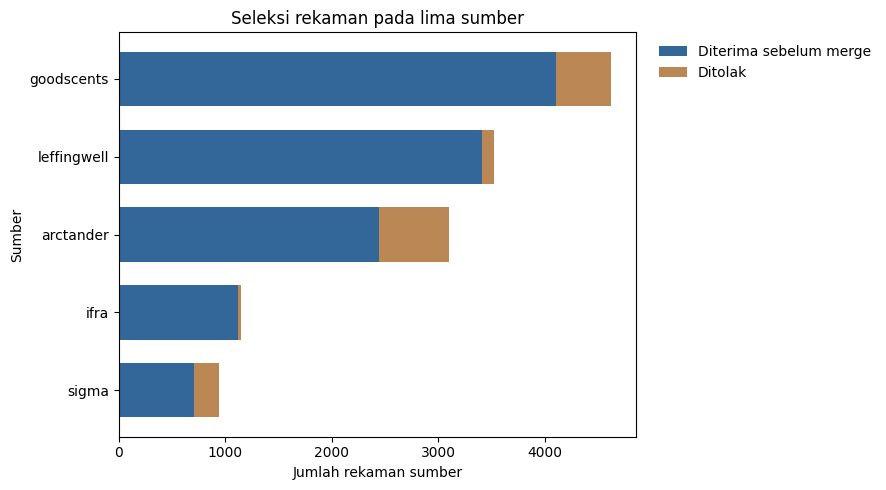

In [4]:
ax = tabel_sumber.sort_values("rows")[["accepted", "ditolak"]].plot.barh(
    stacked=True, color=["#336699", "#bb8855"], width=0.7)
ax.set(title="Seleksi rekaman pada lima sumber", xlabel="Jumlah rekaman sumber", ylabel="Sumber")
ax.set_xlim(left=0)
ax.legend(["Diterima sebelum merge", "Ditolak"], frameon=False,
          loc="upper left", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

<a id="bedah-sel-15"></a>
### Baca barisnya pelan-pelan — Gambar jumlah data dari tiap sumber

**Yang dipakai:** tabel_sumber.  
**Yang kita dapat:** Grafik batang baris yang diterima dan ditolak.

Nomornya mengikuti baris kode tepat di atas. Baris kosong dilewati.

| Baris | Kode | Penjelasan |
|---:|---|---|
| 1 | <code>ax = tabel_sumber.sort_values("rows")[["accepted", "ditolak"]].plot.barh(</code> | Urutkan sumber dari jumlah barisnya. Ambil jumlah diterima dan ditolak untuk grafik batang mendatar. |
| 2 | <code>    stacked=True, color=["#336699", "#bb8855"], width=0.7)</code> | Tumpuk dua bagian batangnya. Atur warna dan lebar batang supaya gampang dibaca. |
| 3 | <code>ax.set(title="Seleksi rekaman pada lima sumber", xlabel="Jumlah rekaman sumber", ylabel="Sumber")</code> | Kasih judul dan nama sumbu. Yang dihitung di sini baris sumber, bukan molekul akhir. |
| 4 | <code>ax.set_xlim(left=0)</code> | Mulai sumbu hitungan dari nol supaya panjang batangnya mudah dibandingkan. |
| 5 | <code>ax.legend(["Diterima sebelum merge", "Ditolak"], frameon=False,</code> | Kasih keterangan arti warna dan hilangkan bingkai keterangannya. |
| 6 | <code>          loc="upper left", bbox_to_anchor=(1.02, 1))</code> | Taruh keterangan warna di luar grafik supaya nggak menutupi batang. |
| 7 | <code>plt.tight_layout()</code> | Rapikan jarak teks dan grafik supaya nggak terpotong. |
| 8 | <code>plt.show()</code> | Tampilkan grafik di notebook. |

**Kalau dosen tanya, kamu bisa bilang:** “Grafik ini cuma menunjukkan proses pemilihan data, belum menunjukkan hasil model.”

**Coba jawab sendiri:** bagian ini membaca apa, melakukan apa, lalu menghasilkan apa?


Cara baca grafiknya: bagian biru adalah baris yang lolos pemeriksaan, sebelum catatan molekul yang sama digabung. Jadi jumlah bagian biru bukan langsung jumlah molekul akhir.


In [5]:
records = pd.read_csv(DATA / "records.csv")
records["labels"] = records["labels"].map(json.loads)
records["sources"] = records["sources"].map(json.loads)
display(records.head(3))
print("Molekul akhir:", len(records))
print("SMILES kosong:", int(records["smiles"].isna().sum()))
print("Duplikat SMILES:", int(records["smiles"].duplicated().sum()))
print("Molekul tercatat di lebih dari satu sumber:", int(records["sources"].map(len).gt(1).sum()))
print("Rekaman diterima yang tergabung:", int(tabel_sumber["accepted"].sum() - len(records)))

,source_row,smiles,labels,sources
0,0,BrC=Cc1ccccc1,"[floral, green, hyacinth, leafy]","[arctander, goodscents]"
1,1,C#CC(C)(O)CCC=C(C)C,"[dry, musk like, sweet, waxy, woody]",[goodscents]
2,2,C#CC(C)CO,"[ethereal, green]",[arctander]


Molekul akhir: 6686
SMILES kosong: 0
Duplikat SMILES: 0
Molekul tercatat di lebih dari satu sumber: 2808
Rekaman diterima yang tergabung: 5091


<a id="bedah-sel-17"></a>
### Baca barisnya pelan-pelan — Buka tabel molekul yang sudah dibersihkan

**Yang dipakai:** records.csv.  
**Yang kita dapat:** Tabel 6686 molekul, label, dan asal sumbernya.

Nomornya mengikuti baris kode tepat di atas. Baris kosong dilewati.

| Baris | Kode | Penjelasan |
|---:|---|---|
| 1 | <code>records = pd.read_csv(DATA / "records.csv")</code> | Baca records.csv. Ini tabel yang sudah dibersihkan dan digabung, dengan satu baris untuk tiap molekul. |
| 2 | <code>records["labels"] = records["labels"].map(json.loads)</code> | Ubah teks daftar label menjadi list Python. Jadi labelnya bisa dihitung satu per satu dengan benar. |
| 3 | <code>records["sources"] = records["sources"].map(json.loads)</code> | Ubah teks daftar sumber menjadi list Python juga. |
| 4 | <code>display(records.head(3))</code> | Tampilkan tiga baris pertama sebagai contoh isi tabel. |
| 5 | <code>print("Molekul akhir:", len(records))</code> | Hitung jumlah baris. Karena satu baris satu molekul, ini jumlah molekul akhirnya. |
| 6 | <code>print("SMILES kosong:", int(records["smiles"].isna().sum()))</code> | Hitung berapa SMILES yang kosong. Ini belum mengecek ulang apakah struktur kimianya valid. |
| 7 | <code>print("Duplikat SMILES:", int(records["smiles"].duplicated().sum()))</code> | Hitung berapa SMILES yang mengulang SMILES sebelumnya. |
| 8 | <code>print("Molekul tercatat di lebih dari satu sumber:", int(records["sources"].map(len).gt(1).sum()))</code> | Hitung molekul yang tercatat di lebih dari satu sumber. map(len) menghitung jumlah sumber, lalu gt(1) mencari yang lebih dari satu. |
| 9 | <code>print("Rekaman diterima yang tergabung:", int(tabel_sumber["accepted"].sum() - len(records)))</code> | Hitung berapa kelebihan baris yang tergabung menjadi molekul yang sama. Baris ini bukan tambahan data yang ditolak. |

**Kalau dosen tanya, kamu bisa bilang:** “Yang digabung itu molekul dengan SMILES kanonik sama, bukan molekul berbeda yang aromanya sama.”

**Coba jawab sendiri:** bagian ini membaca apa, melakukan apa, lalu menghasilkan apa?


### 3.3 Data kosong atau bermasalah diapain?

Kode melewati baris kalau identitasnya belum ketemu, SMILES gagal dibaca, strukturnya punya beberapa komponen, labelnya kosong, isinya salah format, atau istilah aromanya nggak cocok dengan daftar kita.

SMILES yang hilang **nggak diisi pakai tebakan**. File `records.csv` berisi molekul yang sudah lolos dan digabung. Di notebook ini kita tinggal membacanya.


In [6]:
alasan = ["missing_identity", "invalid_smiles", "multifragment", "empty_labels",
          "unmapped_labels", "invalid_behavior"]
display(tabel_sumber[alasan].sum().sort_values(ascending=False).rename("Jumlah ditolak").to_frame())
display(pd.read_csv(DATA / "label_mappings.csv").head(8))

,Jumlah ditolak
unmapped_labels,552
missing_identity,482
multifragment,313
empty_labels,213
invalid_smiles,0
invalid_behavior,0


,source,raw_descriptor,label,method,count
0,arctander,aldehydic,aldehydic,exact,22
1,arctander,almond,almond,exact,27
2,arctander,animal,animal like,alias,73
3,arctander,anisic,anisic,exact,38
4,arctander,apple,apple,exact,64
5,arctander,apricot,apricot,exact,33
6,arctander,aromatic,aromatic,exact,17
7,arctander,balsamic,balsamic,exact,238


<a id="bedah-sel-19"></a>
### Baca barisnya pelan-pelan — Lihat alasan data ditolak

**Yang dipakai:** Catatan pengecekan dan label_mappings.csv.  
**Yang kita dapat:** Jumlah tiap alasan dan contoh padanan istilah aroma.

Nomornya mengikuti baris kode tepat di atas. Baris kosong dilewati.

| Baris | Kode | Penjelasan |
|---:|---|---|
| 1 | <code>alasan = ["missing_identity", "invalid_smiles", "multifragment", "empty_labels",</code> | Mulai daftar alasan kenapa baris data ditolak, misalnya identitas hilang atau SMILES nggak valid. |
| 2 | <code>          "unmapped_labels", "invalid_behavior"]</code> | Tambahkan alasan lain: istilah aroma nggak cocok dan format label nggak valid. |
| 3 | <code>display(tabel_sumber[alasan].sum().sort_values(ascending=False).rename("Jumlah ditolak").to_frame())</code> | Jumlahkan tiap alasan dari semua sumber, urutkan dari yang paling banyak, lalu tampilkan tabelnya. |
| 4 | <code>display(pd.read_csv(DATA / "label_mappings.csv").head(8))</code> | Tampilkan delapan contoh istilah aroma dan padanannya yang sudah disimpan. Kita nggak membuat pemetaan baru di sini. |

**Kalau dosen tanya, kamu bisa bilang:** “Kalau struktur molekulnya nggak diketahui, saya nggak mengisinya dengan tebakan.”

**Coba jawab sendiri:** bagian ini membaca apa, melakukan apa, lalu menghasilkan apa?


### 3.4 Bedakan X dan y dulu

**X adalah angka yang menjelaskan struktur molekul. y adalah label aroma yang tercatat di data.**

Contoh untuk satu molekul:

| Label | Nilai di y | Artinya |
|---|---:|---|
| sweet | 1 | Label sweet tercatat |
| woody | 0 | Label woody tidak tercatat |

**Nol belum tentu berarti aromanya pasti tidak ada.** Bisa saja sumbernya belum mencatat aroma itu.

Daftar IFRA awalnya punya **184 istilah**. Setelah cek jumlah contoh pada train, **109 label** memenuhi aturan dan dipakai model. Pemilihannya nggak berdasarkan hasil test.


In [7]:
manifest = baca_json(DATA / "dataset_manifest.json")
labels = manifest["labels"]
with np.load(DATA / "train.npz", allow_pickle=False) as z:
    y_train = z["truth"].copy()
    train_rows = z["row_index"].astype(int)
with np.load(DATA / "test.npz", allow_pickle=False) as z:
    y_test = z["truth"].copy()
    test_rows = z["row_index"].astype(int)
display(pd.DataFrame(y_train[:5, :8], columns=labels[:8], index=train_rows[:5]))
print("Target train:", y_train.shape, "| test:", y_test.shape, "| tipe:", y_train.dtype)
print("Jumlah istilah kamus:", len(manifest["taxonomy"]), "| target terpilih:", len(labels))
print("Baris train seluruh target nol:", int((y_train.sum(axis=1) == 0).sum()))

,acidic,aldehydic,almond,amber,animal like,anisic,apple,apricot
0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0


Target train: (5353, 109) | test: (1333, 109) | tipe: uint8
Jumlah istilah kamus: 184 | target terpilih: 109
Baris train seluruh target nol: 11


<a id="bedah-sel-21"></a>
### Baca barisnya pelan-pelan — Baca target 0/1 tiap aroma

**Yang dipakai:** File keterangan dataset, train.npz, dan test.npz.  
**Yang kita dapat:** y_train (5353,109), y_test (1333,109), dan nomor baris asal.

Nomornya mengikuti baris kode tepat di atas. Baris kosong dilewati.

| Baris | Kode | Penjelasan |
|---:|---|---|
| 1 | <code>manifest = baca_json(DATA / "dataset_manifest.json")</code> | Buka file keterangan dataset. File ini menyimpan urutan label yang dipakai model. |
| 2 | <code>labels = manifest["labels"]</code> | Ambil daftar 109 label. Urutannya harus sama dengan urutan kolom target. |
| 3 | <code>with np.load(DATA / "train.npz", allow_pickle=False) as z:</code> | Buka train.npz, file NumPy berisi data train. allow_pickle=False berarti file ini dibaca sebagai array biasa, tanpa memuat objek pickle. |
| 4 | <code>    y_train = z["truth"].copy()</code> | Ambil salinan target train: 5353 baris molekul dan 109 kolom aroma. |
| 5 | <code>    train_rows = z["row_index"].astype(int)</code> | Ambil nomor baris asal tiap molekul train dari records. astype(int) membuat nomornya jadi bilangan bulat. |
| 6 | <code>with np.load(DATA / "test.npz", allow_pickle=False) as z:</code> | Buka test.npz yang sudah ada. Kita cuma membaca hasil pembagian data. |
| 7 | <code>    y_test = z["truth"].copy()</code> | Ambil salinan target test: 1333 baris molekul dan 109 kolom aroma. |
| 8 | <code>    test_rows = z["row_index"].astype(int)</code> | Ambil nomor baris asal tiap molekul test. Nomor ini menjaga fitur dan target tetap berpasangan dengan benar. |
| 9 | <code>display(pd.DataFrame(y_train[:5, :8], columns=labels[:8], index=train_rows[:5]))</code> | Tampilkan lima molekul dan delapan label pertama. Isinya target 0 atau 1. |
| 10 | <code>print("Target train:", y_train.shape, "&#124; test:", y_test.shape, "&#124; tipe:", y_train.dtype)</code> | Tampilkan jumlah baris, jumlah kolom, dan tipe angka target. |
| 11 | <code>print("Jumlah istilah kamus:", len(manifest["taxonomy"]), "&#124; target terpilih:", len(labels))</code> | Tampilkan jumlah istilah kamus IFRA dan jumlah label yang lolos aturan pada train. |
| 12 | <code>print("Baris train seluruh target nol:", int((y_train.sum(axis=1) == 0).sum()))</code> | Hitung molekul train yang semua targetnya nol setelah label dipilih. Ini bukan berarti SMILES-nya kosong. |

**Kalau dosen tanya, kamu bisa bilang:** “Angka 1 berarti aroma tercatat di dataset. Angka 0 berarti nggak tercatat, belum tentu aromanya benar-benar nggak ada.”

**Coba jawab sendiri:** bagian ini membaca apa, melakukan apa, lalu menghasilkan apa?


Satu molekul bisa punya label di `records`, tapi semua targetnya jadi nol setelah kita hanya mengambil 109 label terpilih. Itu artinya label miliknya ada di bagian yang tidak dipakai, bukan SMILES-nya kosong.

### 3.5 Kenapa accuracy saja belum cukup?

Ada aroma yang sering muncul dan ada yang jarang. Kalau sebuah aroma jarang tercatat, model yang sering menjawab “tidak” bisa terlihat punya accuracy tinggi, padahal belum bisa menemukan contoh positifnya.


,Molekul positif train
rooty,32
popcorn,34
narcissus,34
celery,34
raspberry,35
neroli,35
marine,35
acidic,36


Min/median/max positif: 32 100.0 1987


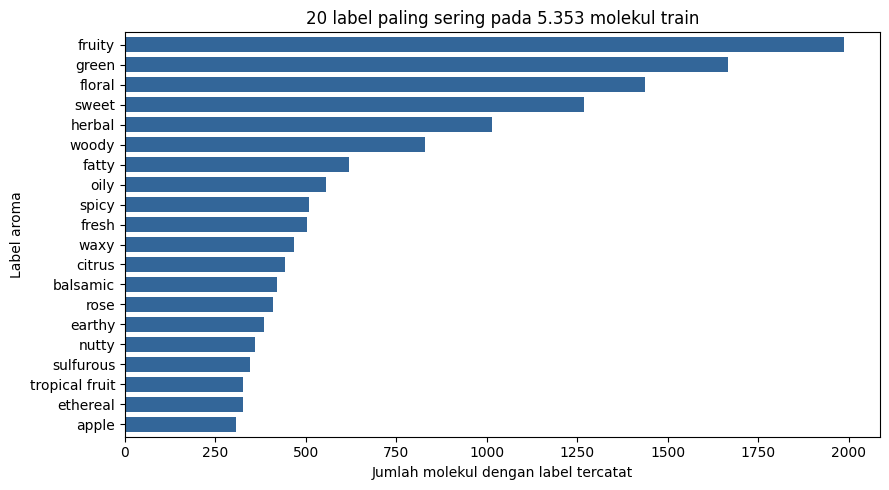

In [8]:
dukungan = pd.Series(y_train.sum(axis=0), index=labels, name="Molekul positif train").sort_values()
display(dukungan.head(8).to_frame())
print("Min/median/max positif:", int(dukungan.min()), float(dukungan.median()), int(dukungan.max()))
ax = dukungan.tail(20).plot.barh(color="#336699", width=0.75)
ax.set(title="20 label paling sering pada 5.353 molekul train",
       xlabel="Jumlah molekul dengan label tercatat", ylabel="Label aroma")
ax.set_xlim(left=0)
plt.tight_layout()
plt.show()

<a id="bedah-sel-23"></a>
### Baca barisnya pelan-pelan — Hitung aroma yang sering dan jarang tercatat

**Yang dipakai:** y_train dan nama label.  
**Yang kita dapat:** Hitungan tiap aroma dan grafik 20 aroma paling sering.

Nomornya mengikuti baris kode tepat di atas. Baris kosong dilewati.

| Baris | Kode | Penjelasan |
|---:|---|---|
| 1 | <code>dukungan = pd.Series(y_train.sum(axis=0), index=labels, name="Molekul positif train").sort_values()</code> | Hitung jumlah angka 1 pada setiap kolom aroma. Pasangkan dengan nama aromanya, lalu urutkan dari yang paling sedikit. |
| 2 | <code>display(dukungan.head(8).to_frame())</code> | Tampilkan delapan aroma yang paling jarang tercatat pada train. |
| 3 | <code>print("Min/median/max positif:", int(dukungan.min()), float(dukungan.median()), int(dukungan.max()))</code> | Tampilkan jumlah positif paling sedikit, nilai tengah, dan paling banyak. Ini membantu melihat label yang jumlahnya timpang. |
| 4 | <code>ax = dukungan.tail(20).plot.barh(color="#336699", width=0.75)</code> | Bikin grafik untuk 20 label yang paling sering tercatat pada train. |
| 5 | <code>ax.set(title="20 label paling sering pada 5.353 molekul train",</code> | Kasih judul yang menjelaskan bahwa grafik ini memakai 5.353 molekul train. |
| 6 | <code>       xlabel="Jumlah molekul dengan label tercatat", ylabel="Label aroma")</code> | Kasih nama sumbu: jumlah molekul dan nama aroma. |
| 7 | <code>ax.set_xlim(left=0)</code> | Mulai sumbu hitungan dari nol. |
| 8 | <code>plt.tight_layout()</code> | Rapikan jarak gambar dan teks. |
| 9 | <code>plt.show()</code> | Tampilkan grafik. Sampai sini kita belum melatih model. |

**Kalau dosen tanya, kamu bisa bilang:** “Ada aroma yang datanya banyak, ada yang sedikit. Jadi saya nggak menilai model dari accuracy saja.”

**Coba jawab sendiri:** bagian ini membaca apa, melakukan apa, lalu menghasilkan apa?


Dari tabel tadi, kita bisa lihat jumlah contoh tiap aroma beda-beda. Untuk aroma langka, contoh belajarnya lebih sedikit.

**Coba pikirkan:** kalau sweet tercatat pada dua molekul yang strukturnya berbeda, apa itu data duplikat? Nggak. Yang dicek saat menggabungkan molekul adalah identitas strukturnya, bukan kesamaan nama aromanya.


<a id="fitur"></a>
## 4. SMILES diubah jadi angka

ML kita nggak langsung membaca huruf-huruf SMILES. **RDKit membaca strukturnya dulu, lalu menghitung angka Morgan dan deskriptor.**

Contoh di `01_fitur.py` memakai vanilin. Kalau file dijalankan dari terminal, `--smiles` dipakai untuk mengisi SMILES yang mau dicoba.


**Kode aktif:** [KODE_ML/01_fitur.py](01_fitur.py). Blok ini bahan baca; Run All tidak menjalankan isinya.

```python
"""SMILES -> Morgan 2048 + delapan deskriptor; demonstrasi satu molekul."""

import argparse
import sys

import numpy as np

from _lokasi import ROOT

sys.path.insert(0, str(ROOT))
from research.features import DESCRIPTORS8, calculate, calculate_morgan  # noqa: E402
from research.experiment import features  # noqa: E402


def periksa_fitur(smiles: str) -> None:
    morgan = calculate_morgan([smiles])
    deskriptor = calculate([smiles])
    print(f"SMILES: {smiles}")
    print(f"Morgan: {morgan.shape[1]} bit biner; bit aktif: {int(morgan.sum())}")
    for nama, nilai in zip(DESCRIPTORS8, deskriptor[0]):
        print(f"  {nama:<20} {float(nilai):.4f}")
    print(f"A/C: {features('xgb_A', morgan, deskriptor).shape[1]} fitur")
    print(f"B/D: {features('xgb_D', morgan, deskriptor).shape[1]} fitur")
    assert np.isin(morgan, [0, 1]).all()


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--smiles", default="COc1cc(C=O)ccc1O", help="Satu molekul valid; default vanilin")
    periksa_fitur(parser.parse_args().smiles)
```

<a id="bedah-source-26-0"></a>
### Kode ini ngapain? — KODE_ML/01_fitur.py

**Ini bahan baca.** Kode panjang di atas ditampilkan sebagai teks. Kode training di situ nggak ikut jalan saat menekan Run All.

**File aslinya:** [KODE_ML/01_fitur.py](<01_fitur.py>), mulai **baris 1** di file asli. Nomor tabel mengikuti file itu.

| Fungsi | Buat apa? |
|---|---|
| `periksa_fitur` | Demonstrasi fitur, bukan fitting XGBoost meski kunci xgb_A dipakai. |

| Baris | Kode | Maksudnya |
|---:|---|---|
| 1 | <code>"""SMILES -&gt; Morgan 2048 + delapan deskriptor; demonstrasi satu molekul."""</code> | Ini catatan singkat tentang fungsi atau file. Teks ini membantu pembaca; bukan perintah training. |
| 3 | <code>import argparse</code> | Siapkan `argparse`: alat untuk membaca pilihan dari terminal, misalnya --smiles atau --run. |
| 4 | <code>import sys</code> | Siapkan `sys`: alat dari `sys` yang dipakai baris berikutnya. |
| 6 | <code>import numpy as np</code> | Siapkan `numpy sebagai np`: alat untuk mengolah array, yaitu kumpulan nilai seperti fitur, target, dan skor. |
| 8 | <code>from _lokasi import ROOT</code> | Ambil `ROOT` dari file proyek `_lokasi` supaya bisa dipakai di file ini. Mengambil fungsi belum menjalankan isinya. |
| 10 | <code>sys.path.insert(0, str(ROOT))</code> | Menyisipkan elemen pada urutan yang ditentukan, misalnya kolom tabel atau sys.path melalui `sys.path.insert`. |
| 11 | <code>from research.features import DESCRIPTORS8, calculate, calculate_morgan  # noqa: E402</code> | Ambil `DESCRIPTORS8, calculate, calculate_morgan` dari file proyek `research.features` supaya bisa dipakai di file ini. Mengambil fungsi belum menjalankan isinya. |
| 12 | <code>from research.experiment import features  # noqa: E402</code> | Ambil `features` dari file proyek `research.experiment` supaya bisa dipakai di file ini. Mengambil fungsi belum menjalankan isinya. |
| 15 | <code>def periksa_fitur(smiles: str) -&gt; None:</code> | Bikin fungsi `periksa_fitur` yang menerima `smiles`. isinya baru jalan saat fungsi ini dipanggil. Yang masuk: satu SMILES. Yang keluar: tampilan fingerprint, delapan deskriptor, dan dimensi A–D. |
| 16 | <code>    morgan = calculate_morgan([smiles])</code> | Menjalankan `calculate_morgan`: daftar SMILES → array uint8 (N,2048) fingerprint biner. Simpan hasilnya ke `morgan`. |
| 17 | <code>    deskriptor = calculate([smiles])</code> | Menjalankan `calculate`: daftar SMILES → array float32 (N,8) delapan deskriptor. Simpan hasilnya ke `deskriptor`. |
| 18 | <code>    print(f"SMILES: {smiles}")</code> | Tampilkan nilai di output/terminal. nggak menulis file hasil eksperimen tersendiri. |
| 19 | <code>    print(f"Morgan: {morgan.shape[1]} bit biner; bit aktif: {int(morgan.sum())}")</code> | Tampilkan nilai di output/terminal. nggak menulis file hasil eksperimen tersendiri. |
| 20 | <code>    for nama, nilai in zip(DESCRIPTORS8, deskriptor[0]):</code> | Ulangi untuk `zip(DESCRIPTORS8, deskriptor[0])`, simpan anggota yang sedang dibaca ke `(nama, nilai)`. Kode yang menjorok dijalankan untuk tiap anggota. |
| 21 | <code>        print(f"  {nama:&lt;20} {float(nilai):.4f}")</code> | Tampilkan nilai di output/terminal. nggak menulis file hasil eksperimen tersendiri. |
| 22 | <code>    print(f"A/C: {features('xgb_A', morgan, deskriptor).shape[1]} fitur")</code> | Tampilkan nilai di output/terminal. nggak menulis file hasil eksperimen tersendiri. |
| 23 | <code>    print(f"B/D: {features('xgb_D', morgan, deskriptor).shape[1]} fitur")</code> | Tampilkan nilai di output/terminal. nggak menulis file hasil eksperimen tersendiri. |
| 24 | <code>    assert np.isin(morgan, [0, 1]).all()</code> | Pastikan mengecek semua nilai True/False True melalui `np.isin(morgan, [0, 1]).all`. Kalau syaratnya salah, contoh berhenti. Kode ini nggak memperbaiki datanya sendiri. |
| 27 | <code>if __name__ == "__main__":</code> | Jalankan bagian ini kalau hasil pengecekannya menunjukkan `__name__ sama dengan '__main__'`. |
| 28 | <code>    parser = argparse.ArgumentParser(description=__doc__)</code> | Membuat parser isian fungsi terminal dari deskripsi modul melalui `argparse.ArgumentParser`. Simpan hasilnya ke `parser`. |
| 29 | <code>    parser.add_argument("--smiles", default="COc1cc(C=O)ccc1O", help="Satu molekul valid; default vanilin")</code> | Mendaftarkan opsi terminal, tipe nilai, dan nilai default melalui `parser.add_argument`. |
| 30 | <code>    periksa_fitur(parser.parse_args().smiles)</code> | Jalankan `periksa_fitur`: satu SMILES → tampilan fingerprint, delapan deskriptor, dan dimensi A–D. |

**Kalau dosen menunjuk satu baris:** mulai dari fungsi apa yang sedang dibaca. Lalu jelaskan data yang masuk, baris itu ngapain, dan hasilnya dipakai di mana.

### 4.1 RDKit ngapain di sini?

RDKit membaca SMILES sebagai susunan **atom dan ikatan**. Dari struktur yang sama, kita menghitung:

- **Morgan:** 2.048 posisi angka 0/1 yang merangkum pola di sekitar atom. Radius 2 artinya melihat lingkungan sampai dua ikatan dari atom. Pengaturan kita tidak memasukkan informasi kiralitas, yaitu perbedaan susunan ruang tertentu pada molekul.
- **Deskriptor:** delapan angka yang merangkum sifat molekul. Nama yang dihitung sudah kita tentukan, bukan dipilih otomatis oleh RDKit.

| Nama di kode | Maksud sederhananya |
|---|---|
| MolWt | Berat molekul |
| MolLogP | Perkiraan kecenderungan molekul berada di lingkungan seperti lemak dibanding air |
| NumHDonors | Jumlah bagian molekul yang bisa menjadi donor ikatan hidrogen |
| NumHAcceptors | Jumlah bagian molekul yang bisa menerima ikatan hidrogen |
| TPSA | Ukuran luas bagian permukaan molekul yang bersifat polar, dihitung dari struktur |
| NumRotatableBonds | Jumlah ikatan yang bisa berputar menurut aturan RDKit |
| HeavyAtomCount | Jumlah atom selain hidrogen |
| RingCount | Jumlah cincin pada struktur |

Morgan **bukan** huruf SMILES yang sekadar diubah menjadi kode biner komputer.


**Kode aktif:** [research/features.py](../research/features.py), fungsi `calculate_morgan`. Blok ini bahan baca; Run All tidak menjalankan isinya.

```python
def calculate_morgan(smiles):
    generator = rdFingerprintGenerator.GetMorganGenerator(
        radius=RADIUS, fpSize=N_BITS, includeChirality=False)
    return np.asarray([generator.GetFingerprintAsNumPy(molecule(smi, i))
                       for i, smi in enumerate(smiles)], dtype=np.uint8)
```

<a id="bedah-source-28-0"></a>
### Baca kode ini pelan-pelan — research/features.py

**Di sini kita cuma baca potongan kodenya.** Kode di atas ditulis sebagai teks Markdown, jadi tombol Run All nggak menjalankan training dari potongan itu.

**File aslinya:** [research/features.py](<../research/features.py>), mulai **baris 29** di file asli. Angka di tabel bawah mengikuti nomor baris file itu.

| Fungsi | Yang masuk | Yang keluar | Gampangnya |
|---|---|---|---|
| `calculate_morgan` | Daftar SMILES | 2.048 angka 0/1 untuk tiap molekul | Bit ini merangkum struktur, bukan nama atau jumlah aroma. |

| Baris | Kode | Maksudnya |
|---:|---|---|
| 29 | <code>def calculate_morgan(smiles):</code> | Bikin fungsi untuk mengubah daftar SMILES jadi fingerprint Morgan. Satu molekul nanti punya 2.048 angka 0/1. |
| 30 | <code>    generator = rdFingerprintGenerator.GetMorganGenerator(</code> | Siapkan alat penghitung Morgan dari RDKit. Aturannya ditulis di baris berikutnya. |
| 31 | <code>        radius=RADIUS, fpSize=N_BITS, includeChirality=False)</code> | Lihat lingkungan tiap atom sampai dua ikatan, pakai 2.048 posisi, dan abaikan info kiralitas. Aturan fitur ini sudah ditetapkan; Optuna nggak mengubahnya. |
| 32 | <code>    return np.asarray([generator.GetFingerprintAsNumPy(molecule(smi, i))</code> | Baca dan cek satu SMILES lewat molecule(), lalu hitung Morgan-nya. Hasil tiap molekul mulai dikumpulkan jadi satu tabel angka. |
| 33 | <code>                       for i, smi in enumerate(smiles)], dtype=np.uint8)</code> | Ulangi untuk semua SMILES. i adalah nomor baris dan smi adalah teks SMILES-nya. Simpan hasil sebagai uint8, yaitu tipe bilangan bulat kecil. Bentuk akhirnya (jumlah molekul, 2048). |

**Kalau ditanya dosen, kamu bisa bilang:** “SMILES dibaca RDKit, lalu diubah jadi Morgan 2.048 bit. Angka 1 menandai ada pola struktur yang masuk ke posisi bit itu.”

**Coba cek pemahamanmu:** pilih satu baris. Jelaskan data apa yang dipakai, apa yang dilakukan, dan hasilnya dipakai ke mana.


**Kode aktif:** [research/features.py](../research/features.py), fungsi `calculate`. Blok ini bahan baca; Run All tidak menjalankan isinya.

```python
def calculate(smiles):
    values = np.empty((len(smiles), 8), dtype=np.float32)
    for i, value in enumerate(smiles):
        mol = molecule(value, i)
        values[i] = [getattr(Descriptors, name)(mol) for name in DESCRIPTORS8]
    if not np.isfinite(values).all():
        raise ValueError("Nonfinite descriptors; no silent imputation.")
    return values
```

<a id="bedah-source-29-0"></a>
### Baca kode ini pelan-pelan — research/features.py

**Di sini kita cuma baca potongan kodenya.** Kode di atas ditulis sebagai teks Markdown, jadi tombol Run All nggak menjalankan training dari potongan itu.

**File aslinya:** [research/features.py](<../research/features.py>), mulai **baris 19** di file asli. Angka di tabel bawah mengikuti nomor baris file itu.

| Fungsi | Yang masuk | Yang keluar | Gampangnya |
|---|---|---|---|
| `calculate` | Daftar SMILES | Delapan angka sifat molekul untuk tiap SMILES | Delapan nama deskriptor dipilih sebelumnya. RDKit tinggal menghitung nilainya. |

| Baris | Kode | Maksudnya |
|---:|---|---|
| 19 | <code>def calculate(smiles):</code> | Bikin fungsi untuk menghitung delapan deskriptor dari daftar SMILES. |
| 20 | <code>    values = np.empty((len(smiles), 8), dtype=np.float32)</code> | Siapkan tempat dengan delapan kolom untuk tiap molekul. Isinya belum dihitung. float32 adalah tipe penyimpanan angka desimal. |
| 21 | <code>    for i, value in enumerate(smiles):</code> | Ambil SMILES satu per satu. i menyimpan nomor baris, value menyimpan SMILES yang sedang dibaca. |
| 22 | <code>        mol = molecule(value, i)</code> | Ubah SMILES itu jadi molekul RDKit dan cek apakah strukturnya valid serta cuma satu komponen. Kalau gagal, proses berhenti. |
| 23 | <code>        values[i] = [getattr(Descriptors, name)(mol) for name in DESCRIPTORS8]</code> | Ambil delapan nama deskriptor dari DESCRIPTORS8. Untuk tiap nama, getattr mengambil fungsi RDKit yang sesuai, lalu fungsi itu menghitung nilainya dari mol. |
| 24 | <code>    if not np.isfinite(values).all():</code> | Cek apakah ada hasil yang kosong (NaN) atau tak terbatas (infinity). Semua deskriptor harus berupa angka yang bisa dipakai model. |
| 25 | <code>        raise ValueError("Nonfinite descriptors; no silent imputation.")</code> | Kalau ada angka bermasalah, hentikan proses dan tampilkan pesan error. Kode nggak mengisi angka pengganti diam-diam. |
| 26 | <code>    return values</code> | Kirim kembali tabel delapan deskriptor yang sudah dihitung. Kalau masuk satu SMILES, bentuknya (1, 8). |

**Kalau ditanya dosen, kamu bisa bilang:** “Saya menghitung delapan sifat molekul dengan fungsi RDKit yang sudah dipilih. Satu molekul menghasilkan delapan angka.”

**Coba cek pemahamanmu:** pilih satu baris. Jelaskan data apa yang dipakai, apa yang dilakukan, dan hasilnya dipakai ke mana.


In [9]:
from research.features import DESCRIPTORS8, calculate, calculate_morgan
from research.experiment import features

SMILES_CONTOH = "COc1cc(C=O)ccc1O"
morgan_contoh = calculate_morgan([SMILES_CONTOH])
deskriptor_contoh = calculate([SMILES_CONTOH])
display(pd.DataFrame(deskriptor_contoh, columns=DESCRIPTORS8))
print("SMILES:", SMILES_CONTOH)
print("Morgan:", morgan_contoh.shape, morgan_contoh.dtype)
print("Bit aktif:", int(morgan_contoh.sum()))
print("40 posisi pertama:", morgan_contoh[0, :40].tolist())
assert np.isin(morgan_contoh, [0, 1]).all()

C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,MolWt,MolLogP,NumHDonors,NumHAcceptors,TPSA,NumRotatableBonds,HeavyAtomCount,RingCount
0,152.149002,1.2133,1.0,3.0,46.529999,2.0,11.0,1.0


SMILES: COc1cc(C=O)ccc1O
Morgan: (1, 2048) uint8
Bit aktif: 25
40 posisi pertama: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


<a id="bedah-sel-30"></a>
### Baca barisnya pelan-pelan — Ubah satu SMILES jadi angka

**Yang dipakai:** SMILES vanilin.  
**Yang kita dapat:** Morgan (1,2048) dan deskriptor (1,8).

Nomornya mengikuti baris kode tepat di atas. Baris kosong dilewati.

| Baris | Kode | Penjelasan |
|---:|---|---|
| 1 | <code>from research.features import DESCRIPTORS8, calculate, calculate_morgan</code> | Ambil daftar delapan deskriptor serta fungsi penghitung fitur dari kode proyek yang memakai RDKit. |
| 2 | <code>from research.experiment import features</code> | Ambil fungsi features, yang menyusun kolom fitur sesuai skenario A/B/C/D. |
| 4 | <code>SMILES_CONTOH = "COc1cc(C=O)ccc1O"</code> | Simpan SMILES vanilin sebagai contoh. Ini tulisan struktur molekulnya. |
| 5 | <code>morgan_contoh = calculate_morgan([SMILES_CONTOH])</code> | Hitung Morgan vanilin. Hasilnya satu baris berisi 2048 angka 0 atau 1. |
| 6 | <code>deskriptor_contoh = calculate([SMILES_CONTOH])</code> | Hitung delapan deskriptor vanilin. Hasilnya satu baris berisi delapan angka sifat molekul. |
| 7 | <code>display(pd.DataFrame(deskriptor_contoh, columns=DESCRIPTORS8))</code> | Tampilkan angka deskriptor dengan nama kolomnya, supaya kita tahu tiap angka itu apa. |
| 8 | <code>print("SMILES:", SMILES_CONTOH)</code> | Tampilkan SMILES yang dipakai pada contoh. |
| 9 | <code>print("Morgan:", morgan_contoh.shape, morgan_contoh.dtype)</code> | Tampilkan ukuran dan tipe angka Morgan. uint8 adalah tipe bilangan bulat kecil. |
| 10 | <code>print("Bit aktif:", int(morgan_contoh.sum()))</code> | Hitung berapa posisi Morgan yang bernilai 1. Pada contoh yang tersimpan jumlahnya 25; ini bukan 25 aroma. |
| 11 | <code>print("40 posisi pertama:", morgan_contoh[0, :40].tolist())</code> | Tampilkan 40 posisi awal Morgan. [0, :40] artinya baris pertama, posisi 0 sampai 39. |
| 12 | <code>assert np.isin(morgan_contoh, [0, 1]).all()</code> | Pastikan semua nilai Morgan hanya 0 atau 1. Kalau ada nilai lain, assert menghentikan contoh. |

**Kalau dosen tanya, kamu bisa bilang:** “RDKit membaca struktur molekulnya. Morgan bukan karakter SMILES yang diubah jadi angka ASCII.”

**Coba jawab sendiri:** bagian ini membaca apa, melakukan apa, lalu menghasilkan apa?


`[SMILES_CONTOH]` itu daftar berisi **satu molekul**. Makanya hasilnya punya satu baris.

**Bit aktif** adalah posisi Morgan yang bernilai 1. Kalau ada 25 bit aktif, itu bukan berarti ada 25 aroma atau 25 atom.

### 4.2 Kenapa ada A, B, C, D?

Kita mengubah dua hal: **fiturnya** dan **pengaturan modelnya**.

| Skenario | Angka yang masuk | Pengaturan model |
|---|---|---|
| A | Morgan 2048 | Pengaturan pembanding, 100 pohon |
| B | Morgan 2048 + 8 deskriptor | Pengaturan pembanding, 100 pohon |
| C | Morgan 2048 | Dicari pakai Optuna |
| D | Morgan 2048 + 8 deskriptor | Dicari pakai Optuna |

Masing-masing dicoba di XGBoost dan LightGBM. Jadi ada **8 kandidat**. Di sini “kandidat” artinya satu kombinasi algoritma dan skenario, misalnya LightGBM D.

Baseline artinya model pembanding awal. Baseline kita tetap memakai aturan lain pada kode, termasuk bobot kelas; bukan meniru seluruh eksperimen Suh.


**Kode aktif:** [research/features.py](../research/features.py), fungsi `features`. Blok ini bahan baca; Run All tidak menjalankan isinya.

```python
def features(key, morgan, descriptors):
    if (morgan.ndim != 2 or morgan.shape[1] != N_BITS or descriptors.shape != (len(morgan), 8)
            or not np.isfinite(descriptors).all()):
        raise ValueError("Expected Morgan 2048 and eight ordered descriptors per molecular row.")
    return np.column_stack([morgan, descriptors[:, :descriptor_count(key)]]).astype(np.float32)
```

<a id="bedah-source-32-0"></a>
### Baca kode ini pelan-pelan — research/features.py

**Di sini kita cuma baca potongan kodenya.** Kode di atas ditulis sebagai teks Markdown, jadi tombol Run All nggak menjalankan training dari potongan itu.

**File aslinya:** [research/features.py](<../research/features.py>), mulai **baris 41** di file asli. Angka di tabel bawah mengikuti nomor baris file itu.

| Fungsi | Yang masuk | Yang keluar | Gampangnya |
|---|---|---|---|
| `features` | Morgan, deskriptor, dan nama skenario | Tabel fitur yang siap masuk model | A/C punya 2.048 kolom. B/D punya 2.056 kolom. Target aroma nggak ikut dijadikan fitur. |

| Baris | Kode | Maksudnya |
|---:|---|---|
| 41 | <code>def features(key, morgan, descriptors):</code> | Bikin fungsi yang menyiapkan fitur sesuai skenario A, B, C, atau D. key berisi nama seperti lgbm_D. |
| 42 | <code>    if (morgan.ndim != 2 or morgan.shape[1] != N_BITS or descriptors.shape != (len(morgan), 8)</code> | Cek bentuk data: Morgan harus punya 2.048 kolom, dan tiap molekul harus punya delapan deskriptor. |
| 43 | <code>            or not np.isfinite(descriptors).all()):</code> | Lanjutkan pengecekan: semua deskriptor harus angka biasa, bukan NaN atau infinity. |
| 44 | <code>        raise ValueError("Expected Morgan 2048 and eight ordered descriptors per molecular row.")</code> | Kalau jumlah kolom atau nilainya salah, hentikan proses. Ini mencegah model menerima susunan fitur yang keliru. |
| 45 | <code>    return np.column_stack([morgan, descriptors[:, :descriptor_count(key)]]).astype(np.float32)</code> | Untuk A/C, ambil Morgan saja. Untuk B/D, tambahkan delapan deskriptor di sebelah kanannya. Simpan sebagai float32. Nilai bit Morgan tetap 0 atau 1. |

**Kalau ditanya dosen, kamu bisa bilang:** “Fungsi ini cuma menyusun fitur. A/C memakai Morgan, sedangkan B/D menambahkan delapan deskriptor.”

**Coba cek pemahamanmu:** pilih satu baris. Jelaskan data apa yang dipakai, apa yang dilakukan, dan hasilnya dipakai ke mana.


In [10]:
for kondisi in "ABCD":
    x_contoh = features(f"lgbm_{kondisi}", morgan_contoh, deskriptor_contoh)
    print(f"Kondisi {kondisi}: {x_contoh.shape}, tipe {x_contoh.dtype}")
print("Contoh delapan kolom terakhir D:", x_contoh[0, -8:].tolist())

Kondisi A: (1, 2048), tipe float32
Kondisi B: (1, 2056), tipe float32
Kondisi C: (1, 2048), tipe float32
Kondisi D: (1, 2056), tipe float32
Contoh delapan kolom terakhir D: [152.1490020751953, 1.2132999897003174, 1.0, 3.0, 46.529998779296875, 2.0, 11.0, 1.0]


<a id="bedah-sel-33"></a>
### Baca barisnya pelan-pelan — Lihat beda fitur A/B/C/D

**Yang dipakai:** Morgan dan deskriptor satu molekul.  
**Yang kita dapat:** A/C punya 2048 kolom, B/D punya 2056 kolom.

Nomornya mengikuti baris kode tepat di atas. Baris kosong dilewati.

| Baris | Kode | Penjelasan |
|---:|---|---|
| 1 | <code>for kondisi in "ABCD":</code> | Coba skenario A, B, C, dan D satu per satu untuk melihat susunan fiturnya. |
| 2 | <code>    x_contoh = features(f"lgbm_{kondisi}", morgan_contoh, deskriptor_contoh)</code> | Susun fitur sesuai skenario. Nama lgbm di sini cuma memilih susunan fitur, belum melatih model. |
| 3 | <code>    print(f"Kondisi {kondisi}: {x_contoh.shape}, tipe {x_contoh.dtype}")</code> | Tampilkan ukuran dan tipe angkanya. A/C punya 2048 kolom, B/D punya 2056 kolom, semuanya float32. |
| 4 | <code>print("Contoh delapan kolom terakhir D:", x_contoh[0, -8:].tolist())</code> | Setelah perulangan selesai, x_contoh berisi skenario D. Tampilkan delapan angka paling belakang, yaitu deskriptornya. |

**Kalau dosen tanya, kamu bisa bilang:** “Empat skenario dipakai untuk membandingkan tambahan fitur dan pencarian pengaturan model.”

**Coba jawab sendiri:** bagian ini membaca apa, melakukan apa, lalu menghasilkan apa?


`np.column_stack` menempelkan kolom di sebelah kanan. Jadi Morgan 2048 kolom ditambah 8 kolom deskriptor menjadi **2056 kolom**.

Tipe angkanya dibuat `float32`. Angka Morgan bisa terlihat sebagai 0.0 dan 1.0, tapi nilainya tetap 0 dan 1.

### 4.3 Jangan salah ambil file fitur

Fitur utama **2048+8** ada di `FITUR/features.npz`. File `train.npz` dan `test.npz` masih menyimpan fitur versi dasar 1024+5. Kita memakai nomor baris yang disimpan untuk memasangkan fitur utama dengan target yang benar.


In [11]:
with np.load(FITUR / "features.npz", allow_pickle=False) as z:
    morgan_semua = z["morgan"].copy()
    deskriptor_semua = z["descriptors"].copy()
    indeks_fitur = z["row_index"].copy()
    nama_deskriptor = z["names"].tolist()
assert nama_deskriptor == list(DESCRIPTORS8)
assert np.array_equal(indeks_fitur, np.arange(len(records)))
x_train_d = features("lgbm_D", morgan_semua[train_rows], deskriptor_semua[train_rows])
print("Morgan semua:", morgan_semua.shape)
print("Deskriptor semua:", deskriptor_semua.shape)
print("X train D:", x_train_d.shape, "| y train:", y_train.shape)

Morgan semua: (6686, 2048)
Deskriptor semua: (6686, 8)
X train D: (5353, 2056) | y train: (5353, 109)


<a id="bedah-sel-35"></a>
### Baca barisnya pelan-pelan — Baca fitur seluruh molekul

**Yang dipakai:** features.npz dan nomor baris train.  
**Yang kita dapat:** X train D berukuran (5353,2056).

Nomornya mengikuti baris kode tepat di atas. Baris kosong dilewati.

| Baris | Kode | Penjelasan |
|---:|---|---|
| 1 | <code>with np.load(FITUR / "features.npz", allow_pickle=False) as z:</code> | Buka file fitur utama 2048+8. Fitur ini disimpan terpisah dari fitur lama yang masih ada di train.npz/test.npz. |
| 2 | <code>    morgan_semua = z["morgan"].copy()</code> | Ambil seluruh Morgan: 6686 molekul, masing-masing 2048 posisi bit. |
| 3 | <code>    deskriptor_semua = z["descriptors"].copy()</code> | Ambil seluruh deskriptor: 6686 molekul, masing-masing delapan angka. |
| 4 | <code>    indeks_fitur = z["row_index"].copy()</code> | Ambil nomor baris fitur supaya urutan molekulnya bisa dicek. |
| 5 | <code>    nama_deskriptor = z["names"].tolist()</code> | Ambil daftar nama deskriptor dan ubah menjadi list Python. |
| 6 | <code>assert nama_deskriptor == list(DESCRIPTORS8)</code> | Pastikan nama dan urutan delapan deskriptor sama dengan aturan kita. Urutan yang ketukar bisa membuat input model salah. |
| 7 | <code>assert np.array_equal(indeks_fitur, np.arange(len(records)))</code> | Pastikan nomor barisnya berurutan dari 0 sampai jumlah molekul−1. Jadi fitur nggak tertukar dengan target molekul lain. |
| 8 | <code>x_train_d = features("lgbm_D", morgan_semua[train_rows], deskriptor_semua[train_rows])</code> | Ambil fitur milik molekul train, lalu gabungkan Morgan dan deskriptor untuk skenario D. Hasilnya (5353, 2056). |
| 9 | <code>print("Morgan semua:", morgan_semua.shape)</code> | Tampilkan ukuran seluruh Morgan. |
| 10 | <code>print("Deskriptor semua:", deskriptor_semua.shape)</code> | Tampilkan ukuran seluruh deskriptor. |
| 11 | <code>print("X train D:", x_train_d.shape, "&#124; y train:", y_train.shape)</code> | Tampilkan ukuran X dan y train. Barisnya sama-sama 5353, tapi X punya 2056 fitur dan y punya 109 label. |

**Kalau dosen tanya, kamu bisa bilang:** “Nomor baris memastikan fitur molekul A nggak tertukar dengan target molekul B.”

**Coba jawab sendiri:** bagian ini membaca apa, melakukan apa, lalu menghasilkan apa?


**Coba jawab:** kenapa X punya 2056 kolom, tapi y cuma 109?

Karena kolom X menjelaskan struktur, sedangkan kolom y menjelaskan label aroma. Jumlah molekulnya tetap sama, jadi jumlah barisnya harus cocok.


<a id="split"></a>
## 5. Data mana buat latihan, validasi, dan test?

`02_split.py` membaca pembagian yang sudah disimpan. Kita cek apakah ada kelompok yang muncul di dua sisi, lalu melihat contoh lima fold untuk satu aroma. Script ini nggak mengacak ulang semua data.


**Kode aktif:** [KODE_ML/02_split.py](02_split.py). Blok ini bahan baca; Run All tidak menjalankan isinya.

```python
"""Lihat pembagian train/test dan satu contoh fold berkelompok tanpa training."""

import sys

import numpy as np

from _lokasi import DATA, PROTOKOL, ROOT, baca_json

sys.path.insert(0, str(ROOT))


def periksa_split() -> None:
    split = baca_json(DATA / "splits.json")
    protokol = baca_json(PROTOKOL)
    kelompok = np.asarray(split["groups"])
    train, test = np.asarray(split["train"]), np.asarray(split["test"])
    bocor = set(kelompok[train]) & set(kelompok[test])
    if bocor:
        raise AssertionError(f"Ada {len(bocor)} grup di train dan test!")

    label = split["eligible_labels"][0]
    folds = split["folds"][label]
    print(f"Molekul: {len(kelompok)}; train: {len(train)}; test: {len(test)}")
    print(f"Grup bocor train-test: {len(bocor)}")
    print(f"Contoh label: {label}; jumlah fold: {len(folds)}")
    for nomor, fold in enumerate(folds, start=1):
        a, b = np.asarray(fold["train"]), np.asarray(fold["validation"])
        if set(kelompok[a]) & set(kelompok[b]):
            raise AssertionError(f"Fold {nomor} memiliki kebocoran grup.")
        print(f"  Fold {nomor}: {len(a)} latih, {len(b)} validasi")
    print(f"Seed validasi berulang: {protokol['robustness']['seeds']}")
    print("Test tetap disimpan di luar proses tuning dan validasi.")


if __name__ == "__main__":
    periksa_split()
```

<a id="bedah-source-38-0"></a>
### Kode ini ngapain? — KODE_ML/02_split.py

**Ini bahan baca.** Kode panjang di atas ditampilkan sebagai teks. Kode training di situ nggak ikut jalan saat menekan Run All.

**File aslinya:** [KODE_ML/02_split.py](<02_split.py>), mulai **baris 1** di file asli. Nomor tabel mengikuti file itu.

| Fungsi | Buat apa? |
|---|---|
| `periksa_split` | Tidak membuat split baru atau mengecek semua seed di script contoh ini. |

| Baris | Kode | Maksudnya |
|---:|---|---|
| 1 | <code>"""Lihat pembagian train/test dan satu contoh fold berkelompok tanpa training."""</code> | Ini catatan singkat tentang fungsi atau file. Teks ini membantu pembaca; bukan perintah training. |
| 3 | <code>import sys</code> | Siapkan `sys`: alat dari `sys` yang dipakai baris berikutnya. |
| 5 | <code>import numpy as np</code> | Siapkan `numpy sebagai np`: alat untuk mengolah array, yaitu kumpulan nilai seperti fitur, target, dan skor. |
| 7 | <code>from _lokasi import DATA, PROTOKOL, ROOT, baca_json</code> | Ambil `DATA, PROTOKOL, ROOT, baca_json` dari file proyek `_lokasi` supaya bisa dipakai di file ini. Mengambil fungsi belum menjalankan isinya. |
| 9 | <code>sys.path.insert(0, str(ROOT))</code> | Menyisipkan elemen pada urutan yang ditentukan, misalnya kolom tabel atau sys.path melalui `sys.path.insert`. |
| 12 | <code>def periksa_split() -&gt; None:</code> | Bikin fungsi `periksa_split` yang menerima ``. isinya baru jalan saat fungsi ini dipanggil. Yang masuk: split yang tersimpan. Yang keluar: pemeriksaan train-test serta contoh fold satu label. |
| 13 | <code>    split = baca_json(DATA / "splits.json")</code> | Menjalankan `baca_json`: alamat JSON → objek Python hasil pembacaan. Simpan hasilnya ke `split`. |
| 14 | <code>    protokol = baca_json(PROTOKOL)</code> | Menjalankan `baca_json`: alamat JSON → objek Python hasil pembacaan. Simpan hasilnya ke `protokol`. |
| 15 | <code>    kelompok = np.asarray(split["groups"])</code> | Membuat array NumPy dari nilai data yang masuk. dtype menentukan tipe penyimpanan. Simpan hasilnya ke `kelompok`. |
| 16 | <code>    train, test = np.asarray(split["train"]), np.asarray(split["test"])</code> | Menyusun tuple berisi `np.asarray(split['train'])`, `np.asarray(split['test'])`. Simpan hasilnya ke `(train, test)`. |
| 17 | <code>    bocor = set(kelompok[train]) &amp; set(kelompok[test])</code> | Mencari anggota yang muncul di dua sisi kumpulan anggota unik atau AND elemen True/False `set(kelompok[train])` dan `set(kelompok[test])` sesuai tipe objek pada kode. Simpan hasilnya ke `bocor`. |
| 18 | <code>    if bocor:</code> | Jalankan bagian ini kalau `bocor`. |
| 19 | <code>        raise AssertionError(f"Ada {len(bocor)} grup di train dan test!")</code> | Hentikan proses dengan pesan `AssertionError(f'Ada {len(bocor)} grup di train dan test!')`. pesan ini menjelaskan apa yang perlu dicek. |
| 21 | <code>    label = split["eligible_labels"][0]</code> | Mengambil isi pada posisi/baris `0` dari `split['eligible_labels']`. Simpan hasilnya ke `label`. |
| 22 | <code>    folds = split["folds"][label]</code> | Mengambil isi pada posisi/baris `label` dari `split['folds']`. Simpan hasilnya ke `folds`. |
| 23 | <code>    print(f"Molekul: {len(kelompok)}; train: {len(train)}; test: {len(test)}")</code> | Tampilkan nilai di output/terminal. nggak menulis file hasil eksperimen tersendiri. |
| 24 | <code>    print(f"Grup bocor train-test: {len(bocor)}")</code> | Tampilkan nilai di output/terminal. nggak menulis file hasil eksperimen tersendiri. |
| 25 | <code>    print(f"Contoh label: {label}; jumlah fold: {len(folds)}")</code> | Tampilkan nilai di output/terminal. nggak menulis file hasil eksperimen tersendiri. |
| 26 | <code>    for nomor, fold in enumerate(folds, start=1):</code> | Ulangi untuk `enumerate(folds, start=1)`, simpan anggota yang sedang dibaca ke `(nomor, fold)`. Kode yang menjorok dijalankan untuk tiap anggota. |
| 27 | <code>        a, b = np.asarray(fold["train"]), np.asarray(fold["validation"])</code> | Menyusun tuple berisi `np.asarray(fold['train'])`, `np.asarray(fold['validation'])`. Simpan hasilnya ke `(a, b)`. |
| 28 | <code>        if set(kelompok[a]) &amp; set(kelompok[b]):</code> | Jalankan bagian ini kalau mencari anggota yang muncul di dua sisi kumpulan anggota unik atau AND elemen True/False `set(kelompok[a])` dan `set(kelompok[b])` sesuai tipe objek pada kode. |
| 29 | <code>            raise AssertionError(f"Fold {nomor} memiliki kebocoran grup.")</code> | Hentikan proses dengan pesan `AssertionError(f'Fold {nomor} memiliki kebocoran grup.')`. pesan ini menjelaskan apa yang perlu dicek. |
| 30 | <code>        print(f"  Fold {nomor}: {len(a)} latih, {len(b)} validasi")</code> | Tampilkan nilai di output/terminal. nggak menulis file hasil eksperimen tersendiri. |
| 31 | <code>    print(f"Seed validasi berulang: {protokol['robustness']['seeds']}")</code> | Tampilkan nilai di output/terminal. nggak menulis file hasil eksperimen tersendiri. |
| 32 | <code>    print("Test tetap disimpan di luar proses tuning dan validasi.")</code> | Tampilkan nilai di output/terminal. nggak menulis file hasil eksperimen tersendiri. |
| 35 | <code>if __name__ == "__main__":</code> | Jalankan bagian ini kalau hasil pengecekannya menunjukkan `__name__ sama dengan '__main__'`. |
| 36 | <code>    periksa_split()</code> | Jalankan `periksa_split`: split yang tersimpan → pemeriksaan train-test serta contoh fold satu label. |

**Kalau dosen menunjuk satu baris:** mulai dari fungsi apa yang sedang dibaca. Lalu jelaskan data yang masuk, baris itu ngapain, dan hasilnya dipakai di mana.

### 5.1 Apa itu grup?

Beberapa molekul harus ditempatkan dalam kelompok yang sama kalau:

- strukturnya sama setelah informasi stereokimia diabaikan; **atau**
- Morgan 1024 dari data dasar punya vektor yang persis sama.

Kalau A terhubung ke B dan B terhubung ke C, ketiganya ikut satu kelompok. Tujuannya supaya anggota kelompok yang sama nggak muncul di sisi latihan dan test sekaligus.

**Ini bukan mengelompokkan semua molekul yang sekadar mirip.** Ini juga bukan scaffold split, yaitu pembagian berdasarkan kerangka struktur.

Untuk model utama, fitur Morgan diganti jadi 2048, tapi grup dan pembagian lama tetap dipakai. Angka test_size=0,2 membagi sekitar 20% **kelompok**, jadi jumlah molekul test nggak harus persis 20%.


Jalur aktif **membaca grup/split tersimpan** dan memeriksa checksum, identitas baris, cakupan fold, serta overlap grup. Ia tidak lagi menghitung Morgan 1024 atau lima deskriptor lama. Mengganti aturan grup menjadi berbasis 2048 akan menjadi eksperimen baru.

In [12]:
split = baca_json(DATA / "splits.json")
kelompok = np.asarray(split["groups"])
grup_bocor = set(kelompok[train_rows]) & set(kelompok[test_rows])
assert not grup_bocor
assert np.array_equal(train_rows, np.asarray(split["train"]))
assert np.array_equal(test_rows, np.asarray(split["test"]))
print("Train/test:", len(train_rows), len(test_rows))
print("Jumlah grup:", len(np.unique(kelompok)))
print("Overlap grup train-test:", len(grup_bocor))

Train/test: 5353 1333
Jumlah grup: 5363
Overlap grup train-test: 0


<a id="bedah-sel-41"></a>
### Baca barisnya pelan-pelan — Cek pembagian train dan test

**Yang dipakai:** splits.json.  
**Yang kita dapat:** Jumlah molekul dan kelompok yang muncul di dua sisi.

Nomornya mengikuti baris kode tepat di atas. Baris kosong dilewati.

| Baris | Kode | Penjelasan |
|---:|---|---|
| 1 | <code>split = baca_json(DATA / "splits.json")</code> | Baca pembagian train/test dan kelompok yang sudah disimpan. Kita nggak membagi ulang data. |
| 2 | <code>kelompok = np.asarray(split["groups"])</code> | Ambil nomor kelompok setiap molekul dan ubah ke array NumPy. |
| 3 | <code>grup_bocor = set(kelompok[train_rows]) &amp; set(kelompok[test_rows])</code> | Cari nomor kelompok yang muncul di train sekaligus test. Tanda & berarti cari yang sama-sama ada. |
| 4 | <code>assert not grup_bocor</code> | Pastikan hasil pencarian tadi kosong. Kalau ada kelompok yang masuk dua sisi, contoh dihentikan. |
| 5 | <code>assert np.array_equal(train_rows, np.asarray(split["train"]))</code> | Pastikan nomor dan urutan baris train di NPZ sama dengan yang disimpan di JSON. |
| 6 | <code>assert np.array_equal(test_rows, np.asarray(split["test"]))</code> | Pastikan nomor dan urutan baris test juga sama dengan JSON. |
| 7 | <code>print("Train/test:", len(train_rows), len(test_rows))</code> | Tampilkan jumlah molekul train dan test. |
| 8 | <code>print("Jumlah grup:", len(np.unique(kelompok)))</code> | Hitung jumlah kelompok yang berbeda. Satu kelompok bisa berisi beberapa molekul. |
| 9 | <code>print("Overlap grup train-test:", len(grup_bocor))</code> | Tampilkan jumlah kelompok yang muncul di kedua sisi. Hasil yang kita harapkan adalah nol. |

**Kalau dosen tanya, kamu bisa bilang:** “Molekul yang masuk kelompok yang sama harus tetap di sisi yang sama, supaya evaluasi nggak bocor.”

**Coba jawab sendiri:** bagian ini membaca apa, melakukan apa, lalu menghasilkan apa?


### 5.2 Fold itu apa dan kenapa bisa beda tiap aroma?

Fold adalah bagian data yang bergantian dipakai untuk validasi. Misalnya pada lima fold, empat bagian dipakai belajar dan satu bagian dipakai mengecek. Lalu gantian.

Saat membuat fold untuk sweet, kode melihat target sweet 0/1. Saat membuat fold untuk woody, kode melihat target woody. Karena targetnya beda, pembagiannya bisa beda juga. Tapi untuk **aroma dan seed yang sama**, semua kandidat memakai fold yang sama.

Grup tetap dijaga supaya nggak pecah ke sisi latihan dan validasi. Kalau jumlah kelas atau grupnya nggak cukup, fungsi boleh mengurangi fold. Itu untuk membuat pembagian yang bisa dipakai, bukan untuk mencari skor tertinggi. Pada data penelitian kita, semua label mendapat lima fold.


**Kode aktif:** [research/splits.py](../research/splits.py), fungsi `inner_folds`. Blok ini bahan baca; Run All tidak menjalankan isinya.

```python
def inner_folds(train, target, groups, max_folds, seed):
    train = np.asarray(train, dtype=int)
    truth, train_groups = target[train], groups[train]
    if set(np.unique(truth)) != {0, 1}:
        raise ValueError("Grouped CV requires both target classes.")
    upper = min(max_folds, len(set(train_groups[truth == 1])), len(set(train_groups[truth == 0])))
    # Lower k only for class feasibility, never based on model scores. No random-split fallback.
    for k in range(upper, 1, -1):
        cv = StratifiedGroupKFold(n_splits=k, shuffle=True, random_state=seed)
        candidates = list(cv.split(np.zeros(len(train)), truth, train_groups))
        if all(len(np.unique(truth[a])) == 2 and len(np.unique(truth[b])) == 2 for a,b in candidates):
            return [{"train":train[a].tolist(), "validation":train[b].tolist()} for a,b in candidates]
    raise ValueError("No feasible grouped CV with both classes; keep molecules and review the protocol.")
```

<a id="bedah-source-43-0"></a>
### Baca kode ini pelan-pelan — research/splits.py

**Di sini kita cuma baca potongan kodenya.** Kode di atas ditulis sebagai teks Markdown, jadi tombol Run All nggak menjalankan training dari potongan itu.

**File aslinya:** [research/splits.py](<../research/splits.py>), mulai **baris 6** di file asli. Angka di tabel bawah mengikuti nomor baris file itu.

| Fungsi | Yang masuk | Yang keluar | Gampangnya |
|---|---|---|---|
| `inner_folds` | Data train, target satu aroma, grup, dan seed | Pasangan bagian latih/validasi untuk tiap fold | Di satu fold, anggota satu grup tetap bersama. Tiap sisi juga harus punya kelas 0 dan 1. |

| Baris | Kode | Maksudnya |
|---:|---|---|
| 6 | <code>def inner_folds(train, target, groups, max_folds, seed):</code> | Bikin fungsi untuk membagi data train jadi beberapa fold. Satu fold berisi bagian latih dan bagian validasi. |
| 7 | <code>    train = np.asarray(train, dtype=int)</code> | Ubah daftar nomor baris train jadi array bilangan bulat supaya bisa dipakai mengambil baris data. |
| 8 | <code>    truth, train_groups = target[train], groups[train]</code> | Ambil target satu aroma dan nomor kelompok untuk molekul yang ada di train saja. Test nggak ikut dibagi jadi fold. |
| 9 | <code>    if set(np.unique(truth)) != {0, 1}:</code> | Cek apakah target di train punya angka 0 dan 1. Dua kelas ini sama-sama dibutuhkan. |
| 10 | <code>        raise ValueError("Grouped CV requires both target classes.")</code> | Kalau cuma ada satu kelas, hentikan proses. Jangan lanjut seolah pembagian tersebut sudah layak. |
| 11 | <code>    upper = min(max_folds, len(set(train_groups[truth == 1])), len(set(train_groups[truth == 0])))</code> | Tentukan batas jumlah fold. Batasnya mengikuti pengaturan maksimum serta banyak grup yang memuat target 1 dan target 0. |
| 12 | <code>    # Lower k only for class feasibility, never based on model scores. No random-split fallback.</code> | Komentar: jumlah fold boleh dikurangi kalau dua kelas sulit tersedia di tiap bagian. Bukan dikurangi supaya skor terlihat lebih bagus. |
| 13 | <code>    for k in range(upper, 1, -1):</code> | Coba jumlah fold dari batas terbesar tadi, lalu turun satu per satu sampai dua fold. |
| 14 | <code>        cv = StratifiedGroupKFold(n_splits=k, shuffle=True, random_state=seed)</code> | Bagi data jadi k fold. Anggota satu grup tetap bersama, sambil mengusahakan perbandingan kelas 0/1 nggak terlalu timpang. |
| 15 | <code>        candidates = list(cv.split(np.zeros(len(train)), truth, train_groups))</code> | Ambil pasangan nomor baris latih dan validasi dari pembagian itu. Nomor di sini masih posisi di dalam data train. |
| 16 | <code>        if all(len(np.unique(truth[a])) == 2 and len(np.unique(truth[b])) == 2 for a,b in candidates):</code> | Pastikan setiap bagian latih dan validasi sama-sama punya kelas 0 dan 1. Kalau semuanya memenuhi, pembagian bisa dipakai. |
| 17 | <code>            return [{"train":train[a].tolist(), "validation":train[b].tolist()} for a,b in candidates]</code> | Ubah posisi tadi ke nomor baris sesuai daftar train, lalu simpan pasangan train/validation untuk tiap fold. |
| 18 | <code>    raise ValueError("No feasible grouped CV with both classes; keep molecules and review the protocol.")</code> | Kalau nggak ada pembagian yang memenuhi syarat, hentikan proses. Kode nggak diam-diam beralih ke pembagian tanpa grup. |

**Kalau ditanya dosen, kamu bisa bilang:** “Train dibagi lagi jadi bagian latih dan validasi untuk mengecek model. Grup tetap dijaga dan tiap sisi harus punya kelas 0 serta 1.”

**Coba cek pemahamanmu:** pilih satu baris. Jelaskan data apa yang dipakai, apa yang dilakukan, dan hasilnya dipakai ke mana.


In [13]:
label_contoh = split["eligible_labels"][0]
ringkasan_fold = []
for nomor, fold in enumerate(split["folds"][label_contoh], start=1):
    latih = np.asarray(fold["train"])
    validasi = np.asarray(fold["validation"])
    irisan = set(kelompok[latih]) & set(kelompok[validasi])
    assert not irisan
    assert set(latih) | set(validasi) == set(train_rows)
    ringkasan_fold.append({"Fold": nomor, "Latih": len(latih), "Validasi": len(validasi),
                           "Overlap grup": len(irisan)})
print("Contoh label:", label_contoh)
display(pd.DataFrame(ringkasan_fold))

Contoh label: acidic


,Fold,Latih,Validasi,Overlap grup
0,1,4266,1087,0
1,2,4302,1051,0
2,3,4258,1095,0
3,4,4296,1057,0
4,5,4290,1063,0


<a id="bedah-sel-44"></a>
### Baca barisnya pelan-pelan — Lihat contoh lima fold untuk satu aroma

**Yang dipakai:** Pembagian fold yang sudah disimpan.  
**Yang kita dapat:** Tabel jumlah baris belajar dan validasi tiap fold.

Nomornya mengikuti baris kode tepat di atas. Baris kosong dilewati.

| Baris | Kode | Penjelasan |
|---:|---|---|
| 1 | <code>label_contoh = split["eligible_labels"][0]</code> | Ambil label pertama sebagai contoh. Pada data yang tersimpan namanya acidic; bukan dipilih karena skornya paling bagus. |
| 2 | <code>ringkasan_fold = []</code> | Siapkan list kosong buat menampung ringkasan tiap fold. |
| 3 | <code>for nomor, fold in enumerate(split["folds"][label_contoh], start=1):</code> | Baca fold label contoh satu per satu. Nomor tampilan dimulai dari 1. |
| 4 | <code>    latih = np.asarray(fold["train"])</code> | Ambil nomor baris molekul yang dipakai belajar pada fold ini. |
| 5 | <code>    validasi = np.asarray(fold["validation"])</code> | Ambil nomor baris molekul yang dipakai mengecek hasil belajar pada fold ini. |
| 6 | <code>    irisan = set(kelompok[latih]) &amp; set(kelompok[validasi])</code> | Cari kelompok yang muncul di dua bagian tersebut. |
| 7 | <code>    assert not irisan</code> | Pastikan nggak ada kelompok yang sama di bagian belajar dan validasi. |
| 8 | <code>    assert set(latih) &#124; set(validasi) == set(train_rows)</code> | Pastikan gabungan dua bagian tadi mencakup semua baris train. Tanda &#124; berarti gabungkan dua himpunan. |
| 9 | <code>    ringkasan_fold.append({"Fold": nomor, "Latih": len(latih), "Validasi": len(validasi),</code> | Tambahkan nomor fold dan jumlah baris belajar/validasi ke ringkasan. |
| 10 | <code>                           "Overlap grup": len(irisan)})</code> | Tambahkan jumlah kelompok yang tumpang tindih. Setelah itu ringkasan fold ini masuk ke list. |
| 11 | <code>print("Contoh label:", label_contoh)</code> | Tampilkan nama aroma yang sedang kita contohkan. |
| 12 | <code>display(pd.DataFrame(ringkasan_fold))</code> | Tampilkan tabel lima fold. Sel ini cuma mengecek contoh satu label, belum melatih model. |

**Kalau dosen tanya, kamu bisa bilang:** “Fold dipakai mengecek model di dalam data train. Data test tetap terpisah.”

**Coba jawab sendiri:** bagian ini membaca apa, melakukan apa, lalu menghasilkan apa?


### 5.3 Seed bukan jumlah pengulangan

Seed adalah angka untuk mengatur pengacakan supaya bisa diulang dengan cara yang sama.

Contohnya: **seed 7 → buat lima fold**. Lalu **seed 21 → buat lima fold dengan pengacakan lain**. Begitu juga seed 42, 84, dan 100.

Molekulnya tetap sama. Kita cuma mengganti pembagian validasinya. Pengaturan acak di dalam classifier sendiri tetap `random_state=42`. Data test 1.333 molekul tetap terpisah dari proses ini.


In [14]:
seeds = protokol["robustness"]["seeds"]
print("Seed validasi:", seeds)
print("Maksimum fold per label:", protokol["robustness"]["folds"])
print("Per kandidat, fitting CV jika semua 109 label memakai lima fold:",
      len(seeds) * protokol["robustness"]["folds"] * len(labels))
print("Angka di atas belum termasuk fitting saat trial Optuna dan fitting final.")

Seed validasi: [7, 21, 42, 84, 100]
Maksimum fold per label: 5
Per kandidat, fitting CV jika semua 109 label memakai lima fold: 2725
Angka di atas belum termasuk fitting saat trial Optuna dan fitting final.


<a id="bedah-sel-46"></a>
### Baca barisnya pelan-pelan — Lihat lima pengaturan pengacakan

**Yang dipakai:** Aturan pengulangan validasi.  
**Yang kita dapat:** Daftar seed dan hitungan berapa kali model dilatih.

Nomornya mengikuti baris kode tepat di atas. Baris kosong dilewati.

| Baris | Kode | Penjelasan |
|---:|---|---|
| 1 | <code>seeds = protokol["robustness"]["seeds"]</code> | Ambil lima angka seed dari file aturan eksperimen. Seed mengatur pengacakan pembagian fold. |
| 2 | <code>print("Seed validasi:", seeds)</code> | Tampilkan angka seed. Seed 7 itu satu pengaturan pengacakan, bukan tujuh kali pengulangan. |
| 3 | <code>print("Maksimum fold per label:", protokol["robustness"]["folds"])</code> | Tampilkan batas jumlah fold tiap label, yaitu lima. |
| 4 | <code>print("Per kandidat, fitting CV jika semua 109 label memakai lima fold:",</code> | Mulai menampilkan hitungan berapa kali model dilatih saat validasi untuk satu kandidat. |
| 5 | <code>      len(seeds) * protokol["robustness"]["folds"] * len(labels))</code> | Hitung 5 seed × 5 fold × 109 label = 2725 kali latihan per kandidat. Kalau delapan kandidat, totalnya 21.800. |
| 6 | <code>print("Angka di atas belum termasuk fitting saat trial Optuna dan fitting final.")</code> | Ingatkan bahwa hitungan tadi belum termasuk latihan saat Optuna dan latihan model final. |

**Kalau dosen tanya, kamu bisa bilang:** “Seed 7 itu angka untuk mengatur pengacakan, bukan artinya mengulang tujuh kali.”

**Coba jawab sendiri:** bagian ini membaca apa, melakukan apa, lalu menghasilkan apa?


**Coba jawab:** seed 7 berarti mengulang tujuh kali? Nggak. Itu satu nilai pengacakan. Pada pembagian tersebut, tiap label dicoba dengan lima fold.


<a id="model"></a>
## 6. Modelnya belajar gimana?

**Satu aroma punya satu model sendiri.** Model sweet belajar target sweet 0/1. Model woody belajar target woody 0/1. Totalnya **109 model untuk satu kandidat**.

Setiap model itu berisi banyak pohon boosting. Jadi bukan satu pohon per aroma. Saat prediksi, beberapa model bisa sama-sama memberi skor di atas ambang, sehingga satu molekul bisa mendapat beberapa label.

### 6.1 Bikin model dan atur bobot contoh

`make_model` menyiapkan XGBoost atau LightGBM beserta pengaturannya. Model baru belajar saat `.fit(...)` dipanggil.

`balanced_sample_weights` membuat contoh dari kelas yang lebih jarang punya bobot lebih besar. Bobot dihitung dari bagian data latihan yang sedang dipakai. Data validasi dan test nggak ikut menghitung bobot.


**Satu kandidat = 109 model aroma. Setiap model aroma berisi banyak pohon boosting.** Jadi 109 bukan jumlah pohon. Jumlah putaran pohon diatur oleh `n_estimators`.

**Kode aktif:** [research/training.py](../research/training.py), fungsi `make_model`. Blok ini bahan baca; Run All tidak menjalankan isinya.

```python
def make_model(algorithm, parameters):
    params = dict(parameters)
    profile = compute_profile()
    threads = profile["threads_per_model"]
    if algorithm == "xgb":
        return XGBClassifier(n_jobs=threads, random_state=42, eval_metric="logloss",
                             tree_method=profile["xgboost_tree_method"], **params)
    if algorithm == "lgbm":
        return LGBMClassifier(n_jobs=threads, random_state=42, verbosity=-1, **params)
    raise ValueError("Unknown algorithm.")
```

<a id="bedah-source-49-0"></a>
### Baca kode ini pelan-pelan — research/training.py

**Di sini kita cuma baca potongan kodenya.** Kode di atas ditulis sebagai teks Markdown, jadi tombol Run All nggak menjalankan training dari potongan itu.

**File aslinya:** [research/training.py](<../research/training.py>), mulai **baris 9** di file asli. Angka di tabel bawah mengikuti nomor baris file itu.

| Fungsi | Yang masuk | Yang keluar | Gampangnya |
|---|---|---|---|
| `make_model` | Pilihan algoritma dan pengaturannya | Model baru yang belum dilatih | Membuat model beda dengan melatih model. Training baru terjadi saat .fit dipanggil. |

| Baris | Kode | Maksudnya |
|---:|---|---|
| 9 | <code>def make_model(algorithm, parameters):</code> | Bikin fungsi untuk menyiapkan model XGBoost atau LightGBM. Di tahap ini model belum belajar dari data. |
| 10 | <code>    params = dict(parameters)</code> | Salin daftar parameter supaya pengaturan lokal nggak mengubah dictionary yang dikirim pemanggil. |
| 11 | <code>    profile = compute_profile()</code> | Baca pengaturan komputer yang dipakai, misalnya berapa thread CPU untuk satu model. |
| 12 | <code>    threads = profile["threads_per_model"]</code> | Ambil jumlah thread CPU tersebut dan simpan di threads. Ini bukan jumlah pohon atau label. |
| 13 | <code>    if algorithm == "xgb":</code> | Kalau pilihan algoritmanya xgb, masuk ke bagian pembuatan XGBoost. |
| 14 | <code>        return XGBClassifier(n_jobs=threads, random_state=42, eval_metric="logloss",</code> | Buat model XGBoost. Pakai jumlah thread tadi, seed model 42, dan metrik evaluasi logloss. Belum ada training di baris ini. |
| 15 | <code>                             tree_method=profile["xgboost_tree_method"], **params)</code> | Tambahkan cara pencarian cabang dari profil komputer, yaitu hist. **params memasukkan parameter seperti jumlah pohon dan learning rate. |
| 16 | <code>    if algorithm == "lgbm":</code> | Kalau pilihan algoritmanya lgbm, masuk ke bagian pembuatan LightGBM. |
| 17 | <code>        return LGBMClassifier(n_jobs=threads, random_state=42, verbosity=-1, **params)</code> | Buat model LightGBM dengan thread, seed 42, dan parameter yang diberikan. verbosity=-1 mengurangi pesan di terminal. Model belum dilatih. |
| 18 | <code>    raise ValueError("Unknown algorithm.")</code> | Kalau namanya bukan xgb atau lgbm, hentikan proses dan beri tahu bahwa pilihan algoritmanya salah. |

**Kalau ditanya dosen, kamu bisa bilang:** “Baris ini baru membuat model dengan pengaturan tertentu. Model belum belajar sebelum .fit dipanggil.”

**Coba cek pemahamanmu:** pilih satu baris. Jelaskan data apa yang dipakai, apa yang dilakukan, dan hasilnya dipakai ke mana.


**Kode aktif:** [research/training.py](../research/training.py), fungsi `balanced_sample_weights`. Blok ini bahan baca; Run All tidak menjalankan isinya.

```python
def balanced_sample_weights(y):
    """Use the same fold-local weighting rule for XGBoost and LightGBM."""
    values = np.asarray(y, dtype=np.int8)
    if values.ndim != 1 or len(values) == 0 or not np.isin(values, [0, 1]).all():
        raise ValueError("Expected a non-empty binary target vector.")
    counts = np.bincount(values, minlength=2)
    if np.any(counts == 0):
        raise ValueError("Balanced weighting requires both classes.")
    per_class = len(values) / (2.0 * counts)
    return per_class[values]
```

<a id="bedah-source-50-0"></a>
### Baca kode ini pelan-pelan — research/training.py

**Di sini kita cuma baca potongan kodenya.** Kode di atas ditulis sebagai teks Markdown, jadi tombol Run All nggak menjalankan training dari potongan itu.

**File aslinya:** [research/training.py](<../research/training.py>), mulai **baris 21** di file asli. Angka di tabel bawah mengikuti nomor baris file itu.

| Fungsi | Yang masuk | Yang keluar | Gampangnya |
|---|---|---|---|
| `balanced_sample_weights` | Target satu aroma pada bagian latih | Satu bobot untuk setiap molekul | Kelas yang anggotanya sedikit mendapat bobot per baris lebih besar. |

| Baris | Kode | Maksudnya |
|---:|---|---|
| 21 | <code>def balanced_sample_weights(y):</code> | Bikin fungsi untuk menghitung bobot tiap molekul dari target satu aroma. Bobot membantu kelas yang jumlahnya lebih sedikit. |
| 22 | <code>    """Use the same fold-local weighting rule for XGBoost and LightGBM."""</code> | Ini tulisan penjelas fungsi: XGBoost dan LightGBM memakai aturan bobot yang sama. Baris ini nggak menjalankan perhitungan. |
| 23 | <code>    values = np.asarray(y, dtype=np.int8)</code> | Ubah target jadi array angka bulat kecil 0/1. Jumlah molekulnya tetap; nggak ada data baru yang ditambahkan. |
| 24 | <code>    if values.ndim != 1 or len(values) == 0 or not np.isin(values, [0, 1]).all():</code> | Pastikan target berupa satu daftar, nggak kosong, dan isinya cuma 0 atau 1. Jangan kirim seluruh 109 kolom ke fungsi ini sekaligus. |
| 25 | <code>        raise ValueError("Expected a non-empty binary target vector.")</code> | Kalau target tadi nggak sesuai, hentikan proses dengan pesan error. |
| 26 | <code>    counts = np.bincount(values, minlength=2)</code> | Hitung jumlah angka 0 dan 1. Misalnya ada delapan target 0 dan dua target 1, counts menjadi [8, 2]. |
| 27 | <code>    if np.any(counts == 0):</code> | Cek apakah salah satu kelas jumlahnya nol. Kalau iya, rumus bobot nanti akan membagi nol. |
| 28 | <code>        raise ValueError("Balanced weighting requires both classes.")</code> | Hentikan proses kalau salah satu kelas kosong. Fungsi ini membutuhkan kelas 0 dan 1. |
| 29 | <code>    per_class = len(values) / (2.0 * counts)</code> | Hitung bobot kelas: jumlah data dibagi (2 × jumlah anggota kelas). Untuk 10 data dengan counts=[8,2], bobotnya [0,625; 2,5]. Total bobot tiap kelas sama-sama 5. |
| 30 | <code>    return per_class[values]</code> | Pasangkan bobot ke tiap baris sesuai targetnya. Molekul bertarget 0 dapat bobot pertama; yang bertarget 1 dapat bobot kedua. Hasilnya satu bobot per molekul. |

**Kalau ditanya dosen, kamu bisa bilang:** “Bobot dihitung dari bagian latih saja. Kelas yang lebih jarang dapat bobot per baris lebih besar, tanpa menambah jumlah data.”

**Coba cek pemahamanmu:** pilih satu baris. Jelaskan data apa yang dipakai, apa yang dilakukan, dan hasilnya dipakai ke mana.


In [15]:
from research.training import balanced_sample_weights

j = labels.index(label_contoh)
fold_pertama = split["folds"][label_contoh][0]
posisi_lokal = {int(global_id): posisi for posisi, global_id in enumerate(train_rows)}
baris_latih_lokal = np.asarray([posisi_lokal[int(i)] for i in fold_pertama["train"]])
target_latih_fold = y_train[baris_latih_lokal, j]
bobot = balanced_sample_weights(target_latih_fold)
tabel_bobot = pd.DataFrame({"kelas": target_latih_fold, "bobot": bobot})
display(tabel_bobot.groupby("kelas").agg(jumlah=("bobot", "size"),
                                          bobot_per_baris=("bobot", "first"),
                                          total_bobot=("bobot", "sum")))

,jumlah,bobot_per_baris,total_bobot
kelas,,,
0,4234,0.503779,2133.0
1,32,66.656250,2133.0


<a id="bedah-sel-51"></a>
### Baca barisnya pelan-pelan — Hitung bobot kelas di satu fold

**Yang dipakai:** Target satu aroma dari bagian belajar fold.  
**Yang kita dapat:** Bobot tiap baris dan total bobot kelas 0/1.

Nomornya mengikuti baris kode tepat di atas. Baris kosong dilewati.

| Baris | Kode | Penjelasan |
|---:|---|---|
| 1 | <code>from research.training import balanced_sample_weights</code> | Ambil fungsi penghitung bobot dari kode proyek. Fungsi ini cuma menghitung bobot, bukan melatih model. |
| 3 | <code>j = labels.index(label_contoh)</code> | Cari nomor kolom aroma yang sedang dicontohkan. |
| 4 | <code>fold_pertama = split["folds"][label_contoh][0]</code> | Ambil fold pertama untuk aroma itu. |
| 5 | <code>posisi_lokal = {int(global_id): posisi for posisi, global_id in enumerate(train_rows)}</code> | Bikin daftar penghubung: nomor molekul di records ada di posisi berapa pada y_train. |
| 6 | <code>baris_latih_lokal = np.asarray([posisi_lokal[int(i)] for i in fold_pertama["train"]])</code> | Cari posisi baris yang dipakai belajar pada fold pertama di dalam y_train. |
| 7 | <code>target_latih_fold = y_train[baris_latih_lokal, j]</code> | Ambil target satu aroma dari baris belajar tadi. Target validasi dan test nggak ikut. |
| 8 | <code>bobot = balanced_sample_weights(target_latih_fold)</code> | Hitung bobot tiap molekul. Kelas yang lebih jarang mendapat bobot lebih besar. |
| 9 | <code>tabel_bobot = pd.DataFrame({"kelas": target_latih_fold, "bobot": bobot})</code> | Bikin tabel berisi target 0/1 dan bobot setiap baris. |
| 10 | <code>display(tabel_bobot.groupby("kelas").agg(jumlah=("bobot", "size"),</code> | Pisahkan tabel berdasarkan kelas 0 dan 1, lalu hitung jumlah anggota masing-masing. |
| 11 | <code>                                          bobot_per_baris=("bobot", "first"),</code> | Tampilkan bobot satu baris dari tiap kelas. Anggota kelas yang sama punya bobot yang sama. |
| 12 | <code>                                          total_bobot=("bobot", "sum")))</code> | Jumlahkan bobot seluruh anggota tiap kelas. Total bobotnya seimbang walaupun jumlah molekulnya berbeda. |

**Kalau dosen tanya, kamu bisa bilang:** “Saya hitung bobot dari bagian data yang sedang dipakai belajar. Data validasi dan test nggak ikut menghitung bobot.”

**Coba jawab sendiri:** bagian ini membaca apa, melakukan apa, lalu menghasilkan apa?


Bobot dihitung dengan `jumlah_baris / (2 × jumlah_anggota_kelas)`. Jadi kelas yang anggotanya sedikit mendapat bobot per baris lebih besar. Total bobot dua kelas dibuat seimbang.

Sel di atas menghitung bobot satu bagian latihan fold. Belum ada model yang dilatih di sel itu.

### 6.2 `fit` adalah bagian yang benar-benar melatih

Fungsi ini menerima fitur X, target **satu aroma**, pengaturan model, dan pengecek waktu/RAM. Hasilnya satu model yang sudah belajar.

**Callback** itu fungsi kecil yang dipanggil selama training. Di sini tugasnya mengecek waktu dan RAM, bukan memilih aroma.

Kode berikut cuma ditampilkan untuk dibaca. Training utama tidak memakai SMOTE, scaling, early stopping, atau pruning.


**Kode aktif:** [research/training.py](../research/training.py), fungsi `fit`. Blok ini bahan baca; Run All tidak menjalankan isinya.

```python
def fit(algorithm, parameters, x, y, limits):
    limits.check(force=True)
    if np.unique(y).size != 2:
        raise ValueError("Training requires both classes.")
    model = make_model(algorithm, parameters)
    weights = balanced_sample_weights(y)
    if algorithm == "xgb":
        class Callback(xgboost.callback.TrainingCallback):
            def after_iteration(self, model, epoch, evals_log):
                limits.check()
                return False
        model.set_params(callbacks=[Callback()])
        model.fit(x, y, sample_weight=weights, verbose=False)
        model.set_params(callbacks=None)
    else:
        def callback(env):
            limits.check()
        callback.order = 5
        model.fit(x, y, sample_weight=weights, callbacks=[callback])
    limits.check(force=True)
    return model
```

<a id="bedah-source-53-0"></a>
### Baca kode ini pelan-pelan — research/training.py

**Di sini kita cuma baca potongan kodenya.** Kode di atas ditulis sebagai teks Markdown, jadi tombol Run All nggak menjalankan training dari potongan itu.

**File aslinya:** [research/training.py](<../research/training.py>), mulai **baris 33** di file asli. Angka di tabel bawah mengikuti nomor baris file itu.

| Fungsi | Yang masuk | Yang keluar | Gampangnya |
|---|---|---|---|
| `fit` | Fitur, target satu aroma, dan pengaturan model | Satu model aroma yang sudah terlatih | Library menghitung pohon di dalam .fit. Kode proyek menyiapkan data, bobot, dan pengecek prosesnya. |

| Baris | Kode | Maksudnya |
|---:|---|---|
| 33 | <code>def fit(algorithm, parameters, x, y, limits):</code> | Bikin fungsi training untuk satu aroma. x adalah fitur molekul, y adalah target aroma itu, dan parameters adalah pengaturan modelnya. |
| 34 | <code>    limits.check(force=True)</code> | Sebelum training, cek batas waktu dan RAM. force=True berarti pengecekannya langsung dilakukan. |
| 35 | <code>    if np.unique(y).size != 2:</code> | Pastikan bagian latih punya kelas 0 dan 1, bukan cuma salah satunya. |
| 36 | <code>        raise ValueError("Training requires both classes.")</code> | Kalau salah satu kelas nggak ada, hentikan training dengan pesan error. |
| 37 | <code>    model = make_model(algorithm, parameters)</code> | Siapkan model XGBoost atau LightGBM memakai pengaturan yang diberikan. Modelnya belum belajar sampai .fit dipanggil. |
| 38 | <code>    weights = balanced_sample_weights(y)</code> | Hitung bobot dari target bagian latih yang sedang dipakai. Data validasi dan test nggak ikut menentukan bobotnya. |
| 39 | <code>    if algorithm == "xgb":</code> | Kalau algoritmanya XGBoost, jalankan bagian ini. |
| 40 | <code>        class Callback(xgboost.callback.TrainingCallback):</code> | Bikin alat pengecek yang akan dipanggil XGBoost selama training. Alat ini namanya callback; bukan pohon baru atau model aroma lain. |
| 41 | <code>            def after_iteration(self, model, epoch, evals_log):</code> | Fungsi ini akan dipanggil setelah tiap putaran boosting. Satu putaran biasanya menambahkan satu pohon untuk classifier biner di sini. |
| 42 | <code>                limits.check()</code> | Cek lagi waktu dan RAM ketika training berjalan. |
| 43 | <code>                return False</code> | Kembalikan False supaya XGBoost nggak diminta berhenti lewat nilai balik callback. Kalau pengecekan tadi memunculkan error, training tetap berhenti. |
| 44 | <code>        model.set_params(callbacks=[Callback()])</code> | Pasang alat pengecek tadi pada model XGBoost. |
| 45 | <code>        model.fit(x, y, sample_weight=weights, verbose=False)</code> | Ini training XGBoost yang sesungguhnya. Model belajar dari x dan y dengan bobot weights. verbose=False mengurangi pesan proses. |
| 46 | <code>        model.set_params(callbacks=None)</code> | Setelah training selesai, lepaskan callback dari model sebelum model dipakai atau disimpan. |
| 47 | <code>    else:</code> | Kalau algoritmanya bukan xgb, lanjut ke bagian LightGBM. |
| 48 | <code>        def callback(env):</code> | Bikin fungsi pengecek yang cocok dengan cara callback LightGBM dipanggil. |
| 49 | <code>            limits.check()</code> | Cek waktu dan RAM selama LightGBM sedang training. |
| 50 | <code>        callback.order = 5</code> | Atur urutan pemanggilan callback LightGBM. Angka 5 di sini bukan jumlah fold atau jumlah pohon. |
| 51 | <code>        model.fit(x, y, sample_weight=weights, callbacks=[callback])</code> | Ini training LightGBM yang sesungguhnya. Model belajar dari fitur x, target satu aroma y, dan bobot weights, sambil menjalankan pengecek tadi. |
| 52 | <code>    limits.check(force=True)</code> | Cek waktu dan RAM sekali lagi setelah training selesai. |
| 53 | <code>    return model</code> | Kirim kembali model yang sudah terlatih. Model inilah yang nanti bisa dipakai untuk memprediksi aroma tersebut. |

**Kalau ditanya dosen, kamu bisa bilang:** “Fungsi fit melatih satu model untuk satu aroma. Data fit-nya berisi fitur, target aroma itu, dan bobot tiap baris.”

**Coba cek pemahamanmu:** pilih satu baris. Jelaskan data apa yang dipakai, apa yang dilakukan, dan hasilnya dipakai ke mana.


**Coba tunjukkan:** di `model.fit(x, y, sample_weight=weights)`, mana fitur molekul, mana label yang dipelajari, dan mana bobot contohnya?

Pada pemanggilan ini, y berisi target **satu aroma**, bukan 109 kolom sekaligus.


<a id="optuna"></a>
## 7. Optuna mencari pengaturan model

**Trial** itu satu percobaan resep pengaturan. Contohnya satu kombinasi jumlah pohon, learning rate, dan kedalaman pohon. Resep itu dicoba lewat validasi untuk semua label.

**Study** itu kumpulan trial untuk satu kandidat yang dituning. Kita punya empat study: XGBoost C/D dan LightGBM C/D. Jadi bukan satu study per aroma.

Budgetnya **8 jam per study**, total **32 jam untuk tuning**. Waktu validasi berulang dan training final ada di luar budget itu.


**Kode aktif:** [KODE_ML/03_optuna.py](03_optuna.py). Blok ini bahan baca; Run All tidak menjalankan isinya.

```python
"""Baca pengaturan dan jejak Optuna; tidak membuat study atau trial baru."""

import sys

import pandas as pd

from _lokasi import PROTOKOL, ROOT, baca_json, hasil_penelitian

sys.path.insert(0, str(ROOT))
from research.tuning import suggest  # noqa: E402


def ringkas_optuna() -> None:
    protokol = baca_json(PROTOKOL)
    run = hasil_penelitian()
    print(f"Pencarian: {protokol['tuning']['sampler']}; objective: {protokol['tuning']['objective']}")
    print(f"Budget per studi: {protokol['tuning']['seconds_per_study'] / 3600:g} jam")
    print("Pencarian hanya untuk C dan D pada XGBoost dan LightGBM.")
    print("Fungsi parameter asli:", f"{suggest.__module__}.{suggest.__name__}")
    for kandidat in ("xgb_C", "xgb_D", "lgbm_C", "lgbm_D"):
        trials = pd.read_csv(run / kandidat / "trials.csv")
        selesai = trials.loc[trials["state"] == "COMPLETE"]
        if selesai.empty:
            raise ValueError(f"Tidak ada trial selesai untuk {kandidat}.")
        terbaik = selesai.loc[selesai["value"].idxmax()]
        print(
            f"{kandidat:<7} trial selesai={len(selesai):>3}, "
            f"trial terbaik={int(terbaik['number']):>3}, "
            f"macro AP CV={terbaik['value']:.6f}"
        )
    print("Detail ruang pencarian ada di research/config/experiment.json.")


if __name__ == "__main__":
    ringkas_optuna()
```

<a id="bedah-source-56-0"></a>
### Kode ini ngapain? — KODE_ML/03_optuna.py

**Ini bahan baca.** Kode panjang di atas ditampilkan sebagai teks. Kode training di situ nggak ikut jalan saat menekan Run All.

**File aslinya:** [KODE_ML/03_optuna.py](<03_optuna.py>), mulai **baris 1** di file asli. Nomor tabel mengikuti file itu.

| Fungsi | Buat apa? |
|---|---|
| `ringkas_optuna` | Tidak menjalankan study.ask, optimize, atau training. |

| Baris | Kode | Maksudnya |
|---:|---|---|
| 1 | <code>"""Baca pengaturan dan jejak Optuna; tidak membuat study atau trial baru."""</code> | Ini catatan singkat tentang fungsi atau file. Teks ini membantu pembaca; bukan perintah training. |
| 3 | <code>import sys</code> | Siapkan `sys`: alat dari `sys` yang dipakai baris berikutnya. |
| 5 | <code>import pandas as pd</code> | Siapkan `pandas sebagai pd`: alat untuk membaca dan mengolah tabel. |
| 7 | <code>from _lokasi import PROTOKOL, ROOT, baca_json, hasil_penelitian</code> | Ambil `PROTOKOL, ROOT, baca_json, hasil_penelitian` dari file proyek `_lokasi` supaya bisa dipakai di file ini. Mengambil fungsi belum menjalankan isinya. |
| 9 | <code>sys.path.insert(0, str(ROOT))</code> | Menyisipkan elemen pada urutan yang ditentukan, misalnya kolom tabel atau sys.path melalui `sys.path.insert`. |
| 10 | <code>from research.tuning import suggest  # noqa: E402</code> | Ambil `suggest` dari file proyek `research.tuning` supaya bisa dipakai di file ini. Mengambil fungsi belum menjalankan isinya. |
| 13 | <code>def ringkas_optuna() -&gt; None:</code> | Bikin fungsi `ringkas_optuna` yang menerima ``. isinya baru jalan saat fungsi ini dipanggil. Yang masuk: protokol dan CSV trial yang sudah selesai. Yang keluar: tampilan studi dan trial terbaik. |
| 14 | <code>    protokol = baca_json(PROTOKOL)</code> | Menjalankan `baca_json`: alamat JSON → objek Python hasil pembacaan. Simpan hasilnya ke `protokol`. |
| 15 | <code>    run = hasil_penelitian()</code> | Menjalankan `hasil_penelitian`: lokasi hasil yang sudah dikonfigurasi → folder run utama yang memiliki complete.json. Simpan hasilnya ke `run`. |
| 16 | <code>    print(f"Pencarian: {protokol['tuning']['sampler']}; objective: {protokol['tuning']['objective']}")</code> | Tampilkan nilai di output/terminal. nggak menulis file hasil eksperimen tersendiri. |
| 17 | <code>    print(f"Budget per studi: {protokol['tuning']['seconds_per_study'] / 3600:g} jam")</code> | Tampilkan nilai di output/terminal. nggak menulis file hasil eksperimen tersendiri. |
| 18 | <code>    print("Pencarian hanya untuk C dan D pada XGBoost dan LightGBM.")</code> | Tampilkan nilai di output/terminal. nggak menulis file hasil eksperimen tersendiri. |
| 19 | <code>    print("Fungsi parameter asli:", f"{suggest.__module__}.{suggest.__name__}")</code> | Tampilkan nilai di output/terminal. nggak menulis file hasil eksperimen tersendiri. |
| 20 | <code>    for kandidat in ("xgb_C", "xgb_D", "lgbm_C", "lgbm_D"):</code> | Ulangi untuk `('xgb_C', 'xgb_D', 'lgbm_C', 'lgbm_D')`, simpan anggota yang sedang dibaca ke `kandidat`. Kode yang menjorok dijalankan untuk tiap anggota. |
| 21 | <code>        trials = pd.read_csv(run / kandidat / "trials.csv")</code> | Membaca CSV sebagai DataFrame. dtype=str menjaga identitas mentah sebagai teks bila diberikan. Simpan hasilnya ke `trials`. |
| 22 | <code>        selesai = trials.loc[trials["state"] == "COMPLETE"]</code> | Mengambil isi pada posisi/baris `trials['state'] == 'COMPLETE'` dari `trials.loc`. Simpan hasilnya ke `selesai`. |
| 23 | <code>        if selesai.empty:</code> | Jalankan bagian ini kalau membaca `selesai.empty`: apakah tabel nggak berisi baris. |
| 24 | <code>            raise ValueError(f"Tidak ada trial selesai untuk {kandidat}.")</code> | Hentikan proses dengan pesan `ValueError(f'Tidak ada trial selesai untuk {kandidat}.')`. pesan ini menjelaskan apa yang perlu dicek. |
| 25 | <code>        terbaik = selesai.loc[selesai["value"].idxmax()]</code> | Mengambil isi pada posisi/baris `selesai['value'].idxmax()` dari `selesai.loc`. Simpan hasilnya ke `terbaik`. |
| 26 | <code>        print(</code> | Tampilkan nilai di output/terminal. nggak menulis file hasil eksperimen tersendiri. |
| 27 | <code>            f"{kandidat:&lt;7} trial selesai={len(selesai):&gt;3}, "</code> | Lanjutan baris 26: lanjutkan perintah tadi dengan bagian yang ditulis di sini. |
| 28 | <code>            f"trial terbaik={int(terbaik['number']):&gt;3}, "</code> | Lanjutan baris 26: lanjutkan perintah tadi dengan bagian yang ditulis di sini. |
| 29 | <code>            f"macro AP CV={terbaik['value']:.6f}"</code> | Lanjutan baris 26: lanjutkan perintah tadi dengan bagian yang ditulis di sini. |
| 30 | <code>        )</code> | Tutup daftar atau perintah yang tadi dibuka. Kurung ini bukan langkah ML tambahan. |
| 31 | <code>    print("Detail ruang pencarian ada di research/config/experiment.json.")</code> | Tampilkan nilai di output/terminal. nggak menulis file hasil eksperimen tersendiri. |
| 34 | <code>if __name__ == "__main__":</code> | Jalankan bagian ini kalau hasil pengecekannya menunjukkan `__name__ sama dengan '__main__'`. |
| 35 | <code>    ringkas_optuna()</code> | Jalankan `ringkas_optuna`: protokol dan CSV trial yang sudah selesai → tampilan studi dan trial terbaik. |

**Kalau dosen menunjuk satu baris:** mulai dari fungsi apa yang sedang dibaca. Lalu jelaskan data yang masuk, baris itu ngapain, dan hasilnya dipakai di mana.

### 7.1 Optuna mencari apa dan menilai pakai apa?

Fungsi yang dipakai adalah `suggest` dari `research/tuning.py`. Fungsi itu membaca batas angka yang boleh dicoba dari protokol. Ada fungsi bernama sama di file lama, tapi bukan itu yang dipanggil jalur penelitian utama.

Optuna memakai TPE untuk mengusulkan pengaturan berikutnya berdasarkan trial sebelumnya. Setiap resep dinilai dengan **macro AP validasi**. Optuna ingin skor itu sebesar mungkin.

Hasilnya adalah resep terbaik **yang sempat ditemukan dalam waktu yang disediakan**, bukan jaminan resep terbaik dari semua kemungkinan.


**Kode aktif:** [research/tuning.py](../research/tuning.py), fungsi `suggest`. Blok ini bahan baca; Run All tidak menjalankan isinya.

```python
def suggest(trial, algorithm, protocol):
    space = protocol['search_space']
    params = {}
    for name, spec in {**space['common'], **space[algorithm]}.items():
        kwargs = {k:v for k,v in spec.items() if k!='kind'}
        params[name] = (trial.suggest_int if spec['kind']=='int' else trial.suggest_float)(name, **kwargs)
    if algorithm == 'lgbm':
        leaves = space['lgbm_num_leaves']
        high = min(leaves['high'], 2**params['max_depth']) if leaves['cap_by_depth'] else leaves['high']
        params['num_leaves'] = trial.suggest_int('num_leaves', leaves['low'], high)
        params.update(space['lgbm_fixed'])
    return params
```

<a id="bedah-source-58-0"></a>
### Baca kode ini pelan-pelan — research/tuning.py

**Di sini kita cuma baca potongan kodenya.** Kode di atas ditulis sebagai teks Markdown, jadi tombol Run All nggak menjalankan training dari potongan itu.

**File aslinya:** [research/tuning.py](<../research/tuning.py>), mulai **baris 25** di file asli. Angka di tabel bawah mengikuti nomor baris file itu.

| Fungsi | Yang masuk | Yang keluar | Gampangnya |
|---|---|---|---|
| `suggest` | Trial Optuna dan aturan parameter yang boleh dicoba | Satu paket pengaturan model | Belum ada training di fungsi ini. Paketnya baru dinilai setelah dipakai pada validasi. |

| Baris | Kode | Maksudnya |
|---:|---|---|
| 25 | <code>def suggest(trial, algorithm, protocol):</code> | Bikin fungsi yang meminta satu pilihan pengaturan model dari Optuna. trial adalah percobaan yang sedang dinilai. |
| 26 | <code>    space = protocol['search_space']</code> | Ambil daftar parameter yang boleh dicoba beserta batas nilainya dari protokol penelitian. |
| 27 | <code>    params = {}</code> | Siapkan dictionary kosong untuk menampung parameter yang dipilih. |
| 28 | <code>    for name, spec in {**space['common'], **space[algorithm]}.items():</code> | Gabungkan parameter yang berlaku untuk dua algoritma dengan parameter khusus algoritma ini. Ambil nama dan aturan tiap parameter satu per satu. |
| 29 | <code>        kwargs = {k:v for k,v in spec.items() if k!='kind'}</code> | Ambil aturan seperti low, high, step, dan log. Jangan kirim kind karena itu cuma penanda apakah nilainya bilangan bulat atau desimal. |
| 30 | <code>        params[name] = (trial.suggest_int if spec['kind']=='int' else trial.suggest_float)(name, **kwargs)</code> | Kalau kind=int, minta bilangan bulat lewat suggest_int. Kalau bukan, minta angka desimal lewat suggest_float. Simpan pilihan Optuna untuk parameter itu. |
| 31 | <code>    if algorithm == 'lgbm':</code> | Kalau modelnya LightGBM, tambahkan pengaturan jumlah daun berikut. |
| 32 | <code>        leaves = space['lgbm_num_leaves']</code> | Ambil aturan jumlah daun LightGBM dari protokol. |
| 33 | <code>        high = min(leaves['high'], 2**params['max_depth']) if leaves['cap_by_depth'] else leaves['high']</code> | Batasi jumlah daun sesuai kedalaman. Kalau max_depth=3, misalnya, batas dari kedalaman adalah 2 pangkat 3 = 8 daun. Tetap ikuti batas atas protokol juga. |
| 34 | <code>        params['num_leaves'] = trial.suggest_int('num_leaves', leaves['low'], high)</code> | Minta Optuna memilih num_leaves dalam batas yang sudah dihitung. |
| 35 | <code>        params.update(space['lgbm_fixed'])</code> | Tambahkan parameter LightGBM yang nilainya tetap, seperti subsample_freq. Parameter tetap ini nggak dicari Optuna. |
| 36 | <code>    return params</code> | Kirim satu paket parameter ini ke tahap training dan validasi. Fungsi suggest sendiri belum memberi tahu apakah paketnya bagus. |

**Kalau ditanya dosen, kamu bisa bilang:** “Optuna memilih satu paket parameter dari rentang yang ditetapkan. Bagus-tidaknya paket itu baru diketahui dari hasil validasi.”

**Coba cek pemahamanmu:** pilih satu baris. Jelaskan data apa yang dipakai, apa yang dilakukan, dan hasilnya dipakai ke mana.


In [16]:
ruang = []
for keluarga, spesifikasi in protokol["search_space"].items():
    if keluarga in ("common", "xgb", "lgbm"):
        for nama, aturan in spesifikasi.items():
            ruang.append({"Kelompok": keluarga, "Parameter": nama, **aturan})
display(pd.DataFrame(ruang).fillna(""))
print("Objective:", protokol["tuning"]["objective"])
print("Budget per study (jam):", protokol["tuning"]["seconds_per_study"] / 3600)
print("Pruning:", protokol["tuning"]["pruning"], "| early stopping:", protokol["tuning"]["early_stopping"])

,Kelompok,Parameter,kind,low,high,step,log
0,common,n_estimators,int,100.000000,1600.0,100.0,
1,common,learning_rate,float,0.005000,0.2,,True
2,common,max_depth,int,3.000000,8.0,,
3,common,colsample_bytree,float,0.300000,1.0,,
4,common,subsample,float,0.600000,1.0,,
5,common,reg_alpha,float,0.000001,10.0,,True
6,common,reg_lambda,float,0.001000,100.0,,True
7,xgb,min_child_weight,float,1.000000,30.0,,True
8,xgb,gamma,float,0.000000,5.0,,
9,lgbm,min_child_samples,int,10.000000,150.0,,


Objective: mean per-label mean-fold Average Precision on all 109 training-supported labels
Budget per study (jam): 8.0
Pruning: False | early stopping: False


<a id="bedah-sel-59"></a>
### Baca barisnya pelan-pelan — Baca aturan pencarian Optuna

**Yang dipakai:** Daftar parameter, batas nilai, dan jatah waktu.  
**Yang kita dapat:** Tabel nilai parameter yang boleh dicoba.

Nomornya mengikuti baris kode tepat di atas. Baris kosong dilewati.

| Baris | Kode | Penjelasan |
|---:|---|---|
| 1 | <code>ruang = []</code> | Siapkan list kosong untuk menampung daftar pengaturan model yang boleh dicoba Optuna. |
| 2 | <code>for keluarga, spesifikasi in protokol["search_space"].items():</code> | Baca tiap kelompok pengaturan dari search_space. |
| 3 | <code>    if keluarga in ("common", "xgb", "lgbm"):</code> | Ambil pengaturan bersama, khusus XGBoost, dan khusus LightGBM. |
| 4 | <code>        for nama, aturan in spesifikasi.items():</code> | Baca nama pengaturan beserta batas nilainya satu per satu. |
| 5 | <code>            ruang.append({"Kelompok": keluarga, "Parameter": nama, **aturan})</code> | Tambahkan satu baris ke daftar. **aturan membuka isi dictionary agar low/high/step/log ikut masuk sebagai kolom. |
| 6 | <code>display(pd.DataFrame(ruang).fillna(""))</code> | Tampilkan daftar sebagai tabel. Kolom yang nggak berlaku dibuat kosong supaya enak dibaca. |
| 7 | <code>print("Objective:", protokol["tuning"]["objective"])</code> | Tampilkan nilai yang mau dimaksimalkan Optuna: rata-rata AP dari validasi pada train. |
| 8 | <code>print("Budget per study (jam):", protokol["tuning"]["seconds_per_study"] / 3600)</code> | Ubah jatah waktu dari detik menjadi jam dengan membagi 3600. |
| 9 | <code>print("Pruning:", protokol["tuning"]["pruning"], "&#124; early stopping:", protokol["tuning"]["early_stopping"])</code> | Tampilkan apakah pruning dan early stopping dipakai. Pada aturan utama kita, keduanya dimatikan. |

**Kalau dosen tanya, kamu bisa bilang:** “Optuna mencari yang terbaik dalam rentang dan waktu yang saya tentukan. Hasilnya bukan jaminan paling bagus untuk semua kondisi.”

**Coba jawab sendiri:** bagian ini membaca apa, melakukan apa, lalu menghasilkan apa?


### 7.2 Contoh membaca resep tetap

`FixedTrial` cuma memakai angka resep yang sudah kita berikan. Jadi contoh ini **nggak mencari pengaturan baru dan nggak melatih model**. Kita hanya melihat bagaimana `suggest` membaca resep tersebut.


In [17]:
import optuna
from research.tuning import suggest

resep_awal = protokol["initial_recipes"]["lgbm"]
resep_dibaca = suggest(optuna.trial.FixedTrial(resep_awal), "lgbm", protokol)
assert resep_dibaca == resep_awal
display(pd.Series(resep_dibaca, name="Contoh resep awal").to_frame())

,Contoh resep awal
n_estimators,300.00
learning_rate,0.05
max_depth,5.00
colsample_bytree,0.80
subsample,0.80
reg_alpha,0.01
reg_lambda,1.00
min_child_samples,20.00
num_leaves,31.00
subsample_freq,1.00


<a id="bedah-sel-61"></a>
### Baca barisnya pelan-pelan — Coba membaca resep tetap

**Yang dipakai:** Resep awal LightGBM.  
**Yang kita dapat:** Resep yang terbaca sesuai aturan.

Nomornya mengikuti baris kode tepat di atas. Baris kosong dilewati.

| Baris | Kode | Penjelasan |
|---:|---|---|
| 1 | <code>import optuna</code> | Pakai Optuna. Baris import ini belum mulai mencari pengaturan model. |
| 2 | <code>from research.tuning import suggest</code> | Ambil fungsi suggest yang membaca aturan pilihan nilai parameter. |
| 4 | <code>resep_awal = protokol["initial_recipes"]["lgbm"]</code> | Ambil resep awal LightGBM dari file aturan. Ini belum tentu resep terbaik hasil pencarian. |
| 5 | <code>resep_dibaca = suggest(optuna.trial.FixedTrial(resep_awal), "lgbm", protokol)</code> | Coba baca resep yang sudah ditentukan memakai FixedTrial. Nilainya sudah kita kasih, jadi ini bukan pencarian baru atau training. |
| 6 | <code>assert resep_dibaca == resep_awal</code> | Pastikan resep yang terbaca sama dengan resep awal. |
| 7 | <code>display(pd.Series(resep_dibaca, name="Contoh resep awal").to_frame())</code> | Tampilkan resep tersebut sebagai tabel. |

**Kalau dosen tanya, kamu bisa bilang:** “FixedTrial nggak mencari resep baru. Kita cuma membaca resep yang sudah dikasih.”

**Coba jawab sendiri:** bagian ini membaca apa, melakukan apa, lalu menghasilkan apa?


### 7.3 Lihat percobaan yang sudah selesai

`COMPLETE` artinya trial selesai dan punya skor. Trial yang terputus nggak dipilih sebagai yang terbaik.

Walaupun budget waktunya sama, jumlah trial XGBoost dan LightGBM bisa beda karena waktu training-nya beda. Nomor trial mulai dari **0**.


In [18]:
ringkasan_trial = []
for kandidat in ("xgb_C", "xgb_D", "lgbm_C", "lgbm_D"):
    trials = pd.read_csv(RUN / kandidat / "trials.csv")
    selesai = trials.loc[trials["state"].eq("COMPLETE")]
    terbaik = selesai.loc[selesai["value"].idxmax()]
    ringkasan_trial.append({"Kandidat": kandidat, "Trial selesai": len(selesai),
                            "Trial terbaik": int(terbaik["number"]),
                            "AP objective terbaik": float(terbaik["value"])})
display(pd.DataFrame(ringkasan_trial))
display(pd.Series(baca_json(RUN / "lgbm_D/recipe.json"), name="Resep final LightGBM D").to_frame())

,Kandidat,Trial selesai,Trial terbaik,AP objective terbaik
0,xgb_C,12,2,0.267352
1,xgb_D,12,2,0.298033
2,lgbm_C,104,56,0.270096
3,lgbm_D,74,73,0.301979


,Resep final LightGBM D
n_estimators,1100.000000
learning_rate,0.007598
max_depth,7.000000
colsample_bytree,0.393844
subsample,0.896796
reg_alpha,0.000038
reg_lambda,0.267942
min_child_samples,41.000000
num_leaves,75.000000
subsample_freq,1.000000


<a id="bedah-sel-63"></a>
### Baca barisnya pelan-pelan — Baca catatan pencarian yang sudah selesai

**Yang dipakai:** trials.csv dan recipe.json.  
**Yang kita dapat:** Jumlah percobaan, percobaan terbaik, dan resep final.

Nomornya mengikuti baris kode tepat di atas. Baris kosong dilewati.

| Baris | Kode | Penjelasan |
|---:|---|---|
| 1 | <code>ringkasan_trial = []</code> | Siapkan list kosong buat ringkasan empat pencarian Optuna yang sudah selesai. |
| 2 | <code>for kandidat in ("xgb_C", "xgb_D", "lgbm_C", "lgbm_D"):</code> | Baca kandidat C/D untuk XGBoost dan LightGBM satu per satu. A/B nggak melewati Optuna. |
| 3 | <code>    trials = pd.read_csv(RUN / kandidat / "trials.csv")</code> | Buka trials.csv yang sudah disimpan. Kita nggak melanjutkan tuning di sini. |
| 4 | <code>    selesai = trials.loc[trials["state"].eq("COMPLETE")]</code> | Ambil percobaan yang statusnya COMPLETE saja, artinya sudah selesai dinilai. |
| 5 | <code>    terbaik = selesai.loc[selesai["value"].idxmax()]</code> | Cari baris dengan skor value tertinggi. idxmax mencari nomor barisnya, lalu loc mengambil isi baris itu. |
| 6 | <code>    ringkasan_trial.append({"Kandidat": kandidat, "Trial selesai": len(selesai),</code> | Catat nama kandidat dan berapa percobaan yang selesai. |
| 7 | <code>                            "Trial terbaik": int(terbaik["number"]),</code> | Catat nomor percobaan terbaik. Nomor percobaan Optuna dimulai dari 0. |
| 8 | <code>                            "AP objective terbaik": float(terbaik["value"])})</code> | Catat AP terbaik saat pencarian. Ini beda tahap dengan rata-rata AP lima seed atau AP test. |
| 9 | <code>display(pd.DataFrame(ringkasan_trial))</code> | Tampilkan ringkasan keempat pencarian tadi. |
| 10 | <code>display(pd.Series(baca_json(RUN / "lgbm_D/recipe.json"), name="Resep final LightGBM D").to_frame())</code> | Baca dan tampilkan resep final LightGBM D dari recipe.json. |

**Kalau dosen tanya, kamu bisa bilang:** “AP saat satu trial, rata-rata AP lima seed, dan AP test itu dihitung di tahap yang beda.”

**Coba jawab sendiri:** bagian ini membaca apa, melakukan apa, lalu menghasilkan apa?


### 7.4 Kenapa fungsi `tune` panjang banget?

Bagian ML-nya begini:

```text
Minta trial → usulkan pengaturan → coba lewat validasi
→ hitung AP → kirim skor ke Optuna → simpan hasil
```

Baris lainnya mengurus waktu, percobaan yang terputus, dan file progres. Kalau proses berhenti, hasil yang sudah selesai bisa dibaca lagi tanpa mulai semuanya dari nol.

**Coba jawab:** satu kandidat memakai satu resep untuk 109 model atau 109 resep berbeda? Kode kita memakai **satu resep yang sama untuk 109 model dalam kandidat itu**.


<a id="oof"></a>
## 8. Coba model lewat validasi

### 8.1 Pahami satu aroma dan satu fold dulu

Misalnya kita sedang melatih sweet. Kode mengambil bagian latihan fold, melatih model, lalu memprediksi bagian validasinya.

**Baris yang sedang dicek nggak ikut dipakai belajar oleh model yang mengeceknya.** Prediksi seperti ini disimpan sebagai **OOF**. Setelah semua fold selesai, setiap baris train punya prediksi OOF.

`x[tr]` mengambil fitur bagian latihan. `y[tr,j]` mengambil target aroma j pada baris yang sama. `positions` membantu menerjemahkan nomor baris data awal ke posisi dalam array train.

Progresnya disimpan supaya kalau terputus, bagian yang selesai bisa dilanjutkan.


**Kode aktif:** [research/validation.py](../research/validation.py), fungsi `cross_validate`. Blok ini bahan baca; Run All tidak menjalankan isinya.

```python
def cross_validate(algorithm, params, x, y, labels, folds, positions, limits, wanted,
                   checkpoint=None, detail_path=None, oof_path=None):
    """Evaluate per label; optional artifacts make the final CV fully auditable."""
    result = read(checkpoint) if checkpoint and checkpoint.exists() else {}
    details = read(detail_path) if detail_path and detail_path.exists() else {}
    oof_probabilities = np.full(y.shape, np.nan, dtype=np.float32)
    oof_decisions = np.full(y.shape, -1, dtype=np.int8)
    if oof_path and oof_path.exists():
        with np.load(oof_path, allow_pickle=False) as saved:
            oof_probabilities = saved["probabilities"]
            oof_decisions = saved["decisions"]
        if oof_probabilities.shape != y.shape or oof_decisions.shape != y.shape:
            raise ValueError("OOF checkpoint shape changed.")

    for name in wanted:
        j = labels.index(name)
        artifacts_ready = (
            (detail_path is None or name in details)
            and (oof_path is None or np.isfinite(oof_probabilities[:, j]).all())
        )
        if name in result and artifacts_ready:
            continue
        fold_values = []
        fold_details = []
        oof_probabilities[:, j] = np.nan
        oof_decisions[:, j] = -1
        for fold_index, fold in enumerate(folds[name]):
            tr = np.array([positions[i] for i in fold["train"]], dtype=int)
            va = np.array([positions[i] for i in fold["validation"]], dtype=int)
            model = fit(algorithm, params, x[tr], y[tr, j], limits)
            probabilities = model.predict_proba(x[va])[:, 1]
            decisions = (probabilities >= 0.5).astype(np.int8)
            metrics = binary_metrics(y[va, j], probabilities, decisions)
            fold_values.append(metrics)
            fold_details.append({
                "fold": fold_index,
                "training_rows": int(len(tr)),
                "validation_rows": int(len(va)),
                "training_positives": int(y[tr, j].sum()),
                "validation_positives": int(y[va, j].sum()),
                "metrics": metrics,
            })
            oof_probabilities[va, j] = probabilities
            oof_decisions[va, j] = decisions
        if not np.isfinite(oof_probabilities[:, j]).all() and oof_path:
            raise ValueError(f"OOF coverage incomplete for label {name}.")
        result[name] = {
            metric: float(np.mean([value[metric] for value in fold_values]))
            for metric in METRICS
        }
        details[name] = fold_details
        if checkpoint:
            write(checkpoint, result)
        if detail_path:
            write(detail_path, details)
        if oof_path:
            save_npz(oof_path, probabilities=oof_probabilities, decisions=oof_decisions,
                     truth=y, labels=np.asarray(labels))
    return result
```

<a id="bedah-source-66-0"></a>
### Baca kode ini pelan-pelan — research/validation.py

**Di sini kita cuma baca potongan kodenya.** Kode di atas ditulis sebagai teks Markdown, jadi tombol Run All nggak menjalankan training dari potongan itu.

**File aslinya:** [research/validation.py](<../research/validation.py>), mulai **baris 8** di file asli. Angka di tabel bawah mengikuti nomor baris file itu.

| Fungsi | Yang masuk | Yang keluar | Gampangnya |
|---|---|---|---|
| `cross_validate` | Data train dan pembagian fold untuk tiap aroma | Metrik tiap aroma dan, jika diminta, skor OOF | Model dilatih pada bagian latih, lalu dites pada bagian validasi. Test utama tetap terpisah. |

| Baris | Kode | Maksudnya |
|---:|---|---|
| 8 | <code>def cross_validate(algorithm, params, x, y, labels, folds, positions, limits, wanted,</code> | Bikin fungsi untuk mengecek model lewat fold validasi. Yang masuk tetap data train; test nggak ikut di sini. |
| 9 | <code>                   checkpoint=None, detail_path=None, oof_path=None):</code> | Sediakan alamat file untuk menyimpan progres, rincian fold, dan skor OOF. OOF adalah skor suatu baris saat baris itu menjadi data validasi. |
| 10 | <code>    """Evaluate per label; optional artifacts make the final CV fully auditable."""</code> | Tulisan penjelas: hasil dihitung per aroma, dan rincian proses bisa disimpan supaya bisa dicek lagi. |
| 11 | <code>    result = read(checkpoint) if checkpoint and checkpoint.exists() else {}</code> | Kalau sudah ada hasil sebelumnya, baca hasil itu. Kalau belum, mulai dari dictionary kosong. |
| 12 | <code>    details = read(detail_path) if detail_path and detail_path.exists() else {}</code> | Lakukan hal yang sama untuk rincian tiap fold: baca yang lama atau mulai dari kosong. |
| 13 | <code>    oof_probabilities = np.full(y.shape, np.nan, dtype=np.float32)</code> | Siapkan tabel skor OOF sebesar y. Isi awalnya NaN, tanda bahwa baris itu belum mendapat prediksi. |
| 14 | <code>    oof_decisions = np.full(y.shape, -1, dtype=np.int8)</code> | Siapkan tabel keputusan OOF. Isi awal -1 berarti belum diisi; keputusan yang sebenarnya nanti cuma 0 atau 1. |
| 15 | <code>    if oof_path and oof_path.exists():</code> | Cek apakah file skor OOF dari proses sebelumnya sudah ada. |
| 16 | <code>        with np.load(oof_path, allow_pickle=False) as saved:</code> | Kalau ada, buka file tersebut. allow_pickle=False dipakai karena yang dibaca adalah array biasa. |
| 17 | <code>            oof_probabilities = saved["probabilities"]</code> | Ambil skor OOF yang sudah tersimpan. |
| 18 | <code>            oof_decisions = saved["decisions"]</code> | Ambil keputusan 0/1 OOF yang sudah tersimpan. |
| 19 | <code>        if oof_probabilities.shape != y.shape or oof_decisions.shape != y.shape:</code> | Pastikan jumlah baris dan kolom hasil lama sama dengan target y sekarang. |
| 20 | <code>            raise ValueError("OOF checkpoint shape changed.")</code> | Kalau ukurannya berubah, hentikan proses. Jangan mencampur hasil dari data yang berbeda. |
| 22 | <code>    for name in wanted:</code> | Ambil nama aroma yang ingin dicek satu per satu. |
| 23 | <code>        j = labels.index(name)</code> | Cari nomor kolom aroma itu di labels. Misalnya kolom sweet berada di nomor j. |
| 24 | <code>        artifacts_ready = (</code> | Mulai mengecek apakah hasil lama untuk aroma ini sudah lengkap. |
| 25 | <code>            (detail_path is None or name in details)</code> | Kalau rincian fold memang diminta, pastikan rincian aroma ini sudah ada. |
| 26 | <code>            and (oof_path is None or np.isfinite(oof_probabilities[:, j]).all())</code> | Kalau skor OOF diminta, pastikan seluruh baris untuk kolom aroma ini sudah punya angka yang valid. |
| 27 | <code>        )</code> | Tutup gabungan syarat tadi. artifacts_ready akan bernilai True kalau hasil yang dibutuhkan sudah lengkap. |
| 28 | <code>        if name in result and artifacts_ready:</code> | Kalau nilai metrik dan semua hasil yang dibutuhkan sudah tersedia, bagian ini nggak perlu dihitung lagi. |
| 29 | <code>            continue</code> | Lewati aroma yang sudah selesai tadi, lalu lanjut ke aroma berikutnya. |
| 30 | <code>        fold_values = []</code> | Siapkan list kosong untuk nilai metrik tiap fold pada aroma ini. |
| 31 | <code>        fold_details = []</code> | Siapkan list kosong untuk rincian tiap fold pada aroma ini. |
| 32 | <code>        oof_probabilities[:, j] = np.nan</code> | Kosongkan dulu seluruh skor OOF aroma ini dengan NaN karena kolom ini akan dihitung ulang. |
| 33 | <code>        oof_decisions[:, j] = -1</code> | Kosongkan juga keputusan OOF aroma ini dengan tanda -1. |
| 34 | <code>        for fold_index, fold in enumerate(folds[name]):</code> | Ambil fold aroma ini satu per satu. fold_index adalah nomor fold, dan fold berisi daftar baris latih serta validasi. |
| 35 | <code>            tr = np.array([positions[i] for i in fold["train"]], dtype=int)</code> | Ubah nomor baris latih yang tersimpan menjadi posisi pada array x dan y. positions adalah kamus penerjemah nomor baris itu. |
| 36 | <code>            va = np.array([positions[i] for i in fold["validation"]], dtype=int)</code> | Lakukan hal yang sama untuk baris validasi. Hasilnya disimpan di va. |
| 37 | <code>            model = fit(algorithm, params, x[tr], y[tr, j], limits)</code> | Latih model hanya pada baris tr dan target aroma j. Baris validasi va nggak masuk training ini. |
| 38 | <code>            probabilities = model.predict_proba(x[va])[:, 1]</code> | Prediksi baris validasi dengan model tadi. [:,1] mengambil skor kelas positif untuk aroma ini, bukan mengambil aroma kedua. |
| 39 | <code>            decisions = (probabilities &gt;= 0.5).astype(np.int8)</code> | Ubah skor menjadi keputusan: skor minimal 0,5 jadi 1, sisanya 0. |
| 40 | <code>            metrics = binary_metrics(y[va, j], probabilities, decisions)</code> | Bandingkan target validasi dengan skor dan keputusan tadi untuk menghitung metrik satu aroma. |
| 41 | <code>            fold_values.append(metrics)</code> | Tambahkan metrik fold ini ke list hasil fold. |
| 42 | <code>            fold_details.append({</code> | Mulai menyimpan catatan singkat tentang fold ini. |
| 43 | <code>                "fold": fold_index,</code> | Catat nomor fold. Nomornya di file mulai dari nol. |
| 44 | <code>                "training_rows": int(len(tr)),</code> | Catat berapa molekul yang dipakai melatih model fold ini. |
| 45 | <code>                "validation_rows": int(len(va)),</code> | Catat berapa molekul yang dipakai mengecek model fold ini. |
| 46 | <code>                "training_positives": int(y[tr, j].sum()),</code> | Hitung berapa target 1 pada bagian latih untuk aroma ini. |
| 47 | <code>                "validation_positives": int(y[va, j].sum()),</code> | Hitung berapa target 1 pada bagian validasi untuk aroma ini. |
| 48 | <code>                "metrics": metrics,</code> | Masukkan nilai metrik fold tadi ke dalam catatan. |
| 49 | <code>            })</code> | Tutup catatannya dan tambahkan ke daftar rincian fold. |
| 50 | <code>            oof_probabilities[va, j] = probabilities</code> | Taruh skor validasi ke posisi baris aslinya di kolom aroma j. Jadi setelah semua fold selesai, tiap baris train punya skor dari model yang nggak melatih baris itu. |
| 51 | <code>            oof_decisions[va, j] = decisions</code> | Taruh keputusan 0/1 pada posisi baris dan kolom yang sama. |
| 52 | <code>        if not np.isfinite(oof_probabilities[:, j]).all() and oof_path:</code> | Kalau OOF harus disimpan, cek apakah masih ada baris aroma ini yang belum mendapat skor. |
| 53 | <code>            raise ValueError(f"OOF coverage incomplete for label {name}.")</code> | Hentikan proses kalau skor OOF belum lengkap. Jangan lanjut memakai kolom yang masih bolong. |
| 54 | <code>        result[name] = {</code> | Mulai menulis hasil ringkas untuk aroma ini. |
| 55 | <code>            metric: float(np.mean([value[metric] for value in fold_values]))</code> | Untuk satu jenis metrik, ambil nilai dari seluruh fold, lalu hitung rata-ratanya. |
| 56 | <code>            for metric in METRICS</code> | Ulangi penghitungan rata-rata itu untuk keenam metrik dalam METRICS. |
| 57 | <code>        }</code> | Tutup dictionary metrik rata-rata aroma ini. |
| 58 | <code>        details[name] = fold_details</code> | Simpan juga rincian fold aroma ini dalam details. |
| 59 | <code>        if checkpoint:</code> | Cek apakah alamat file progres diberikan. |
| 60 | <code>            write(checkpoint, result)</code> | Kalau iya, tulis metrik yang sudah selesai supaya proses bisa dilanjutkan kalau terputus. |
| 61 | <code>        if detail_path:</code> | Cek apakah alamat penyimpanan rincian fold diberikan. |
| 62 | <code>            write(detail_path, details)</code> | Kalau iya, simpan catatan rincian tiap fold. |
| 63 | <code>        if oof_path:</code> | Cek apakah alamat penyimpanan OOF diberikan. |
| 64 | <code>            save_npz(oof_path, probabilities=oof_probabilities, decisions=oof_decisions,</code> | Kalau iya, simpan seluruh skor dan keputusan OOF ke file NPZ. |
| 65 | <code>                     truth=y, labels=np.asarray(labels))</code> | Sertakan target dan urutan nama aroma supaya skor tadi bisa dipasangkan ke target yang benar. |
| 66 | <code>    return result</code> | Kirim hasil metrik per aroma kembali ke pemanggil. Tahap lain bisa merata-ratakannya antar-aroma. |

**Kalau ditanya dosen, kamu bisa bilang:** “Setiap baris train diprediksi saat menjadi bagian validasi, oleh model yang nggak melatih baris itu. Skor itu disebut OOF.”

**Coba cek pemahamanmu:** pilih satu baris. Jelaskan data apa yang dipakai, apa yang dilakukan, dan hasilnya dipakai ke mana.


### 8.2 Ulangi validasi dengan lima seed

Pengaturan modelnya sudah dipilih. Sekarang kita mencoba **resep yang sama** pada lima pembagian validasi. Jadi ini bukan lima kali pencarian Optuna baru. Semua delapan kandidat menjalani langkah yang sama.

Cara mendapat `cv_ap_mean`: rata-ratakan AP fold untuk tiap label, lalu rata-ratakan antarlabel, lalu antar-seed.

Kalau AP dihitung sekali dari semua skor OOF yang digabung, hasilnya bisa beda. Itu karena urutan menghitung rata-ratanya berbeda.


**Kode aktif:** [research/validation.py](../research/validation.py), fungsi `repeated_grouped_cv`. Blok ini bahan baca; Run All tidak menjalankan isinya.

```python
def repeated_grouped_cv(run, key, algorithm, params, x, y, labels, groups, protocol):
    """Evaluate one candidate across the fixed grouped-CV repetitions."""
    folder = run / "robustness" / key
    folder.mkdir(parents=True, exist_ok=True)
    seeds = protocol["robustness"]["seeds"]
    max_folds = protocol["robustness"]["folds"]
    local_indices = np.arange(len(y), dtype=int)
    positions = {int(i): int(i) for i in local_indices}
    summaries, probability_runs = {}, []
    for seed in seeds:
        seed_folder = folder / f"seed_{seed}"
        seed_folder.mkdir(exist_ok=True)
        generated = {
            name: inner_folds(local_indices, y[:, j], groups, max_folds, seed)
            for j, name in enumerate(labels)
        }
        write(seed_folder / "folds.json", {
            "seed": seed,
            "group_policy": POLICY,
            "folds": generated,
        })
        values = cross_validate(
            algorithm, params, x, y, labels, generated, positions, Limits(), labels,
            seed_folder / "cv_per_label.json",
            seed_folder / "cv_fold_metrics.json",
            seed_folder / "cv_oof_predictions.npz",
        )
        summary = summarize(values, labels)
        summaries[str(seed)] = summary
        write(seed_folder / "cv_summary.json", summary)
        with np.load(seed_folder / "cv_oof_predictions.npz", allow_pickle=False) as saved:
            probability_runs.append(saved["probabilities"])

    pooled = np.mean(np.stack(probability_runs), axis=0)
    decisions = (pooled >= 0.5).astype(np.int8)
    save_npz(folder / "pooled_oof_predictions.npz", probabilities=pooled,
             decisions=decisions, truth=y, labels=np.asarray(labels),
             seeds=np.asarray(seeds, dtype=int))
    thresholds = select_validation_thresholds(
        y, pooled, labels, protocol["threshold_selection"]["grid"]
    )
    write(folder / "thresholds.json", thresholds)
    mean_metrics = {
        metric: float(np.mean([summary["metrics"][metric] for summary in summaries.values()]))
        for metric in METRICS
    }
    std_metrics = {
        metric: float(np.std([summary["metrics"][metric] for summary in summaries.values()], ddof=1))
        for metric in METRICS
    }
    result = {
        "candidate": key,
        "seeds": seeds,
        "folds_per_label_maximum": max_folds,
        "mean_metrics": mean_metrics,
        "std_metrics": std_metrics,
        "per_seed": summaries,
        "oof_diagnostics_at_0_5": prediction_diagnostics(y, decisions, labels),
        "weighting_policy": WEIGHTING_POLICY,
    }
    write(folder / "robustness_summary.json", result)
    return result
```

<a id="bedah-source-68-0"></a>
### Baca kode ini pelan-pelan — research/validation.py

**Di sini kita cuma baca potongan kodenya.** Kode di atas ditulis sebagai teks Markdown, jadi tombol Run All nggak menjalankan training dari potongan itu.

**File aslinya:** [research/validation.py](<../research/validation.py>), mulai **baris 119** di file asli. Angka di tabel bawah mengikuti nomor baris file itu.

| Fungsi | Yang masuk | Yang keluar | Gampangnya |
|---|---|---|---|
| `repeated_grouped_cv` | Satu kandidat dan data train yang sama | Nilai validasi lima seed, skor OOF rata-rata, dan ambang tambahan | Lima seed mengubah pembagian fold. Bukan membuat lima dataset atau lima test baru. |

| Baris | Kode | Maksudnya |
|---:|---|---|
| 119 | <code>def repeated_grouped_cv(run, key, algorithm, params, x, y, labels, groups, protocol):</code> | Bikin fungsi yang mengulang validasi satu kandidat dengan beberapa seed. Data molekulnya tetap sama; pembagian fold yang berubah. |
| 120 | <code>    """Evaluate one candidate across the fixed grouped-CV repetitions."""</code> | Ini catatan lama yang menyebut dua finalis. Pada runner utama penelitianmu, fungsi ini dipakai untuk semua delapan kandidat. |
| 121 | <code>    folder = run / "robustness" / key</code> | Tentukan folder penyimpanan hasil validasi kandidat ini. |
| 122 | <code>    folder.mkdir(parents=True, exist_ok=True)</code> | Buat folder tersebut kalau belum ada. Folder induknya juga dibuat jika perlu. |
| 123 | <code>    seeds = protocol["robustness"]["seeds"]</code> | Ambil lima seed dari protokol: 7, 21, 42, 84, dan 100. |
| 124 | <code>    max_folds = protocol["robustness"]["folds"]</code> | Ambil batas jumlah fold per label, yaitu lima. |
| 125 | <code>    local_indices = np.arange(len(y), dtype=int)</code> | Buat nomor posisi baris train dari 0 sampai jumlah baris dikurangi 1. |
| 126 | <code>    positions = {int(i): int(i) for i in local_indices}</code> | Buat peta posisi baris. Di fungsi ini nomor masuk dan posisi array sama, jadi 0 dipetakan ke 0, 1 ke 1, dan seterusnya. |
| 127 | <code>    summaries, probability_runs = {}, []</code> | Siapkan tempat untuk ringkasan tiap seed dan list skor OOF tiap seed. |
| 128 | <code>    for seed in seeds:</code> | Jalankan langkah di bawah untuk satu seed dulu, lalu ulangi untuk seed berikutnya. |
| 129 | <code>        seed_folder = folder / f"seed_{seed}"</code> | Tentukan nama folder seed, misalnya seed_7. |
| 130 | <code>        seed_folder.mkdir(exist_ok=True)</code> | Buat folder seed itu kalau belum ada. |
| 131 | <code>        generated = {</code> | Mulai menyiapkan pembagian fold untuk setiap aroma. |
| 132 | <code>            name: inner_folds(local_indices, y[:, j], groups, max_folds, seed)</code> | Untuk satu aroma j, bikin fold dari baris train, target aroma itu, dan kelompok molekul. Gunakan seed yang sedang diproses. |
| 133 | <code>            for j, name in enumerate(labels)</code> | Ulangi pembagian tersebut untuk semua nama aroma beserta nomor kolomnya. |
| 134 | <code>        }</code> | Tutup daftar pembagian fold per aroma. |
| 135 | <code>        write(seed_folder / "folds.json", {</code> | Mulai menyimpan pembagian fold ke folds.json supaya bisa diperiksa lagi. |
| 136 | <code>            "seed": seed,</code> | Sertakan seed yang dipakai membuat pembagian ini. |
| 137 | <code>            "group_policy": POLICY,</code> | Sertakan nama aturan kelompok supaya pembagian ini jelas asalnya. |
| 138 | <code>            "folds": generated,</code> | Sertakan nomor baris latih dan validasi yang baru dibuat. |
| 139 | <code>        })</code> | Selesaikan penulisan file pembagian fold. |
| 140 | <code>        values = cross_validate(</code> | Panggil cross_validate untuk melatih model fold dan mengecek hasilnya pada bagian validasi. |
| 141 | <code>            algorithm, params, x, y, labels, generated, positions, Limits(), labels,</code> | Kirim fitur, target, pengaturan model, dan fold yang dibuat tadi. labels terakhir berarti semua label diminta untuk dinilai. |
| 142 | <code>            seed_folder / "cv_per_label.json",</code> | Tentukan file untuk menyimpan metrik setiap aroma. |
| 143 | <code>            seed_folder / "cv_fold_metrics.json",</code> | Tentukan file untuk menyimpan rincian tiap fold. |
| 144 | <code>            seed_folder / "cv_oof_predictions.npz",</code> | Tentukan file untuk menyimpan skor OOF seed ini. |
| 145 | <code>        )</code> | Tutup pemanggilan cross_validate. Setelah selesai, values berisi metrik per aroma. |
| 146 | <code>        summary = summarize(values, labels)</code> | Hitung rata-rata metrik antar-aroma untuk seed ini. Inilah yang dimaksud nilai macro. |
| 147 | <code>        summaries[str(seed)] = summary</code> | Simpan ringkasan seed ini di summaries, memakai nama seed sebagai key. |
| 148 | <code>        write(seed_folder / "cv_summary.json", summary)</code> | Tulis ringkasan seed ini ke cv_summary.json. |
| 149 | <code>        with np.load(seed_folder / "cv_oof_predictions.npz", allow_pickle=False) as saved:</code> | Buka kembali file OOF seed ini yang baru disimpan. |
| 150 | <code>            probability_runs.append(saved["probabilities"])</code> | Ambil tabel skornya dan tambahkan ke list skor seluruh seed. |
| 152 | <code>    pooled = np.mean(np.stack(probability_runs), axis=0)</code> | Gabungkan lima tabel skor OOF, lalu rata-ratakan skor untuk molekul dan aroma yang sama. Bentuk akhirnya tetap (5353,109). |
| 153 | <code>    decisions = (pooled &gt;= 0.5).astype(np.int8)</code> | Buat keputusan 0/1 dari skor OOF rata-rata memakai ambang utama 0,5. |
| 154 | <code>    save_npz(folder / "pooled_oof_predictions.npz", probabilities=pooled,</code> | Mulai menyimpan skor OOF rata-rata ke file terpisah. |
| 155 | <code>             decisions=decisions, truth=y, labels=np.asarray(labels),</code> | Simpan juga keputusan, target, dan urutan nama aroma. |
| 156 | <code>             seeds=np.asarray(seeds, dtype=int))</code> | Sertakan daftar seed yang dirata-ratakan tadi, lalu selesaikan penyimpanan. |
| 157 | <code>    thresholds = select_validation_thresholds(</code> | Panggil fungsi pencari ambang tambahan tiap aroma. |
| 158 | <code>        y, pooled, labels, protocol["threshold_selection"]["grid"]</code> | Berikan target train, skor OOF rata-rata, nama aroma, dan daftar ambang yang boleh dicoba. Test nggak ikut memilih ambang. |
| 159 | <code>    )</code> | Tutup pemanggilan fungsi pencari ambang. Hasilnya masuk ke thresholds. |
| 160 | <code>    write(folder / "thresholds.json", thresholds)</code> | Simpan ambang tambahan tersebut ke thresholds.json. |
| 161 | <code>    mean_metrics = {</code> | Mulai membuat ringkasan rata-rata metrik lima seed. |
| 162 | <code>        metric: float(np.mean([summary["metrics"][metric] for summary in summaries.values()]))</code> | Ambil nilai metrik yang sama dari tiap seed, lalu rata-ratakan. Untuk AP, angka inilah yang dipakai memilih kandidat. |
| 163 | <code>        for metric in METRICS</code> | Ulangi untuk seluruh metrik dalam METRICS. |
| 164 | <code>    }</code> | Tutup dictionary rata-rata metrik. |
| 165 | <code>    std_metrics = {</code> | Mulai menghitung seberapa berubah nilai metrik antar-seed. |
| 166 | <code>        metric: float(np.std([summary["metrics"][metric] for summary in summaries.values()], ddof=1))</code> | Hitung simpangan baku tiap metrik. ddof=1 berarti hitungannya memakai pembagi jumlah seed dikurangi 1. |
| 167 | <code>        for metric in METRICS</code> | Ulangi penghitungan simpangan baku untuk seluruh metrik. |
| 168 | <code>    }</code> | Tutup dictionary simpangan baku. |
| 169 | <code>    result = {</code> | Mulai mengumpulkan semua hasil validasi kandidat ini. |
| 170 | <code>        "candidate": key,</code> | Catat nama kandidat, misalnya lgbm_D. |
| 171 | <code>        "seeds": seeds,</code> | Catat daftar seed yang dipakai. |
| 172 | <code>        "folds_per_label_maximum": max_folds,</code> | Catat batas jumlah fold per label. |
| 173 | <code>        "mean_metrics": mean_metrics,</code> | Masukkan rata-rata metrik antar-seed. |
| 174 | <code>        "std_metrics": std_metrics,</code> | Masukkan simpangan bakunya, yaitu ukuran variasi angka antar-seed. |
| 175 | <code>        "per_seed": summaries,</code> | Sertakan ringkasan tiap seed supaya angka rata-ratanya bisa ditelusuri. |
| 176 | <code>        "oof_diagnostics_at_0_5": prediction_diagnostics(y, decisions, labels),</code> | Tambahkan F1 serta ringkasan jumlah label dari keputusan OOF pada ambang 0,5. |
| 177 | <code>        "weighting_policy": WEIGHTING_POLICY,</code> | Catat aturan bobot kelas yang dipakai ketika training. |
| 178 | <code>    }</code> | Tutup dictionary hasil lengkap. |
| 179 | <code>    write(folder / "robustness_summary.json", result)</code> | Simpan hasil lengkap validasi kandidat ini ke robustness_summary.json. |
| 180 | <code>    return result</code> | Kirim ringkasan tersebut kembali. Runner akan membandingkan AP rata-ratanya dengan kandidat lain. |

**Kalau ditanya dosen, kamu bisa bilang:** “Saya mengulang pembagian fold dengan lima seed untuk melihat perubahan nilai validasi. Molekulnya tetap sama.”

**Coba cek pemahamanmu:** pilih satu baris. Jelaskan data apa yang dipakai, apa yang dilakukan, dan hasilnya dipakai ke mana.


In [19]:
freeze = baca_json(RUN / "selection_frozen.json")
kandidat_terpilih = freeze["overall_selected_from_repeated_grouped_cv"]
robust = baca_json(RUN / "robustness" / kandidat_terpilih / "robustness_summary.json")
per_seed = [{"Seed": seed, "Macro AP CV": hasil["metrics"]["auprc"]}
            for seed, hasil in robust["per_seed"].items()]
display(pd.DataFrame(per_seed))
print("Mean macro AP CV:", robust["mean_metrics"]["auprc"])
print("Simpangan baku antar-seed:", robust["std_metrics"]["auprc"])

with np.load(RUN / "robustness" / kandidat_terpilih / "pooled_oof_predictions.npz", allow_pickle=False) as z:
    skor_oof = z["probabilities"].copy()
    target_oof = z["truth"].copy()
    labels_oof = z["labels"].tolist()
assert np.array_equal(target_oof, y_train) and labels_oof == labels
print("OOF:", skor_oof.shape, "| bukan data test:", y_test.shape)

,Seed,Macro AP CV
0,7,0.299420
1,21,0.298343
2,42,0.301979
3,84,0.299749
4,100,0.299164


Mean macro AP CV: 0.29973097800377524
Simpangan baku antar-seed: 0.0013601182165124798
OOF: (5353, 109) | bukan data test: (1333, 109)


<a id="bedah-sel-69"></a>
### Baca barisnya pelan-pelan — Lihat model pilihan dan skor OOF

**Yang dipakai:** File keputusan model dan hasil validasi.  
**Yang kita dapat:** AP lima seed dan skor OOF (5353,109).

Nomornya mengikuti baris kode tepat di atas. Baris kosong dilewati.

| Baris | Kode | Penjelasan |
|---:|---|---|
| 1 | <code>freeze = baca_json(RUN / "selection_frozen.json")</code> | Baca file keputusan model yang sudah dipilih sebelum pengecekan test pada eksperimen utama ini. |
| 2 | <code>kandidat_terpilih = freeze["overall_selected_from_repeated_grouped_cv"]</code> | Ambil nama kandidat pemenang dari validasi, yaitu lgbm_D. |
| 3 | <code>robust = baca_json(RUN / "robustness" / kandidat_terpilih / "robustness_summary.json")</code> | Buka ringkasan validasi kandidat itu dari lima seed. |
| 4 | <code>per_seed = [{"Seed": seed, "Macro AP CV": hasil["metrics"]["auprc"]}</code> | Mulai bikin tabel berisi seed dan AP masing-masing. |
| 5 | <code>            for seed, hasil in robust["per_seed"].items()]</code> | Baca hasil tiap seed. Di file ini, nama auprc dipakai untuk nilai AP. |
| 6 | <code>display(pd.DataFrame(per_seed))</code> | Tampilkan AP dari kelima seed. Ini lima pembagian train, bukan lima dataset test yang berbeda. |
| 7 | <code>print("Mean macro AP CV:", robust["mean_metrics"]["auprc"])</code> | Tampilkan rata-rata AP kelima seed. Angka ini yang dipakai memilih kandidat. |
| 8 | <code>print("Simpangan baku antar-seed:", robust["std_metrics"]["auprc"])</code> | Tampilkan seberapa jauh AP tiap seed menyebar dari rata-ratanya. Angka ini belum membuktikan perbedaannya signifikan. |
| 10 | <code>with np.load(RUN / "robustness" / kandidat_terpilih / "pooled_oof_predictions.npz", allow_pickle=False) as z:</code> | Buka skor OOF yang sudah dirata-ratakan dari lima seed. OOF ini berasal dari molekul train. |
| 11 | <code>    skor_oof = z["probabilities"].copy()</code> | Ambil skor OOF: 5353 molekul dan 109 aroma. |
| 12 | <code>    target_oof = z["truth"].copy()</code> | Ambil target yang disimpan bersama skor OOF. |
| 13 | <code>    labels_oof = z["labels"].tolist()</code> | Ambil urutan nama aroma pada skor OOF. |
| 14 | <code>assert np.array_equal(target_oof, y_train) and labels_oof == labels</code> | Pastikan target OOF sama dengan y_train dan urutan aromanya cocok. Ukuran yang sama saja belum cukup. |
| 15 | <code>print("OOF:", skor_oof.shape, "&#124; bukan data test:", y_test.shape)</code> | Tampilkan ukuran OOF dan test supaya jelas keduanya berasal dari bagian data yang berbeda. |

**Kalau dosen tanya, kamu bisa bilang:** “OOF itu prediksi untuk molekul train, saat molekul itu sedang jadi bagian validasi dan nggak ikut dilatih oleh model fold itu.”

**Coba jawab sendiri:** bagian ini membaca apa, melakukan apa, lalu menghasilkan apa?


Molekulnya tetap **5.353 baris train**. Lima seed nggak membuat molekul baru. Untuk tiap pasangan molekul dan aroma, lima skor OOF-nya dirata-ratakan.

**Simpangan baku** di sini menunjukkan seberapa berubah skor antar-seed. Angka itu belum otomatis membuktikan perbedaan model signifikan.

### 8.3 Skor berapa yang dianggap positif?

Aturan utama: **skor ≥ 0,5 → label diprediksi positif**.

Sebagai analisis tambahan, kita juga mencari ambang per aroma dari skor OOF, memakai F1. Test tidak ikut memilih ambang ini pada run utama.

Mengganti ambang cuma mengganti keputusan ya/tidak. Model dan skor aslinya tetap sama.


**Kode aktif:** [research/validation.py](../research/validation.py), fungsi `select_validation_thresholds`. Blok ini bahan baca; Run All tidak menjalankan isinya.

```python
def select_validation_thresholds(truth, probabilities, labels, grid):
    """Choose each label threshold from OOF validation predictions only."""
    thresholds = {}
    fixed_grid = sorted({float(value) for value in grid} | {0.5})
    for j, name in enumerate(labels):
        candidates = []
        for threshold in fixed_grid:
            decisions = (probabilities[:, j] >= threshold).astype(np.int8)
            value = binary_metrics(truth[:, j], probabilities[:, j], decisions)
            candidates.append((f1_from_metrics(value), -abs(threshold - 0.5), threshold, value))
        best_f1, _, threshold, metrics = max(candidates, key=lambda item: item[:3])
        at_half = binary_metrics(
            truth[:, j], probabilities[:, j], (probabilities[:, j] >= 0.5).astype(np.int8)
        )
        thresholds[name] = {
            "threshold": threshold,
            "oof_f1": best_f1,
            "oof_f1_at_0_5": f1_from_metrics(at_half),
            "oof_precision": metrics["precision"],
            "oof_recall": metrics["recall"],
            "training_positives": int(truth[:, j].sum()),
        }
    return {
        "method": "per-label maximum F1 on repeated grouped OOF probabilities",
        "selection_data": "training-validation only; held-out test is never used",
        "grid": fixed_grid,
        "labels": thresholds,
    }
```

<a id="bedah-source-71-0"></a>
### Baca kode ini pelan-pelan — research/validation.py

**Di sini kita cuma baca potongan kodenya.** Kode di atas ditulis sebagai teks Markdown, jadi tombol Run All nggak menjalankan training dari potongan itu.

**File aslinya:** [research/validation.py](<../research/validation.py>), mulai **baris 89** di file asli. Angka di tabel bawah mengikuti nomor baris file itu.

| Fungsi | Yang masuk | Yang keluar | Gampangnya |
|---|---|---|---|
| `select_validation_thresholds` | Target train dan skor OOF | Ambang tambahan untuk setiap aroma | Pilih ambang yang F1 OOF-nya paling tinggi. Ambang utama 0,5 tetap dilaporkan terpisah. |

| Baris | Kode | Maksudnya |
|---:|---|---|
| 89 | <code>def select_validation_thresholds(truth, probabilities, labels, grid):</code> | Bikin fungsi untuk mencari ambang tambahan tiap aroma dari target dan skor OOF. Ini terpisah dari ambang utama 0,5. |
| 90 | <code>    """Choose each label threshold from OOF validation predictions only."""</code> | Tulisan penjelas: ambang dipilih dari prediksi saat validasi, bukan dari test. |
| 91 | <code>    thresholds = {}</code> | Siapkan dictionary kosong untuk menampung ambang setiap aroma. |
| 92 | <code>    fixed_grid = sorted({float(value) for value in grid} &#124; {0.5})</code> | Ubah daftar ambang jadi angka desimal, buang nilai yang dobel, pastikan 0,5 ikut dicoba, lalu urutkan. |
| 93 | <code>    for j, name in enumerate(labels):</code> | Ambil satu aroma beserta nomor kolomnya. Misalnya name=sweet dan j adalah posisi kolom sweet. |
| 94 | <code>        candidates = []</code> | Siapkan list kosong untuk hasil mencoba beberapa ambang pada aroma ini. |
| 95 | <code>        for threshold in fixed_grid:</code> | Coba satu ambang dari daftar tadi. Setelah selesai, lanjut ambang berikutnya. |
| 96 | <code>            decisions = (probabilities[:, j] &gt;= threshold).astype(np.int8)</code> | Ubah skor aroma ini jadi 0/1 memakai ambang yang sedang dicoba. |
| 97 | <code>            value = binary_metrics(truth[:, j], probabilities[:, j], decisions)</code> | Hitung metrik dari target, skor, dan keputusan tersebut. |
| 98 | <code>            candidates.append((f1_from_metrics(value), -abs(threshold - 0.5), threshold, value))</code> | Simpan F1 untuk ambang ini. Simpan juga jaraknya dari 0,5 dan nilai ambangnya untuk menentukan pilihan kalau F1 seri. |
| 99 | <code>        best_f1, _, threshold, metrics = max(candidates, key=lambda item: item[:3])</code> | Ambil F1 terbesar. Kalau seri, pilih ambang terdekat 0,5; kalau masih seri, pilih ambang lebih besar. _ berarti nilai itu nggak perlu dipakai lagi. |
| 100 | <code>        at_half = binary_metrics(</code> | Mulai menghitung metrik pembanding saat ambangnya tetap 0,5. |
| 101 | <code>            truth[:, j], probabilities[:, j], (probabilities[:, j] &gt;= 0.5).astype(np.int8)</code> | Pakai target dan skor yang sama, tetapi keputusan dibuat dengan ambang 0,5. |
| 102 | <code>        )</code> | Tutup penghitungan metrik pembanding tadi. |
| 103 | <code>        thresholds[name] = {</code> | Mulai menyimpan hasil pemilihan ambang untuk aroma ini. |
| 104 | <code>            "threshold": threshold,</code> | Catat ambang yang terpilih. |
| 105 | <code>            "oof_f1": best_f1,</code> | Catat F1 OOF pada ambang terpilih. |
| 106 | <code>            "oof_f1_at_0_5": f1_from_metrics(at_half),</code> | Catat F1 OOF pada ambang 0,5 supaya bisa dibandingkan. |
| 107 | <code>            "oof_precision": metrics["precision"],</code> | Catat precision OOF pada ambang terpilih. |
| 108 | <code>            "oof_recall": metrics["recall"],</code> | Catat recall OOF pada ambang terpilih. |
| 109 | <code>            "training_positives": int(truth[:, j].sum()),</code> | Hitung jumlah target positif aroma ini pada data train. |
| 110 | <code>        }</code> | Tutup catatan aroma ini, lalu loop akan lanjut ke aroma berikutnya. |
| 111 | <code>    return {</code> | Mulai mengirim hasil lengkap ke pemanggil. |
| 112 | <code>        "method": "per-label maximum F1 on repeated grouped OOF probabilities",</code> | Sertakan penjelasan bahwa ambang dipilih dari F1 tertinggi pada OOF yang dirata-ratakan antar-seed. |
| 113 | <code>        "selection_data": "training-validation only; held-out test is never used",</code> | Sertakan catatan bahwa data pemilihan berasal dari train/validasi. Ini pernyataan untuk proses pemilihan ambang pada run ini. |
| 114 | <code>        "grid": fixed_grid,</code> | Sertakan seluruh ambang yang dicoba. |
| 115 | <code>        "labels": thresholds,</code> | Sertakan hasil ambang semua aroma yang sudah dihitung. |
| 116 | <code>    }</code> | Tutup dictionary hasil dan kirim kembali ke pemanggil. |

**Kalau ditanya dosen, kamu bisa bilang:** “Ambang tambahan dipilih dari skor OOF supaya F1 tiap aroma paling tinggi pada data validasi. Test nggak menentukan ambang pada run ini.”

**Coba cek pemahamanmu:** pilih satu baris. Jelaskan data apa yang dipakai, apa yang dilakukan, dan hasilnya dipakai ke mana.


In [20]:
data_ambang = baca_json(RUN / "robustness" / kandidat_terpilih / "thresholds.json")
baris_ambang = [{"Label": nama, "Ambang OOF": isi["threshold"],
                 "F1 OOF terpilih": isi["oof_f1"]}
                for nama, isi in list(data_ambang["labels"].items())[:8]]
display(pd.DataFrame(baris_ambang))
print("Sumber pemilihan:", data_ambang["selection_data"])
print("Metode pemilihan:", data_ambang["method"])

,Label,Ambang OOF,F1 OOF terpilih
0,acidic,0.90,0.333333
1,aldehydic,0.65,0.349754
2,almond,0.70,0.345238
3,amber,0.65,0.347368
4,animal like,0.65,0.369048
5,anisic,0.60,0.436548
6,apple,0.80,0.468531
7,apricot,0.50,0.254237


Sumber pemilihan: training-validation only; held-out test is never used
Metode pemilihan: per-label maximum F1 on repeated grouped OOF probabilities


<a id="bedah-sel-72"></a>
### Baca barisnya pelan-pelan — Baca batas skor tambahan dari OOF

**Yang dipakai:** thresholds.json.  
**Yang kita dapat:** Contoh batas skor tiap aroma.

Nomornya mengikuti baris kode tepat di atas. Baris kosong dilewati.

| Baris | Kode | Penjelasan |
|---:|---|---|
| 1 | <code>data_ambang = baca_json(RUN / "robustness" / kandidat_terpilih / "thresholds.json")</code> | Baca batas skor tambahan yang sudah dipilih dari OOF. Kita nggak mencari batas baru di sini. |
| 2 | <code>baris_ambang = [{"Label": nama, "Ambang OOF": isi["threshold"],</code> | Mulai bikin tabel nama aroma dan batas skor tambahannya. |
| 3 | <code>                 "F1 OOF terpilih": isi["oof_f1"]}</code> | Tambahkan F1 OOF pada batas yang terpilih. Ini F1 validasi, bukan F1 test. |
| 4 | <code>                for nama, isi in list(data_ambang["labels"].items())[:8]]</code> | Ambil delapan aroma pertama buat tampilan. Batas untuk seluruh 109 aroma tetap ada di file. |
| 5 | <code>display(pd.DataFrame(baris_ambang))</code> | Tampilkan tabel batas skor tambahan tadi. |
| 6 | <code>print("Sumber pemilihan:", data_ambang["selection_data"])</code> | Tampilkan dari mana data pemilihan batas itu berasal: train/validasi, bukan test pada eksperimen ini. |
| 7 | <code>print("Metode pemilihan:", data_ambang["method"])</code> | Tampilkan cara batas skor tersebut dipilih. |

**Kalau dosen tanya, kamu bisa bilang:** “Batas tambahan dicari dari hasil OOF. Hasilnya saya pisahkan dari batas utama 0,5.”

**Coba jawab sendiri:** bagian ini membaca apa, melakukan apa, lalu menghasilkan apa?


### 8.4 Pilih model dulu, baru lihat test

Kandidat dipilih dari **rata-rata macro AP validasi tertinggi**. Pilihan ini disimpan di `selection_frozen.json` sebelum tahap test pada run utama.

Ada batas yang perlu jujur kita sebut: data test yang sama pernah dilihat pada eksperimen sebelumnya. Jadi hasil ini belum bisa dianggap tes baru yang benar-benar belum pernah tersentuh.

Validasi berulang kita juga bukan nested CV, yaitu pemisahan khusus antara proses tuning dan pengecekan luarnya. Kita belum menjalankan evaluasi seperti itu. Data kita berbeda dari Suh, jadi skor kita nggak bisa langsung dipakai mengklaim mengalahkan seluruh penelitian Suh.


**Kode aktif:** [research/experiment.py](../research/experiment.py), fungsi `select_candidates`. Blok ini bahan baca; Run All tidak menjalankan isinya.

```python
def select_candidates(robustness):
    scores={k:v['mean_metrics']['auprc'] for k,v in robustness.items()}
    # Exact ties prefer A, B, C, D; model choice uses validation only.
    chosen={a:max((k for k in CANDIDATES if k.startswith(a+'_')),key=lambda k:(scores[k],-'ABCD'.index(k[-1]))) for a in ALGORITHMS}
    overall=max(chosen.values(),key=lambda k:(scores[k],k))
    return overall,chosen,scores
```

<a id="bedah-source-74-0"></a>
### Baca kode ini pelan-pelan — research/experiment.py

**Di sini kita cuma baca potongan kodenya.** Kode di atas ditulis sebagai teks Markdown, jadi tombol Run All nggak menjalankan training dari potongan itu.

**File aslinya:** [research/experiment.py](<../research/experiment.py>), mulai **baris 66** di file asli. Angka di tabel bawah mengikuti nomor baris file itu.

| Fungsi | Yang masuk | Yang keluar | Gampangnya |
|---|---|---|---|
| `select_candidates` | AP validasi seluruh kandidat | Pemenang tiap algoritma dan pemenang keseluruhan | Pilih pakai AP validasi, bukan melihat siapa yang AP test-nya paling besar. |

| Baris | Kode | Maksudnya |
|---:|---|---|
| 66 | <code>def select_candidates(robustness):</code> | Bikin fungsi untuk memilih kandidat dari hasil validasi yang diulang dengan lima seed. |
| 67 | <code>    scores={k:v['mean_metrics']['auprc'] for k,v in robustness.items()}</code> | Ambil rata-rata AP validasi tiap kandidat, lalu pasangkan dengan namanya. Angka auprc di bagian ini adalah AP validasi, bukan AP test. |
| 68 | <code>    # Exact ties prefer A, B, C, D; model choice uses validation only.</code> | Komentar pengingat: jika AP persis sama, dahulukan A, lalu B, C, D dalam algoritma yang sama. Pilihannya tetap berdasarkan validasi. |
| 69 | <code>    chosen={a:max((k for k in CANDIDATES if k.startswith(a+'_')),key=lambda k:(scores[k],-'ABCD'.index(k[-1]))) for a in ALGORITHMS}</code> | Cari AP terbesar di antara A/B/C/D untuk tiap algoritma. Jadi ada satu pemenang XGBoost dan satu pemenang LightGBM. Bagian negatif indeks ABCD mengatur urutan kalau skornya seri. |
| 70 | <code>    overall=max(chosen.values(),key=lambda k:(scores[k],k))</code> | Bandingkan dua pemenang tadi dan ambil AP validasi yang lebih tinggi. Kalau persis seri, max memakai urutan nama kandidat sebagai aturan terakhir; ini bukan bukti ilmiah siapa lebih bagus. |
| 71 | <code>    return overall,chosen,scores</code> | Kirim tiga hal: pemenang keseluruhan, pemenang tiap algoritma, dan daftar skor semua kandidat. |

**Kalau ditanya dosen, kamu bisa bilang:** “Kandidat dipilih berdasarkan rata-rata AP validasi. Jadi pemenangnya nggak harus paling tinggi pada semua metrik test.”

**Coba cek pemahamanmu:** pilih satu baris. Jelaskan data apa yang dipakai, apa yang dilakukan, dan hasilnya dipakai ke mana.


Runner aktif adalah `research/experiment.py`. Ia memisahkan tuning → CV → bekukan pilihan → final fit → test. Ia menolak folder hasil lama sebelum menulis apa pun. Source baru harus memakai identitas run baru jika kelak ada izin eksperimen lagi.

In [21]:
print("Kandidat dipilih dari validasi:", kandidat_terpilih)
print("Test dipakai untuk seleksi pada run ini:", freeze["test_used_for_selection"])
print("Bukti run selesai:", (RUN / "complete.json").is_file())
print("Status pada protokol adalah snapshot persiapan:", protokol["status"])

Kandidat dipilih dari validasi: lgbm_D
Test dipakai untuk seleksi pada run ini: False
Bukti run selesai: True
Status pada protokol adalah snapshot persiapan: Main experiment complete and locked; semantic source refactor only


<a id="bedah-sel-75"></a>
### Baca barisnya pelan-pelan — Cek alasan pemilihan model

**Yang dipakai:** File keputusan model dan penanda selesai.  
**Yang kita dapat:** Model yang dipilih dan status eksperimennya.

Nomornya mengikuti baris kode tepat di atas. Baris kosong dilewati.

| Baris | Kode | Penjelasan |
|---:|---|---|
| 1 | <code>print("Kandidat dipilih dari validasi:", kandidat_terpilih)</code> | Tampilkan nama kandidat yang dipilih dari hasil validasi. |
| 2 | <code>print("Test dipakai untuk seleksi pada run ini:", freeze["test_used_for_selection"])</code> | Tampilkan apakah test dipakai memilih kandidat pada eksperimen utama ini. False nggak berarti test belum pernah dilihat pada eksperimen lama. |
| 3 | <code>print("Bukti run selesai:", (RUN / "complete.json").is_file())</code> | Cek apakah file penanda selesai, complete.json, ada. Kelengkapan isi hasil tetap perlu dicek dari file-file lainnya. |
| 4 | <code>print("Status pada protokol adalah snapshot persiapan:", protokol["status"])</code> | Tampilkan status lama saat file aturan dibuat. Tulisan persiapan yang lama nggak menghapus hasil eksperimen yang sekarang sudah selesai. |

**Kalau dosen tanya, kamu bisa bilang:** “Pemilihan pada eksperimen utama ini nggak memakai test. Tapi test pernah dilihat di eksperimen lama, jadi hasilnya tetap punya batasan itu.”

**Coba jawab sendiri:** bagian ini membaca apa, melakukan apa, lalu menghasilkan apa?


<a id="evaluasi"></a>
## 9. Latih model final, lalu cek data test

Setelah pengaturan dan pilihan kandidat dikunci, `fit_final_models` melatih satu model per aroma dengan **seluruh 5.353 molekul train**. Jadi model final bukan mengambil satu model fold yang kebetulan skornya paling tinggi.

File modelnya bernama `label_000.joblib` dan seterusnya. Untuk tahu file itu aroma apa, lihat `models.json`. Setiap kandidat punya **109 model final**, jadi seluruh delapan kandidat punya **872 model final**.

Kode training berikut cuma ditampilkan sebagai bahan baca, tidak dipanggil oleh sel notebook.


**Kode aktif:** [research/training.py](../research/training.py), fungsi `fit_final_models`. Blok ini bahan baca; Run All tidak menjalankan isinya.

```python
def fit_final_models(folder, algorithm, params, x, y, labels):
    saved = read(folder / "models.json") if (folder / "models.json").exists() else {}
    for j, name in enumerate(labels):
        if name in saved:
            if digest(folder / saved[name]["file"]) != saved[name]["sha256"]:
                raise ValueError("Final-model checkpoint changed.")
            continue
        model = fit(algorithm, params, x, y[:, j], Limits())
        filename = f"label_{j:03d}.joblib"
        joblib.dump(model, folder / filename)
        saved[name] = {"file": filename, "sha256": digest(folder / filename)}
        write(folder / "models.json", saved)
```

<a id="bedah-source-77-0"></a>
### Baca kode ini pelan-pelan — research/training.py

**Di sini kita cuma baca potongan kodenya.** Kode di atas ditulis sebagai teks Markdown, jadi tombol Run All nggak menjalankan training dari potongan itu.

**File aslinya:** [research/training.py](<../research/training.py>), mulai **baris 55** di file asli. Angka di tabel bawah mengikuti nomor baris file itu.

| Fungsi | Yang masuk | Yang keluar | Gampangnya |
|---|---|---|---|
| `fit_final_models` | Seluruh data train dan parameter yang sudah dipilih | 109 model tersimpan, satu untuk tiap aroma | Setiap model final dilatih dari seluruh 5.353 train, bukan mengambil model dari fold yang kebetulan paling bagus. |

| Baris | Kode | Maksudnya |
|---:|---|---|
| 55 | <code>def fit_final_models(folder, algorithm, params, x, y, labels):</code> | Bikin fungsi training final. Masukannya seluruh data train, parameter terpilih, dan nama 109 aroma. |
| 56 | <code>    saved = read(folder / "models.json") if (folder / "models.json").exists() else {}</code> | Kalau models.json sudah ada, baca model mana yang sudah selesai. Kalau belum, mulai dari daftar kosong. |
| 57 | <code>    for j, name in enumerate(labels):</code> | Ambil nama aroma dan nomor kolomnya satu per satu. |
| 58 | <code>        if name in saved:</code> | Cek apakah model aroma ini sudah tercatat selesai. |
| 59 | <code>            if digest(folder / saved[name]["file"]) != saved[name]["sha256"]:</code> | Kalau sudah, cek apakah isi file model masih sama dengan sidik file yang tersimpan, yaitu SHA-256. |
| 60 | <code>                raise ValueError("Final-model checkpoint changed.")</code> | Kalau file model berubah, hentikan proses supaya hasil lama dan baru nggak tercampur. |
| 61 | <code>            continue</code> | Lewati model yang sudah selesai dan sesuai tadi. Lanjut ke aroma berikutnya tanpa training ulang. |
| 62 | <code>        model = fit(algorithm, params, x, y[:, j], Limits())</code> | Latih satu model untuk aroma j memakai seluruh 5.353 molekul train. y[:,j] adalah target aroma itu. Proses ini diulang sampai 109 aroma selesai. |
| 63 | <code>        filename = f"label_{j:03d}.joblib"</code> | Buat nama file model. :03d membuat nomor jadi tiga digit, misalnya label_000.joblib dan label_001.joblib. |
| 64 | <code>        joblib.dump(model, folder / filename)</code> | Simpan model yang baru dilatih ke file joblib tadi. |
| 65 | <code>        saved[name] = {"file": filename, "sha256": digest(folder / filename)}</code> | Catat pasangan nama aroma, nama file model, dan SHA-256 file tersebut supaya nanti nggak tertukar. |
| 66 | <code>        write(folder / "models.json", saved)</code> | Simpan daftar model yang sudah selesai ke models.json. Kalau proses terputus, daftar ini dipakai untuk melanjutkan. |

**Kalau ditanya dosen, kamu bisa bilang:** “Setelah pengaturan dipilih, saya melatih ulang pada seluruh data train untuk setiap aroma, lalu menyimpan 109 model final.”

**Coba cek pemahamanmu:** pilih satu baris. Jelaskan data apa yang dipakai, apa yang dilakukan, dan hasilnya dipakai ke mana.


Fungsi training final berasal dari file bernama versi lama, tapi memang dipakai ulang oleh runner utama. Nama file lama bukan berarti eksperimen lama dijalankan lagi.

### 9.1 File ini membaca hasil, bukan training

`04_training_evaluasi.py` membuka hasil delapan kandidat, lalu menghitung ulang AP/F1 kandidat terpilih. Walaupun ada kata “training” di nama file, file ini nggak melatih model.

Import `run_all as training_asli` cuma dipakai untuk menunjukkan lokasi kode training yang sebenarnya. Fungsi itu tidak dipanggil di script pembaca.


**Kode aktif:** [KODE_ML/04_training_evaluasi.py](04_training_evaluasi.py). Blok ini bahan baca; Run All tidak menjalankan isinya.

```python
"""Baca delapan kandidat dan hitung ulang metrik test kandidat terpilih."""

import sys

import numpy as np
import pandas as pd

from _lokasi import ROOT, baca_json, hasil_penelitian

sys.path.insert(0, str(ROOT))
from research.metrics import binary_metrics, summarize  # noqa: E402
from research.validation import prediction_diagnostics  # noqa: E402
from research.experiment import run_all as training_asli  # noqa: E402


def ringkas_hasil() -> None:
    run = hasil_penelitian()
    tabel = pd.read_csv(run / "comparison_all.csv")
    kolom = ["candidate", "cv_ap_mean", "auprc", "auroc", "macro_f1_0_5"]
    print(tabel[kolom].to_string(index=False, float_format=lambda x: f"{x:.6f}"))

    freeze = baca_json(run / "selection_frozen.json")
    kandidat = freeze["overall_selected_from_repeated_grouped_cv"]
    with np.load(run / kandidat / "test_predictions.npz", allow_pickle=False) as saved:
        y = saved["truth"]
        skor = saved["probabilities"]
        keputusan = saved["decisions"]
        labels = saved["labels"].tolist()
    assert np.array_equal(keputusan, (skor >= 0.5).astype(np.int8))
    per_label = {
        nama: binary_metrics(y[:, j], skor[:, j], keputusan[:, j])
        for j, nama in enumerate(labels)
    }
    macro_ap = summarize(per_label, labels)["metrics"]["auprc"]
    macro_f1 = prediction_diagnostics(y, keputusan, labels)["macro_f1"]
    tersimpan = baca_json(run / kandidat / "test_summary.json")
    assert np.isclose(macro_ap, tersimpan["summary"]["metrics"]["auprc"])
    assert np.isclose(macro_f1, tersimpan["diagnostics"]["macro_f1"])
    print(f"\nDipilih lewat validasi: {kandidat}")
    print(f"Test macro AP (hitung ulang): {macro_ap:.6f}")
    print(f"Test macro F1 @ 0,5 (hitung ulang): {macro_f1:.6f}")
    print(f"Kode training asli: {training_asli.__module__}.{training_asli.__name__}")
    print("File ini hanya membaca hasil; tidak menjalankan training ulang.")


if __name__ == "__main__":
    ringkas_hasil()
```

<a id="bedah-source-79-0"></a>
### Kode ini ngapain? — KODE_ML/04_training_evaluasi.py

**Ini bahan baca.** Kode panjang di atas ditampilkan sebagai teks. Kode training di situ nggak ikut jalan saat menekan Run All.

**File aslinya:** [KODE_ML/04_training_evaluasi.py](<04_training_evaluasi.py>), mulai **baris 1** di file asli. Nomor tabel mengikuti file itu.

| Fungsi | Buat apa? |
|---|---|
| `ringkas_hasil` | Nama script membuka training tetapi script ini nggak melatih model. |

| Baris | Kode | Maksudnya |
|---:|---|---|
| 1 | <code>"""Baca delapan kandidat dan hitung ulang metrik test kandidat terpilih."""</code> | Ini catatan singkat tentang fungsi atau file. Teks ini membantu pembaca; bukan perintah training. |
| 3 | <code>import sys</code> | Siapkan `sys`: alat dari `sys` yang dipakai baris berikutnya. |
| 5 | <code>import numpy as np</code> | Siapkan `numpy sebagai np`: alat untuk mengolah array, yaitu kumpulan nilai seperti fitur, target, dan skor. |
| 6 | <code>import pandas as pd</code> | Siapkan `pandas sebagai pd`: alat untuk membaca dan mengolah tabel. |
| 8 | <code>from _lokasi import ROOT, baca_json, hasil_penelitian</code> | Ambil `ROOT, baca_json, hasil_penelitian` dari file proyek `_lokasi` supaya bisa dipakai di file ini. Mengambil fungsi belum menjalankan isinya. |
| 10 | <code>sys.path.insert(0, str(ROOT))</code> | Menyisipkan elemen pada urutan yang ditentukan, misalnya kolom tabel atau sys.path melalui `sys.path.insert`. |
| 11 | <code>from research.metrics import binary_metrics, summarize  # noqa: E402</code> | Ambil `binary_metrics, summarize` dari file proyek `research.metrics` supaya bisa dipakai di file ini. Mengambil fungsi belum menjalankan isinya. |
| 12 | <code>from research.validation import prediction_diagnostics  # noqa: E402</code> | Ambil `prediction_diagnostics` dari file proyek `alignment.experiments` supaya bisa dipakai di file ini. Mengambil fungsi belum menjalankan isinya. |
| 13 | <code>from research.experiment import run_all as training_asli  # noqa: E402</code> | Ambil `run_all sebagai training_asli` dari file proyek `research.experiment` supaya bisa dipakai di file ini. Mengambil fungsi belum menjalankan isinya. |
| 16 | <code>def ringkas_hasil() -&gt; None:</code> | Bikin fungsi `ringkas_hasil` yang menerima ``. isinya baru jalan saat fungsi ini dipanggil. Yang masuk: CSV perbandingan dan prediksi test tersimpan. Yang keluar: tampilan hasil serta AP/F1 hitung ulang. |
| 17 | <code>    run = hasil_penelitian()</code> | Menjalankan `hasil_penelitian`: lokasi hasil yang sudah dikonfigurasi → folder run utama yang memiliki complete.json. Simpan hasilnya ke `run`. |
| 18 | <code>    tabel = pd.read_csv(run / "comparison_all.csv")</code> | Membaca CSV sebagai DataFrame. dtype=str menjaga identitas mentah sebagai teks bila diberikan. Simpan hasilnya ke `tabel`. |
| 19 | <code>    kolom = ["candidate", "cv_ap_mean", "auprc", "auroc", "macro_f1_0_5"]</code> | Menyusun list berisi `'candidate'`, `'cv_ap_mean'`, `'auprc'`, `'auroc'`, `'macro_f1_0_5'`. Simpan hasilnya ke `kolom`. |
| 20 | <code>    print(tabel[kolom].to_string(index=False, float_format=lambda x: f"{x:.6f}"))</code> | Tampilkan nilai di output/terminal. nggak menulis file hasil eksperimen tersendiri. |
| 22 | <code>    freeze = baca_json(run / "selection_frozen.json")</code> | Menjalankan `baca_json`: alamat JSON → objek Python hasil pembacaan. Simpan hasilnya ke `freeze`. |
| 23 | <code>    kandidat = freeze["overall_selected_from_repeated_grouped_cv"]</code> | Membaca bagian `overall_selected_from_repeated_grouped_cv` dari `freeze`: pemenang kesemuaan menurut AP repeated CV. Simpan hasilnya ke `kandidat`. |
| 24 | <code>    with np.load(run / kandidat / "test_predictions.npz", allow_pickle=False) as saved:</code> | Membuka blok resource/konteks: membuka arsip NPZ. allow_pickle=False dipakai untuk array biasa dengan nama `saved`. Resource/pengaturan ditutup atau dipulihkan ketika keluar blok. |
| 25 | <code>        y = saved["truth"]</code> | Membaca bagian `truth` dari `saved`: matriks catatan label yang menjadi acuan evaluasi. Simpan hasilnya ke `y`. |
| 26 | <code>        skor = saved["probabilities"]</code> | Membaca bagian `probabilities` dari `saved`: matriks skor sebelum threshold. bukan intensitas aroma. Simpan hasilnya ke `skor`. |
| 27 | <code>        keputusan = saved["decisions"]</code> | Membaca bagian `decisions` dari `saved`: matriks keputusan 0/1 setelah threshold. Simpan hasilnya ke `keputusan`. |
| 28 | <code>        labels = saved["labels"].tolist()</code> | Mengubah array menjadi list Python agar bisa ditampilkan atau disimpan sebagai JSON melalui `saved['labels'].tolist`. Simpan hasilnya ke `labels`. |
| 29 | <code>    assert np.array_equal(keputusan, (skor &gt;= 0.5).astype(np.int8))</code> | Pastikan mengecek array persis sama pada bentuk dan nilai, termasuk urutan. Kalau syaratnya salah, contoh berhenti. Kode ini nggak memperbaiki datanya sendiri. |
| 30 | <code>    per_label = {</code> | Membuat dictionary (pasangan nama dan isi) dengan mengulangi `(j, nama) dari enumerate(labels)`. setiap hasilnya `nama → binary_metrics(y[:, j], skor[:, j], keputusan[:, j])`. Simpan hasilnya ke `per_label`. |
| 31 | <code>        nama: binary_metrics(y[:, j], skor[:, j], keputusan[:, j])</code> | Lanjutan baris 30: lanjutkan perintah tadi dengan bagian yang ditulis di sini. |
| 32 | <code>        for j, nama in enumerate(labels)</code> | Lanjutan baris 30: lanjutkan perintah tadi dengan bagian yang ditulis di sini. |
| 33 | <code>    }</code> | Tutup daftar atau perintah yang tadi dibuka. Kurung ini bukan langkah ML tambahan. |
| 34 | <code>    macro_ap = summarize(per_label, labels)["metrics"]["auprc"]</code> | Membaca bagian `auprc` dari `summarize(per_label, labels)['metrics']`: Average Precision (AP), bukan area trapezoid. tahap CV/test mengikuti file yang dibaca. Simpan hasilnya ke `macro_ap`. |
| 35 | <code>    macro_f1 = prediction_diagnostics(y, keputusan, labels)["macro_f1"]</code> | Membaca bagian `macro_f1` dari `prediction_diagnostics(y, keputusan, labels)`: rata-rata F1 per label, bukan F1 dari rata-rata precision/recall. Simpan hasilnya ke `macro_f1`. |
| 36 | <code>    tersimpan = baca_json(run / kandidat / "test_summary.json")</code> | Menjalankan `baca_json`: alamat JSON → objek Python hasil pembacaan. Simpan hasilnya ke `tersimpan`. |
| 37 | <code>    assert np.isclose(macro_ap, tersimpan["summary"]["metrics"]["auprc"])</code> | Pastikan membandingkan bilangan dengan toleransi floating point. Kalau syaratnya salah, contoh berhenti. Kode ini nggak memperbaiki datanya sendiri. |
| 38 | <code>    assert np.isclose(macro_f1, tersimpan["diagnostics"]["macro_f1"])</code> | Pastikan membandingkan bilangan dengan toleransi floating point. Kalau syaratnya salah, contoh berhenti. Kode ini nggak memperbaiki datanya sendiri. |
| 39 | <code>    print(f"\nDipilih lewat validasi: {kandidat}")</code> | Tampilkan nilai di output/terminal. nggak menulis file hasil eksperimen tersendiri. |
| 40 | <code>    print(f"Test macro AP (hitung ulang): {macro_ap:.6f}")</code> | Tampilkan nilai di output/terminal. nggak menulis file hasil eksperimen tersendiri. |
| 41 | <code>    print(f"Test macro F1 @ 0,5 (hitung ulang): {macro_f1:.6f}")</code> | Tampilkan nilai di output/terminal. nggak menulis file hasil eksperimen tersendiri. |
| 42 | <code>    print(f"Kode training asli: {training_asli.__module__}.{training_asli.__name__}")</code> | Tampilkan nilai di output/terminal. nggak menulis file hasil eksperimen tersendiri. |
| 43 | <code>    print("File ini hanya membaca hasil; tidak menjalankan training ulang.")</code> | Tampilkan nilai di output/terminal. nggak menulis file hasil eksperimen tersendiri. |
| 46 | <code>if __name__ == "__main__":</code> | Jalankan bagian ini kalau hasil pengecekannya menunjukkan `__name__ sama dengan '__main__'`. |
| 47 | <code>    ringkas_hasil()</code> | Jalankan `ringkas_hasil`: CSV perbandingan dan prediksi test tersimpan → tampilan hasil serta AP/F1 hitung ulang. |

**Kalau dosen menunjuk satu baris:** mulai dari fungsi apa yang sedang dibaca. Lalu jelaskan data yang masuk, baris itu ngapain, dan hasilnya dipakai di mana.

In [22]:
perbandingan = pd.read_csv(RUN / "comparison_all.csv")
kolom_hasil = ["candidate", "cv_ap_mean", "auprc", "auroc", "macro_f1_0_5"]
display(perbandingan[kolom_hasil].round(6))
print("Pemilihan kandidat menggunakan kolom cv_ap_mean, bukan memilih auprc test tertinggi.")

,candidate,cv_ap_mean,auprc,auroc,macro_f1_0_5
0,xgb_A,0.249589,0.249043,0.809232,0.274899
1,xgb_B,0.277412,0.288125,0.822636,0.311835
2,xgb_C,0.267049,0.273029,0.825034,0.270369
3,xgb_D,0.296959,0.308827,0.838546,0.305902
4,lgbm_A,0.251681,0.252837,0.809417,0.277184
5,lgbm_B,0.283211,0.296380,0.825813,0.320721
6,lgbm_C,0.269114,0.276461,0.827912,0.252220
7,lgbm_D,0.299731,0.310531,0.842985,0.293156


Pemilihan kandidat menggunakan kolom cv_ap_mean, bukan memilih auprc test tertinggi.


<a id="bedah-sel-80"></a>
### Baca barisnya pelan-pelan — Buka tabel hasil delapan kandidat

**Yang dipakai:** comparison_all.csv.  
**Yang kita dapat:** AP validasi dan nilai evaluasi test tiap kandidat.

Nomornya mengikuti baris kode tepat di atas. Baris kosong dilewati.

| Baris | Kode | Penjelasan |
|---:|---|---|
| 1 | <code>perbandingan = pd.read_csv(RUN / "comparison_all.csv")</code> | Baca tabel hasil delapan kandidat yang sudah selesai. |
| 2 | <code>kolom_hasil = ["candidate", "cv_ap_mean", "auprc", "auroc", "macro_f1_0_5"]</code> | Pilih kolom nama kandidat, AP validasi, AP test, AUROC test, dan F1 test pada batas 0,5. |
| 3 | <code>display(perbandingan[kolom_hasil].round(6))</code> | Tampilkan angkanya dengan enam desimal. File hasil aslinya nggak diubah. |
| 4 | <code>print("Pemilihan kandidat menggunakan kolom cv_ap_mean, bukan memilih auprc test tertinggi.")</code> | Ingatkan bahwa pemenang dipilih dari cv_ap_mean, yaitu AP validasi. auprc pada tabel ini adalah AP test. |

**Kalau dosen tanya, kamu bisa bilang:** “Saya pilih model dari AP validasi. Model yang dipilih nggak harus menang di semua nilai evaluasi test.”

**Coba jawab sendiri:** bagian ini membaca apa, melakukan apa, lalu menghasilkan apa?


### 9.2 Angka hasilnya maksudnya apa?

| Kolom di file | Baca sebagai |
|---|---|
| `cv_ap_mean` | Rata-rata AP validasi; angka ini dipakai memilih kandidat |
| `auprc` | AP test; kode menghitungnya dengan Average Precision |
| `auroc` | AUROC test, yang menilai urutan skor positif terhadap negatif |
| `macro_f1_0_5` | F1 dihitung per aroma, lalu dirata-ratakan; keputusan memakai ambang 0,5 |

Accuracy, AUROC, AP, specificity, precision, dan recall adalah enam metrik utama. F1 juga dihitung sebagai tambahan.

**Accuracy di sini dihitung per aroma lalu dirata-ratakan.** Jadi angka itu bukan persentase molekul yang semua 109 jawabannya tepat sekaligus.


**Kode aktif:** [research/metrics.py](../research/metrics.py), fungsi `binary_metrics`. Blok ini bahan baca; Run All tidak menjalankan isinya.

```python
def binary_metrics(truth, probabilities, predicted):
    y, p, d = np.asarray(truth), np.asarray(probabilities), np.asarray(predicted)
    if y.ndim != 1 or not len(y) or p.shape != y.shape or d.shape != y.shape:
        raise ValueError("Expected equally sized non-empty vectors.")
    if not np.isin(y, [0, 1]).all() or not np.isin(d, [0, 1]).all():
        raise ValueError("Targets and decisions must be binary.")
    if not np.isfinite(p).all() or np.any((p < 0) | (p > 1)):
        raise ValueError("Invalid probabilities.")
    both = np.unique(y).size == 2
    tn = int(np.sum((y == 0) & (d == 0)))
    fp = int(np.sum((y == 0) & (d == 1)))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", UserWarning)
        ap = float(average_precision_score(y, p))
    # sklearn 1.6 returns NaN AUROC for one class; AP still runs in the author's helper.
    return {"accuracy": float(accuracy_score(y, d)),
            "auroc": float(roc_auc_score(y, p)) if both else None,
            "auprc": ap,
            "specificity": tn / (tn + fp) if both else None,
            "precision": float(precision_score(y, d, zero_division=0)),
            "recall": float(recall_score(y, d, zero_division=0))}
```

<a id="bedah-source-82-0"></a>
### Baca kode ini pelan-pelan — research/metrics.py

**Di sini kita cuma baca potongan kodenya.** Kode di atas ditulis sebagai teks Markdown, jadi tombol Run All nggak menjalankan training dari potongan itu.

**File aslinya:** [research/metrics.py](<../research/metrics.py>), mulai **baris 10** di file asli. Angka di tabel bawah mengikuti nomor baris file itu.

| Fungsi | Yang masuk | Yang keluar | Gampangnya |
|---|---|---|---|
| `binary_metrics` | Target, skor, dan keputusan satu aroma | Enam angka penilaian untuk aroma tersebut | AP/AUROC memakai skor. Accuracy/precision/recall/specificity memakai keputusan 0/1. |

| Baris | Kode | Maksudnya |
|---:|---|---|
| 10 | <code>def binary_metrics(truth, probabilities, predicted):</code> | Bikin fungsi untuk menghitung enam metrik satu aroma. Masukannya target asli, skor model, dan keputusan 0/1. |
| 11 | <code>    y, p, d = np.asarray(truth), np.asarray(probabilities), np.asarray(predicted)</code> | Ubah ketiganya jadi array NumPy. y adalah target, p adalah skor, dan d adalah keputusan 0/1. |
| 12 | <code>    if y.ndim != 1 or not len(y) or p.shape != y.shape or d.shape != y.shape:</code> | Cek bahwa y cuma satu daftar, nggak kosong, dan panjang skor serta keputusan sama dengan target. |
| 13 | <code>        raise ValueError("Expected equally sized non-empty vectors.")</code> | Kalau ukuran datanya nggak cocok, hentikan penghitungan metrik. |
| 14 | <code>    if not np.isin(y, [0, 1]).all() or not np.isin(d, [0, 1]).all():</code> | Pastikan target dan keputusan hanya berisi 0 atau 1. |
| 15 | <code>        raise ValueError("Targets and decisions must be binary.")</code> | Kalau ada angka lain pada target atau keputusan, hentikan proses. |
| 16 | <code>    if not np.isfinite(p).all() or np.any((p &lt; 0) &#124; (p &gt; 1)):</code> | Pastikan semua skor adalah angka biasa dan berada antara 0 dan 1, termasuk batasnya. |
| 17 | <code>        raise ValueError("Invalid probabilities.")</code> | Kalau skor kosong/NaN, tak terbatas, atau di luar 0–1, hentikan proses. |
| 18 | <code>    both = np.unique(y).size == 2</code> | Catat apakah target punya kelas 0 dan 1. both menjadi True kalau dua kelas itu ada. |
| 19 | <code>    tn = int(np.sum((y == 0) &amp; (d == 0)))</code> | Hitung TN: jumlah baris yang targetnya 0 dan prediksinya juga 0. |
| 20 | <code>    fp = int(np.sum((y == 0) &amp; (d == 1)))</code> | Hitung FP: jumlah baris yang targetnya 0 tetapi prediksinya 1. Ingat, nol di dataset artinya label nggak tercatat, bukan pasti nggak tercium. |
| 21 | <code>    with warnings.catch_warnings():</code> | Atur pesan peringatan hanya untuk bagian penghitungan di dalam blok ini. |
| 22 | <code>        warnings.simplefilter("ignore", UserWarning)</code> | Sembunyikan UserWarning di blok ini. Ini cuma mengatur pesan; angka metriknya nggak diubah. |
| 23 | <code>        ap = float(average_precision_score(y, p))</code> | Hitung Average Precision (AP) dari target dan urutan skor. Skor yang lebih tinggi seharusnya lebih sering dimiliki target positif. AP nggak memakai ambang 0,5. |
| 24 | <code>    # sklearn 1.6 returns NaN AUROC for one class; AP still runs in the author's helper.</code> | Komentar soal versi sklearn: kalau hanya ada satu kelas, fungsi ini menyimpan AUROC dan specificity sebagai None. Penghitungan AP tetap dipanggil. |
| 25 | <code>    return {"accuracy": float(accuracy_score(y, d)),</code> | Mulai mengirim hasil. Accuracy adalah bagian keputusan 0/1 yang cocok dengan target untuk aroma ini. |
| 26 | <code>            "auroc": float(roc_auc_score(y, p)) if both else None,</code> | Hitung AUROC kalau dua kelas ada. Kalau nggak, simpan None, artinya nggak tersedia; bukan nol. |
| 27 | <code>            "auprc": ap,</code> | Simpan AP tadi dengan nama key auprc. Nama ini berasal dari kode; angka yang dihitung adalah Average Precision. |
| 28 | <code>            "specificity": tn / (tn + fp) if both else None,</code> | Hitung specificity = TN/(TN+FP). Sesuai aturan fungsi ini, nilainya hanya dikembalikan jika dua kelas ada. |
| 29 | <code>            "precision": float(precision_score(y, d, zero_division=0)),</code> | Hitung precision = TP/(TP+FP). Kalau penyebutnya nol, zero_division=0 membuat hasilnya nol. |
| 30 | <code>            "recall": float(recall_score(y, d, zero_division=0))}</code> | Hitung recall = TP/(TP+FN). Kalau penyebutnya nol, hasilnya nol. Tutup dictionary dan kirim keenam metriknya. |

**Kalau ditanya dosen, kamu bisa bilang:** “Saya membandingkan prediksi dengan anotasi yang tersedia, lalu menghitung metrik per aroma. Nol di target tetap berarti label nggak tercatat.”

**Coba cek pemahamanmu:** pilih satu baris. Jelaskan data apa yang dipakai, apa yang dilakukan, dan hasilnya dipakai ke mana.


In [23]:
with np.load(RUN / kandidat_terpilih / "test_predictions.npz", allow_pickle=False) as z:
    target_test = z["truth"].copy()
    skor_test = z["probabilities"].copy()
    keputusan_test = z["decisions"].copy()
    labels_test = z["labels"].tolist()
assert np.array_equal(target_test, y_test) and labels_test == labels
assert np.array_equal(keputusan_test, (skor_test >= 0.5).astype(np.int8))
display(pd.DataFrame({"Label": labels[:8], "Target molekul test pertama": target_test[0, :8],
                      "Skor": skor_test[0, :8], "Keputusan >=0,5": keputusan_test[0, :8]}))
print("Shape target/skor/keputusan:", target_test.shape, skor_test.shape, keputusan_test.shape)

,Label,Target molekul test pertama,Skor,"Keputusan >=0,5"
0,acidic,0,0.015954,0
1,aldehydic,0,0.097191,0
2,almond,0,0.146313,0
3,amber,0,0.001171,0
4,animal like,0,0.164890,0
5,anisic,0,0.011719,0
6,apple,0,0.195276,0
7,apricot,0,0.003821,0


Shape target/skor/keputusan: (1333, 109) (1333, 109) (1333, 109)


<a id="bedah-sel-83"></a>
### Baca barisnya pelan-pelan — Bedakan target, skor, dan keputusan test

**Yang dipakai:** test_predictions.npz.  
**Yang kita dapat:** Tiga tabel angka berukuran (1333,109).

Nomornya mengikuti baris kode tepat di atas. Baris kosong dilewati.

| Baris | Kode | Penjelasan |
|---:|---|---|
| 1 | <code>with np.load(RUN / kandidat_terpilih / "test_predictions.npz", allow_pickle=False) as z:</code> | Buka file hasil prediksi test kandidat terpilih. Isinya target asli, skor, dan keputusan 0/1. |
| 2 | <code>    target_test = z["truth"].copy()</code> | Ambil target test: 1333 molekul dan 109 aroma. |
| 3 | <code>    skor_test = z["probabilities"].copy()</code> | Ambil skor tiap aroma untuk tiap molekul. Skor ini dipakai menghitung AP dan AUROC. |
| 4 | <code>    keputusan_test = z["decisions"].copy()</code> | Ambil keputusan 0/1. Keputusan ini dipakai menghitung precision, recall, specificity, accuracy, dan F1. |
| 5 | <code>    labels_test = z["labels"].tolist()</code> | Ambil nama dan urutan aroma untuk mengecek kolomnya. |
| 6 | <code>assert np.array_equal(target_test, y_test) and labels_test == labels</code> | Pastikan target dan urutan aroma sama dengan data test yang sudah dibaca. |
| 7 | <code>assert np.array_equal(keputusan_test, (skor_test &gt;= 0.5).astype(np.int8))</code> | Pastikan keputusan tersimpan benar-benar berasal dari skor >=0,5. int8 mengubah True/False menjadi 1/0. |
| 8 | <code>display(pd.DataFrame({"Label": labels[:8], "Target molekul test pertama": target_test[0, :8],</code> | Mulai bikin contoh tabel untuk delapan aroma pada molekul test pertama. |
| 9 | <code>                      "Skor": skor_test[0, :8], "Keputusan &gt;=0,5": keputusan_test[0, :8]}))</code> | Tambahkan skor dan keputusan molekul itu. Ini cuma contoh satu molekul, bukan hasil keseluruhan test. |
| 10 | <code>print("Shape target/skor/keputusan:", target_test.shape, skor_test.shape, keputusan_test.shape)</code> | Tampilkan ukuran target, skor, dan keputusan. Ketiganya harus punya jumlah baris dan kolom yang sama. |

**Kalau dosen tanya, kamu bisa bilang:** “AP dan AUROC pakai skor asli. Precision, recall, dan F1 pakai keputusan setelah skor dibandingkan dengan batasnya.”

**Coba jawab sendiri:** bagian ini membaca apa, melakukan apa, lalu menghasilkan apa?


Bedakan dua cara mengambil isi tabel ini:

- `target_test[:,j]`: ambil **semua molekul, satu aroma**.
- `skor_test[0,:]`: ambil **satu molekul pertama, semua aroma**.

### 9.3 Cek ulang hitungannya

Sel berikut menghitung AP dan F1 dari prediksi yang sudah disimpan. Kita cocokkan dengan ringkasan lama. Modelnya nggak dilatih ulang.


In [24]:
from research.metrics import binary_metrics, summarize
from research.validation import prediction_diagnostics

metrik_per_label = {nama: binary_metrics(target_test[:, j], skor_test[:, j], keputusan_test[:, j])
                    for j, nama in enumerate(labels_test)}
macro = summarize(metrik_per_label, labels_test)
diagnostik = prediction_diagnostics(target_test, keputusan_test, labels_test)
tersimpan = baca_json(RUN / kandidat_terpilih / "test_summary.json")
assert np.isclose(macro["metrics"]["auprc"], tersimpan["summary"]["metrics"]["auprc"])
assert np.isclose(diagnostik["macro_f1"], tersimpan["diagnostics"]["macro_f1"])
display(pd.Series(macro["metrics"], name="Macro test hasil hitung ulang").to_frame())
print("Macro F1 @0,5:", diagnostik["macro_f1"])
print("OK: AP dan F1 sesuai hasil tersimpan.")

,Macro test hasil hitung ulang
accuracy,0.923660
auroc,0.842985
auprc,0.310531
specificity,0.932611
precision,0.213862
recall,0.515089


Macro F1 @0,5: 0.2931560845565358
OK: AP dan F1 sesuai hasil tersimpan.


<a id="bedah-sel-85"></a>
### Baca barisnya pelan-pelan — Coba hitung ulang nilai evaluasi

**Yang dipakai:** Target, skor, dan keputusan test yang sudah disimpan.  
**Yang kita dapat:** Nilai tiap aroma dan rata-ratanya, lalu cocokkan dengan file hasil.

Nomornya mengikuti baris kode tepat di atas. Baris kosong dilewati.

| Baris | Kode | Penjelasan |
|---:|---|---|
| 1 | <code>from research.metrics import binary_metrics, summarize</code> | Ambil fungsi penghitung nilai evaluasi per aroma dan fungsi pencari rata-ratanya. |
| 2 | <code>from research.validation import prediction_diagnostics</code> | Ambil fungsi pemeriksaan tambahan, misalnya rata-rata F1 dan jumlah label prediksi tiap molekul. |
| 4 | <code>metrik_per_label = {nama: binary_metrics(target_test[:, j], skor_test[:, j], keputusan_test[:, j])</code> | Hitung nilai evaluasi satu aroma dari seluruh molekul test. [:,j] berarti semua baris pada kolom aroma j. |
| 5 | <code>                    for j, nama in enumerate(labels_test)}</code> | Ulangi hitungan itu untuk tiap aroma, sambil memasangkan nama aroma dengan nomor kolomnya. |
| 6 | <code>macro = summarize(metrik_per_label, labels_test)</code> | Cari rata-rata nilai tiap aroma. Ini yang disebut macro; label yang nggak bisa dihitung dicatat terpisah. |
| 7 | <code>diagnostik = prediction_diagnostics(target_test, keputusan_test, labels_test)</code> | Hitung rata-rata F1 dan ringkasan keputusan 0/1. Kita nggak melatih model atau membuat prediksi baru. |
| 8 | <code>tersimpan = baca_json(RUN / kandidat_terpilih / "test_summary.json")</code> | Baca ringkasan test yang dulu disimpan untuk pembanding. |
| 9 | <code>assert np.isclose(macro["metrics"]["auprc"], tersimpan["summary"]["metrics"]["auprc"])</code> | Cek apakah AP hitungan kita sama dengan AP tersimpan. isclose membolehkan beda sangat kecil karena pembulatan komputer. |
| 10 | <code>assert np.isclose(diagnostik["macro_f1"], tersimpan["diagnostics"]["macro_f1"])</code> | Cek apakah rata-rata F1 juga sama dengan angka tersimpan. |
| 11 | <code>display(pd.Series(macro["metrics"], name="Macro test hasil hitung ulang").to_frame())</code> | Tampilkan nilai evaluasi yang baru kita hitung ulang dari file hasil. |
| 12 | <code>print("Macro F1 @0,5:", diagnostik["macro_f1"])</code> | Tampilkan rata-rata F1 pada batas skor 0,5. |
| 13 | <code>print("OK: AP dan F1 sesuai hasil tersimpan.")</code> | Tampilkan pesan berhasil kalau dua pengecekan angka tadi lolos. |

**Kalau dosen tanya, kamu bisa bilang:** “Macro F1 itu rata-rata F1 tiap aroma. Bukan menghitung F1 dari rata-rata precision dan recall.”

**Coba jawab sendiri:** bagian ini membaca apa, melakukan apa, lalu menghasilkan apa?


### 9.4 Kenapa membandingkan B−A, C−A, D−B, D−C?

| Perbandingan | Yang mau dilihat |
|---|---|
| B−A | Apa yang berubah kalau ditambah delapan deskriptor pada baseline? |
| C−A | Apa yang berubah setelah pengaturan Morgan dicari dengan Optuna? |
| D−B | Apa yang berubah setelah pengaturan fitur gabungan dicari dengan Optuna? |
| D−C | Bagaimana hasil fitur gabungan dibanding Morgan setelah masing-masing dituning? |

Pada D−C, resep modelnya juga bisa beda. Jadi selisihnya nggak bisa dianggap pengaruh fitur saja pada pengaturan yang persis sama.

Sel berikut cuma menghitung selisih AP validasi. Selisih positif berarti skor kanan lebih tinggi dalam percobaan ini, belum berarti selalu lebih baik di data lain.


In [25]:
nilai_cv = perbandingan.set_index("candidate")["cv_ap_mean"]
delta = []
for algoritma in ("xgb", "lgbm"):
    for kiri, kanan, arti in (("A", "B", "Tambah fitur pada baseline"),
                              ("A", "C", "Tuning Morgan"),
                              ("B", "D", "Tuning fitur gabungan"),
                              ("C", "D", "Representasi setelah tuning")):
        delta.append({"Algoritma": algoritma, "Perbandingan": f"{kanan}-{kiri}",
                      "Arti": arti,
                      "Selisih AP CV": nilai_cv[f"{algoritma}_{kanan}"] - nilai_cv[f"{algoritma}_{kiri}"]})
display(pd.DataFrame(delta).round(6))

,Algoritma,Perbandingan,Arti,Selisih AP CV
0,xgb,B-A,Tambah fitur pada baseline,0.027823
1,xgb,C-A,Tuning Morgan,0.017460
2,xgb,D-B,Tuning fitur gabungan,0.019547
3,xgb,D-C,Representasi setelah tuning,0.029909
4,lgbm,B-A,Tambah fitur pada baseline,0.031530
5,lgbm,C-A,Tuning Morgan,0.017433
6,lgbm,D-B,Tuning fitur gabungan,0.016520
7,lgbm,D-C,Representasi setelah tuning,0.030617


<a id="bedah-sel-87"></a>
### Baca barisnya pelan-pelan — Bandingkan perubahan antar-skenario

**Yang dipakai:** AP validasi delapan kandidat.  
**Yang kita dapat:** Selisih B−A, C−A, D−B, dan D−C.

Nomornya mengikuti baris kode tepat di atas. Baris kosong dilewati.

| Baris | Kode | Penjelasan |
|---:|---|---|
| 1 | <code>nilai_cv = perbandingan.set_index("candidate")["cv_ap_mean"]</code> | Pakai nama kandidat sebagai penunjuk baris. Jadi AP validasi bisa dicari langsung, misalnya lewat nama lgbm_D. |
| 2 | <code>delta = []</code> | Siapkan list kosong buat menyimpan selisih nilai. |
| 3 | <code>for algoritma in ("xgb", "lgbm"):</code> | Cek XGBoost lalu LightGBM. Kita membandingkan skenario dalam algoritma yang sama. |
| 4 | <code>    for kiri, kanan, arti in (("A", "B", "Tambah fitur pada baseline"),</code> | Bandingkan B dengan A untuk melihat perubahan setelah delapan deskriptor ditambahkan pada baseline. |
| 5 | <code>                              ("A", "C", "Tuning Morgan"),</code> | Bandingkan C dengan A untuk melihat perubahan setelah Morgan saja dituning. |
| 6 | <code>                              ("B", "D", "Tuning fitur gabungan"),</code> | Bandingkan D dengan B untuk melihat perubahan setelah fitur gabungan dituning. |
| 7 | <code>                              ("C", "D", "Representasi setelah tuning")):</code> | Bandingkan D dengan C. Keduanya sudah dituning sendiri-sendiri, jadi pengaturan modelnya bisa berbeda. |
| 8 | <code>        delta.append({"Algoritma": algoritma, "Perbandingan": f"{kanan}-{kiri}",</code> | Catat nama algoritma dan perbandingannya. Hitungannya selalu kanan dikurangi kiri. |
| 9 | <code>                      "Arti": arti,</code> | Catat arti perbandingan supaya selisih angkanya nggak salah dibaca. |
| 10 | <code>                      "Selisih AP CV": nilai_cv[f"{algoritma}_{kanan}"] - nilai_cv[f"{algoritma}_{kiri}"]})</code> | Kurangi AP validasi kanan dengan kiri. Kalau positif, kandidat kanan mendapat AP lebih tinggi pada eksperimen ini. |
| 11 | <code>display(pd.DataFrame(delta).round(6))</code> | Tampilkan delapan selisih dengan enam desimal. Ini belum uji statistik untuk membuktikan keunggulan umum. |

**Kalau dosen tanya, kamu bisa bilang:** “D dan C dituning sendiri-sendiri, jadi saat dibandingkan, resep parameternya bisa berbeda.”

**Coba jawab sendiri:** bagian ini membaca apa, melakukan apa, lalu menghasilkan apa?


**Coba pikirkan:** kalau kita mengganti pemenang setelah lihat hasil test, boleh tetap bilang test tidak dipakai memilih model? Nggak. Kita harus menjelaskan bahwa keputusan itu dibuat setelah melihat test.


<a id="prediksi"></a>
## 10. Sekarang masukkan satu SMILES

`05_prediksi.py` memakai fungsi `predict` dari `research/inference.py`. Model yang sudah dilatih menerima fitur satu molekul dan mengeluarkan skor aroma.

Inputnya harus **satu molekul yang strukturnya bisa dibaca**. Model ini belum menilai aroma campuran parfum atau interaksi antarbahannya.


**Kode aktif:** [KODE_ML/05_prediksi.py](05_prediksi.py). Blok ini bahan baca; Run All tidak menjalankan isinya.

```python
"""Prediksi satu SMILES dengan model penelitian; tidak menulis hasil."""

import argparse
import sys

from _lokasi import ROOT, hasil_penelitian

sys.path.insert(0, str(ROOT))
from research.inference import predict  # noqa: E402


def contoh_prediksi(smiles: str, jumlah: int) -> None:
    hasil = predict(hasil_penelitian(), smiles)
    print(f"Molekul: {hasil['smiles']} | Kandidat: {hasil['candidate']}")
    print(f"Ambang keputusan: {hasil['threshold']}")
    for baris in hasil["labels"][:jumlah]:
        print(f"{baris['label']:<20} skor={baris['score']:.4f}  prediksi={baris['predicted']}")
    print("Skor model belum dikalibrasi; ini bukan intensitas aroma.")


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--smiles", required=True, help="SMILES satu molekul valid")
    parser.add_argument("--top", type=int, default=10)
    args = parser.parse_args()
    if args.top < 1:
        parser.error("--top harus minimal 1")
    contoh_prediksi(args.smiles, args.top)
```

<a id="bedah-source-90-0"></a>
### Kode ini ngapain? — KODE_ML/05_prediksi.py

**Ini bahan baca.** Kode panjang di atas ditampilkan sebagai teks. Kode training di situ nggak ikut jalan saat menekan Run All.

**File aslinya:** [KODE_ML/05_prediksi.py](<05_prediksi.py>), mulai **baris 1** di file asli. Nomor tabel mengikuti file itu.

| Fungsi | Buat apa? |
|---|---|
| `contoh_prediksi` | --top mengatur tampilan, bukan memaksa jumlah label positif. |

| Baris | Kode | Maksudnya |
|---:|---|---|
| 1 | <code>"""Prediksi satu SMILES dengan model penelitian; tidak menulis hasil."""</code> | Ini catatan singkat tentang fungsi atau file. Teks ini membantu pembaca; bukan perintah training. |
| 3 | <code>import argparse</code> | Siapkan `argparse`: alat untuk membaca pilihan dari terminal, misalnya --smiles atau --run. |
| 4 | <code>import sys</code> | Siapkan `sys`: alat dari `sys` yang dipakai baris berikutnya. |
| 6 | <code>from _lokasi import ROOT, hasil_penelitian</code> | Ambil `ROOT, hasil_penelitian` dari file proyek `_lokasi` supaya bisa dipakai di file ini. Mengambil fungsi belum menjalankan isinya. |
| 8 | <code>sys.path.insert(0, str(ROOT))</code> | Menyisipkan elemen pada urutan yang ditentukan, misalnya kolom tabel atau sys.path melalui `sys.path.insert`. |
| 9 | <code>from research.inference import predict  # noqa: E402</code> | Ambil `predict` dari file proyek `research.inference` supaya bisa dipakai di file ini. Mengambil fungsi belum menjalankan isinya. |
| 12 | <code>def contoh_prediksi(smiles: str, jumlah: int) -&gt; None:</code> | Bikin fungsi `contoh_prediksi` yang menerima `smiles, jumlah`. isinya baru jalan saat fungsi ini dipanggil. Yang masuk: SMILES dan jumlah baris tampilan. Yang keluar: skor/keputusan label di terminal. |
| 13 | <code>    hasil = predict(hasil_penelitian(), smiles)</code> | Menjalankan `predict`: folder run selesai dan satu SMILES → 109 skor dan keputusan, diurutkan menurut skor. Simpan hasilnya ke `hasil`. |
| 14 | <code>    print(f"Molekul: {hasil['smiles']} &#124; Kandidat: {hasil['candidate']}")</code> | Tampilkan nilai di output/terminal. nggak menulis file hasil eksperimen tersendiri. |
| 15 | <code>    print(f"Ambang keputusan: {hasil['threshold']}")</code> | Tampilkan nilai di output/terminal. nggak menulis file hasil eksperimen tersendiri. |
| 16 | <code>    for baris in hasil["labels"][:jumlah]:</code> | Ulangi untuk `hasil['labels'][:jumlah]`, simpan anggota yang sedang dibaca ke `baris`. Kode yang menjorok dijalankan untuk tiap anggota. |
| 17 | <code>        print(f"{baris['label']:&lt;20} skor={baris['score']:.4f}  prediksi={baris['predicted']}")</code> | Tampilkan nilai di output/terminal. nggak menulis file hasil eksperimen tersendiri. |
| 18 | <code>    print("Skor model belum dikalibrasi; ini bukan intensitas aroma.")</code> | Tampilkan nilai di output/terminal. nggak menulis file hasil eksperimen tersendiri. |
| 21 | <code>if __name__ == "__main__":</code> | Jalankan bagian ini kalau hasil pengecekannya menunjukkan `__name__ sama dengan '__main__'`. |
| 22 | <code>    parser = argparse.ArgumentParser(description=__doc__)</code> | Membuat parser isian fungsi terminal dari deskripsi modul melalui `argparse.ArgumentParser`. Simpan hasilnya ke `parser`. |
| 23 | <code>    parser.add_argument("--smiles", required=True, help="SMILES satu molekul valid")</code> | Mendaftarkan opsi terminal, tipe nilai, dan nilai default melalui `parser.add_argument`. |
| 24 | <code>    parser.add_argument("--top", type=int, default=10)</code> | Mendaftarkan opsi terminal, tipe nilai, dan nilai default melalui `parser.add_argument`. |
| 25 | <code>    args = parser.parse_args()</code> | Membaca opsi terminal menjadi objek args melalui `parser.parse_args`. Simpan hasilnya ke `args`. |
| 26 | <code>    if args.top &lt; 1:</code> | Jalankan bagian ini kalau hasil pengecekannya menunjukkan `args.top kurang dari 1`. |
| 27 | <code>        parser.error("--top harus minimal 1")</code> | Hentikan CLI dengan pesan penggunaan yang salah melalui `parser.error`. |
| 28 | <code>    contoh_prediksi(args.smiles, args.top)</code> | Jalankan `contoh_prediksi`: SMILES dan jumlah baris tampilan → skor/keputusan label di terminal. |

**Kalau dosen menunjuk satu baris:** mulai dari fungsi apa yang sedang dibaca. Lalu jelaskan data yang masuk, baris itu ngapain, dan hasilnya dipakai di mana.

### 10.1 Modelnya disimpan di mana?

`inference_bundle.json` adalah file petunjuk: fitur apa yang dipakai, urutan label, ambang skor, dan alamat model.

`models.json` memasangkan nama aroma dengan file `.joblib`-nya. Jangan menebak `label_000` itu sweet atau vanilla; buka daftar pasangannya.


In [26]:
bundle = baca_json(RUN / "inference_bundle.json")
peta_model = baca_json(RUN / kandidat_terpilih / "models.json")
display(pd.DataFrame([{"Label": nama, "File": isi["file"]}
                      for nama, isi in list(peta_model.items())[:8]]))
print("Jumlah classifier kandidat terpilih:", len(peta_model))
print("Kandidat bundle:", bundle["selected_candidate"])
print("Ambang utama:", bundle["primary_threshold"])

,Label,File
0,acidic,label_000.joblib
1,aldehydic,label_001.joblib
2,almond,label_002.joblib
3,amber,label_003.joblib
4,animal like,label_004.joblib
5,anisic,label_005.joblib
6,apple,label_006.joblib
7,apricot,label_007.joblib


Jumlah classifier kandidat terpilih: 109
Kandidat bundle: lgbm_D
Ambang utama: 0.5


<a id="bedah-sel-92"></a>
### Baca barisnya pelan-pelan — Cari file model untuk tiap aroma

**Yang dipakai:** inference_bundle.json dan models.json.  
**Yang kita dapat:** Daftar 109 aroma beserta file modelnya.

Nomornya mengikuti baris kode tepat di atas. Baris kosong dilewati.

| Baris | Kode | Penjelasan |
|---:|---|---|
| 1 | <code>bundle = baca_json(RUN / "inference_bundle.json")</code> | Buka file petunjuk prediksi. Isinya aturan fitur, urutan label, batas skor, dan lokasi model. |
| 2 | <code>peta_model = baca_json(RUN / kandidat_terpilih / "models.json")</code> | Buka daftar yang menghubungkan nama aroma dengan file modelnya, beserta sidik jari file untuk pengecekan. |
| 3 | <code>display(pd.DataFrame([{"Label": nama, "File": isi["file"]}</code> | Mulai bikin tabel contoh nama aroma dan nama file modelnya. |
| 4 | <code>                      for nama, isi in list(peta_model.items())[:8]]))</code> | Tampilkan delapan pasangan pertama. Saat prediksi, seluruh 109 model tetap dipakai. |
| 5 | <code>print("Jumlah classifier kandidat terpilih:", len(peta_model))</code> | Tampilkan jumlah model: 109. Masing-masing bertugas mengecek satu aroma dengan target ya/tidak. |
| 6 | <code>print("Kandidat bundle:", bundle["selected_candidate"])</code> | Tampilkan nama kandidat yang dipakai petunjuk prediksi ini. |
| 7 | <code>print("Ambang utama:", bundle["primary_threshold"])</code> | Tampilkan batas skor utama, yaitu 0,5. Batas tambahan dari OOF disimpan terpisah. |

**Kalau dosen tanya, kamu bisa bilang:** “Bundle itu file petunjuk. Model yang benar-benar sudah belajar disimpan di file joblib.”

**Coba jawab sendiri:** bagian ini membaca apa, melakukan apa, lalu menghasilkan apa?


**Kode aktif:** [research/inference.py](../research/inference.py), fungsi `predict`. Blok ini bahan baca; Run All tidak menjalankan isinya.

```python
def predict(run, smiles):
    run = Path(run)
    bundle = core.read(run/"inference_bundle.json")
    completion = core.read(run/"completion_manifest.json")["files"]
    if digest(run/"inference_bundle.json") != completion["inference_bundle.json"]:
        raise ValueError("Inference bundle changed.")
    if bundle["environment"] != core.environment():
        raise ValueError("Use the pinned training environment.")
    spec = bundle["feature_spec"]
    names = spec["descriptors"]
    if (names not in ([], list(DESCRIPTORS8)) or spec["n_bits"] != N_BITS
            or bool(names) != bundle["use_descriptors"]):
        raise ValueError("Unsupported descriptor order.")
    if spec.get("rdkit_version", rdBase.rdkitVersion) != rdBase.rdkitVersion:
        raise ValueError("RDKit version differs.")
    mol = Chem.MolFromSmiles(smiles)
    if mol is None or len(Chem.GetMolFrags(mol)) != 1:
        raise ValueError("Input must be one valid connected molecule.")
    generator = rdFingerprintGenerator.GetMorganGenerator(
        radius=spec["radius"], fpSize=spec["n_bits"], includeChirality=spec["include_chirality"])
    x = np.concatenate([generator.GetFingerprintAsNumPy(mol),
                        [getattr(Descriptors,name)(mol) for name in names]]).astype(np.float32)[None,:]
    if not np.isfinite(x).all() or x.shape[1] != spec["dimensions"]["input"]:
        raise ValueError("Feature schema mismatch.")
    output = []
    for label in bundle["labels"]:
        entry = bundle["models"][label]
        path = run/bundle["models_directory"]/entry["file"]
        if digest(path) != entry["sha256"]:
            raise ValueError("Model checksum changed.")
        model = joblib.load(path)
        if model.n_features_in_ != x.shape[1]:
            raise ValueError("Model expects a different feature count.")
        # The ndarray feature order is frozen and checked above.
        import warnings
        with warnings.catch_warnings():
            warnings.filterwarnings("ignore", message="X does not have valid feature names, but LGBMClassifier was fitted with feature names", category=UserWarning)
            score = float(model.predict_proba(x)[0,1])
        output.append({"label":label, "score":score, "predicted":score>=bundle["primary_threshold"]})
    return {"smiles":Chem.MolToSmiles(mol), "candidate":bundle["selected_candidate"],
            "descriptors":len(names), "threshold":bundle["primary_threshold"],
            "score_meaning":"uncalibrated model score, not aroma intensity",
            "labels":sorted(output,key=lambda row:row["score"],reverse=True)}
```

<a id="bedah-source-93-0"></a>
### Baca kode ini pelan-pelan — research/inference.py

**Di sini kita cuma baca potongan kodenya.** Kode di atas ditulis sebagai teks Markdown, jadi tombol Run All nggak menjalankan training dari potongan itu.

**File aslinya:** [research/inference.py](<../research/inference.py>), mulai **baris 16** di file asli. Angka di tabel bawah mengikuti nomor baris file itu.

| Fungsi | Yang masuk | Yang keluar | Gampangnya |
|---|---|---|---|
| `predict` | Satu SMILES dan folder model tersimpan | 109 skor dan keputusan aroma | Tiap aroma punya model sendiri yang berisi banyak pohon. Saat prediksi, model-modelnya dipakai tanpa training ulang. |

| Baris | Kode | Maksudnya |
|---:|---|---|
| 16 | <code>def predict(run, smiles):</code> | Bikin fungsi prediksi untuk satu SMILES memakai model yang sudah dilatih. run adalah folder hasil modelnya. |
| 17 | <code>    run = Path(run)</code> | Ubah alamat run menjadi Path supaya gampang dipakai membuka file di dalam folder itu. |
| 18 | <code>    bundle = core.read(run/"inference_bundle.json")</code> | Baca inference_bundle.json. File ini berisi petunjuk model mana yang dipakai, urutan fitur/label, dan ambangnya. |
| 19 | <code>    completion = core.read(run/"completion_manifest.json")["files"]</code> | Baca daftar sidik file dari completion_manifest.json. Daftar ini dipakai untuk mengecek apakah file masih sama dengan saat run selesai. |
| 20 | <code>    if digest(run/"inference_bundle.json") != completion["inference_bundle.json"]:</code> | Cek apakah isi file bundle berubah dengan membandingkan SHA-256-nya. SHA-256 bisa dibayangkan sebagai sidik isi file. |
| 21 | <code>        raise ValueError("Inference bundle changed.")</code> | Kalau bundle berubah, hentikan prediksi. Jangan memakai petunjuk model yang sudah nggak cocok dengan hasil tersimpan. |
| 22 | <code>    if bundle["environment"] != core.environment():</code> | Cek apakah versi library sekarang sama dengan versi yang dicatat saat model dibuat. |
| 23 | <code>        raise ValueError("Use the pinned training environment.")</code> | Kalau versi library berbeda, hentikan proses dan minta memakai environment training yang sama. |
| 24 | <code>    spec = bundle["feature_spec"]</code> | Ambil aturan fitur: Morgan berapa bit, radius berapa, pakai kiralitas atau nggak, dan deskriptor apa saja. |
| 25 | <code>    names = spec["descriptors"]</code> | Ambil nama deskriptor sesuai urutannya. Model D terpilih memakai delapan deskriptor. |
| 26 | <code>    if (names not in ([], list(DESCRIPTORS8)) or spec["n_bits"] != N_BITS</code> | Pastikan daftar deskriptor sesuai pilihan yang didukung dan panjang Morgan tetap 2.048 bit. |
| 27 | <code>            or bool(names) != bundle["use_descriptors"]):</code> | Pastikan tanda use_descriptors cocok dengan daftar deskriptor. Misalnya, kalau tandanya True, daftar deskriptor nggak boleh kosong. |
| 28 | <code>        raise ValueError("Unsupported descriptor order.")</code> | Kalau daftar atau urutan deskriptornya nggak didukung, hentikan proses. |
| 29 | <code>    if spec.get("rdkit_version", rdBase.rdkitVersion) != rdBase.rdkitVersion:</code> | Cek versi RDKit sekarang dengan versi yang dicatat pada aturan fitur. |
| 30 | <code>        raise ValueError("RDKit version differs.")</code> | Kalau versi RDKit berbeda, hentikan proses supaya cara menghitung fitur nggak berubah diam-diam. |
| 31 | <code>    mol = Chem.MolFromSmiles(smiles)</code> | Minta RDKit membaca SMILES menjadi struktur molekul. Kalau gagal dibaca, hasilnya None. |
| 32 | <code>    if mol is None or len(Chem.GetMolFrags(mol)) != 1:</code> | Cek apakah struktur gagal dibaca atau punya lebih dari satu komponen terhubung. |
| 33 | <code>        raise ValueError("Input must be one valid connected molecule.")</code> | Kalau iya, hentikan prediksi. Model ini menerima satu molekul yang terhubung, bukan campuran parfum. |
| 34 | <code>    generator = rdFingerprintGenerator.GetMorganGenerator(</code> | Siapkan alat penghitung Morgan dari RDKit. |
| 35 | <code>        radius=spec["radius"], fpSize=spec["n_bits"], includeChirality=spec["include_chirality"])</code> | Pakai radius, jumlah bit, dan aturan kiralitas dari bundle. Jadi cara menghitung fitur sama seperti ketika model dilatih. |
| 36 | <code>    x = np.concatenate([generator.GetFingerprintAsNumPy(mol),</code> | Hitung 2.048 bit Morgan dari molekul input, lalu mulai menyambungkannya dengan deskriptor. |
| 37 | <code>                        [getattr(Descriptors,name)(mol) for name in names]]).astype(np.float32)[None,:]</code> | Hitung deskriptor sesuai urutan names, taruh setelah Morgan, dan simpan sebagai float32. [None,:] menambah satu baris: (2056,) menjadi (1,2056) untuk model D. |
| 38 | <code>    if not np.isfinite(x).all() or x.shape[1] != spec["dimensions"]["input"]:</code> | Pastikan semua fitur berupa angka yang valid dan jumlah kolomnya sesuai model. Model D membutuhkan 2.056 kolom dengan urutan yang benar. |
| 39 | <code>        raise ValueError("Feature schema mismatch.")</code> | Kalau susunan fitur nggak cocok, hentikan prediksi. |
| 40 | <code>    output = []</code> | Siapkan list kosong untuk menampung skor tiap aroma. |
| 41 | <code>    for label in bundle["labels"]:</code> | Ambil nama aroma satu per satu. Di setiap putaran, kode akan memuat model aroma itu, sampai seluruh 109 model dipakai. |
| 42 | <code>        entry = bundle["models"][label]</code> | Ambil nama file model dan sidik file untuk aroma yang sedang diproses. |
| 43 | <code>        path = run/bundle["models_directory"]/entry["file"]</code> | Susun alamat file: folder run / folder kandidat / nama file model aroma tersebut. |
| 44 | <code>        if digest(path) != entry["sha256"]:</code> | Cek apakah isi file model masih sama dengan SHA-256 yang tercatat. |
| 45 | <code>            raise ValueError("Model checksum changed.")</code> | Kalau file model berubah, hentikan proses sebelum model itu dipakai. |
| 46 | <code>        model = joblib.load(path)</code> | Muat model aroma ini dari file joblib. Modelnya sudah terlatih; baris ini nggak belajar ulang. |
| 47 | <code>        if model.n_features_in_ != x.shape[1]:</code> | Cek apakah jumlah fitur yang diharapkan model sama dengan jumlah kolom input x. |
| 48 | <code>            raise ValueError("Model expects a different feature count.")</code> | Kalau beda jumlah kolom, hentikan prediksi. |
| 49 | <code>        # The ndarray feature order is frozen and checked above.</code> | Komentar pengingat: jumlah dan urutan fitur sudah dicek sebelum model dipakai. |
| 50 | <code>        import warnings</code> | Ambil modul warnings, yaitu alat Python untuk mengatur pesan peringatan. |
| 51 | <code>        with warnings.catch_warnings():</code> | Atur peringatan hanya di dalam blok ini. Setelah keluar, pengaturan sebelumnya dipakai lagi. |
| 52 | <code>            warnings.filterwarnings("ignore", message="X does not have valid feature names, but LGBMClassifier was fitted with feature names", category=UserWarning)</code> | Sembunyikan satu pesan khusus LightGBM tentang nama kolom. Hasil prediksinya nggak diubah; pengecekan urutan fitur tetap ada. |
| 53 | <code>            score = float(model.predict_proba(x)[0,1])</code> | Minta model menghitung skor aroma ini. [0,1] berarti molekul pertama dan kelas positif 1. Ini bukan aroma kedua dan bukan angka akurasi. |
| 54 | <code>        output.append({"label":label, "score":score, "predicted":score&gt;=bundle["primary_threshold"]})</code> | Simpan nama aroma, skor, dan keputusan. Jika skor minimal 0,5, predicted menjadi True. Lebih dari satu aroma boleh True. |
| 55 | <code>    return {"smiles":Chem.MolToSmiles(mol), "candidate":bundle["selected_candidate"],</code> | Mulai mengirim hasil lengkap, termasuk SMILES kanonik dan nama kandidat yang dipakai. |
| 56 | <code>            "descriptors":len(names), "threshold":bundle["primary_threshold"],</code> | Sertakan jumlah deskriptor dan ambang utama yang dipakai. |
| 57 | <code>            "score_meaning":"uncalibrated model score, not aroma intensity",</code> | Sertakan pengingat: skor model belum diperiksa sebagai peluang yang terkalibrasi dan bukan ukuran kuat-lemahnya aroma. |
| 58 | <code>            "labels":sorted(output,key=lambda row:row["score"],reverse=True)}</code> | Urutkan hasil dari skor terbesar ke terkecil supaya enak dibaca. Urutan tampilan ini boleh berubah; urutan kolom saat menghitung fitur/target tetap dijaga. |

**Kalau ditanya dosen, kamu bisa bilang:** “SMILES jadi fitur, lalu 109 model aroma menghitung skornya masing-masing. Skor bukan akurasi atau intensitas aroma, dan belum bisa dianggap peluang nyata yang sudah terkalibrasi.”

**Coba cek pemahamanmu:** pilih satu baris. Jelaskan data apa yang dipakai, apa yang dilakukan, dan hasilnya dipakai ke mana.


Urutan prediksinya:

```text
Cek file dan versi library
→ baca SMILES
→ hitung fitur dengan aturan training
→ buka model tiap aroma
→ ambil skor
→ cek ambang 0,5
→ urutkan hasil untuk ditampilkan
```

Sel berikut **memakai model yang sudah tersimpan**, bukan melatih model baru. `TOP=10` cuma menampilkan sepuluh baris teratas, bukan memaksa sepuluh aroma jadi positif.

Skor bukan accuracy atau kekuatan aroma. Skornya juga belum diperiksa lewat kalibrasi, jadi 0,8 belum boleh dianggap peluang nyata 80%. Kalau molekul contoh sudah ada di dataset, hasilnya bukan bukti keberhasilan pada molekul baru.


In [27]:
from research.inference import predict

TOP = 10
hasil_contoh = predict(RUN, SMILES_CONTOH)
tabel_prediksi = pd.DataFrame(hasil_contoh["labels"])
display(tabel_prediksi.head(TOP).round({"score": 6}))
print("SMILES kanonik:", hasil_contoh["smiles"])
print("Total skor dihitung:", len(tabel_prediksi))
print("Jumlah label melewati ambang:", int(tabel_prediksi["predicted"].sum()))
print("Apakah SMILES kanonik tercatat dalam records?:", hasil_contoh["smiles"] in set(records["smiles"]))

,label,score,predicted
0,vanilla,0.993578,True
1,gourmand,0.964123,True
2,caramel,0.963594,True
3,creamy,0.945421,True
4,chocolate,0.934045,True
5,powdery,0.913262,True
6,phenolic,0.894484,True
7,sweet,0.868036,True
8,balsamic,0.861837,True
9,spicy,0.828794,True


SMILES kanonik: COc1cc(C=O)ccc1O
Total skor dihitung: 109
Jumlah label melewati ambang: 16
Apakah SMILES kanonik tercatat dalam records?: True


<a id="bedah-sel-95"></a>
### Baca barisnya pelan-pelan — Coba prediksi vanilin

**Yang dipakai:** SMILES dan 109 model yang sudah dilatih.  
**Yang kita dapat:** 109 skor; pada contoh tersimpan ada 16 label lewat batas.

Nomornya mengikuti baris kode tepat di atas. Baris kosong dilewati.

| Baris | Kode | Penjelasan |
|---:|---|---|
| 1 | <code>from research.inference import predict</code> | Ambil fungsi predict dari kode asli. Fungsi ini memuat model yang sudah dilatih lalu meminta skor prediksi. |
| 3 | <code>TOP = 10</code> | Batasi tampilan menjadi sepuluh baris. Ini nggak memaksa hasilnya punya sepuluh aroma positif. |
| 4 | <code>hasil_contoh = predict(RUN, SMILES_CONTOH)</code> | Masukkan SMILES ke model tersimpan untuk diprediksi. Model nggak belajar ulang di sini. |
| 5 | <code>tabel_prediksi = pd.DataFrame(hasil_contoh["labels"])</code> | Jadikan hasil 109 aroma sebuah tabel. Skornya sudah diurutkan dari terbesar. |
| 6 | <code>display(tabel_prediksi.head(TOP).round({"score": 6}))</code> | Tampilkan sepuluh baris teratas dengan enam desimal. Masuk sepuluh besar belum tentu melewati batas skor. |
| 7 | <code>print("SMILES kanonik:", hasil_contoh["smiles"])</code> | Tampilkan penulisan SMILES yang sudah dirapikan RDKit menjadi bentuk kanonik. |
| 8 | <code>print("Total skor dihitung:", len(tabel_prediksi))</code> | Tampilkan jumlah skor yang dihitung. Tetap 109, walaupun yang ditampilkan cuma sepuluh. |
| 9 | <code>print("Jumlah label melewati ambang:", int(tabel_prediksi["predicted"].sum()))</code> | Hitung label dengan predicted=True, yaitu yang skornya melewati batas. Jumlahnya bisa beda dari TOP. |
| 10 | <code>print("Apakah SMILES kanonik tercatat dalam records?:", hasil_contoh["smiles"] in set(records["smiles"]))</code> | Cek apakah molekul contoh sudah ada di dataset. Kalau sudah, contoh ini nggak membuktikan kemampuan pada molekul baru. |

**Kalau dosen tanya, kamu bisa bilang:** “Ini skor model, bukan kekuatan aroma atau peluang yang sudah terbukti tepat. Vanilin sudah ada di dataset, jadi ini contoh cara pakainya.”

**Coba jawab sendiri:** bagian ini membaca apa, melakukan apa, lalu menghasilkan apa?


**Coba nanti kalau mau:** ganti TOP dari 10 jadi 5. Yang berubah cuma jumlah baris yang kelihatan. Model tetap menghitung 109 skor.

Kalau mengganti SMILES, berarti kamu mencoba molekul lain. Inputnya tetap harus satu molekul yang valid.


<a id="hasil"></a>
## 11. File hasilnya ada di mana?

Tabel dan grafik contoh sudah tersimpan di notebook ini. File data, model, dan hasil eksperimen ada di folder yang ditunjukkan sel berikut. Tautannya bisa dipakai untuk membuka sumber angka yang sedang dibahas.


In [28]:
daftar_artefak = [
    ("Snapshot mentah", snapshot),
    ("Dataset: records, target, grup, split", DATA),
    ("Fitur aktual 2048+8", FITUR),
    ("Perbandingan delapan kandidat", RUN / "comparison_all.csv"),
    ("Model kandidat terpilih", RUN / kandidat_terpilih),
    ("Prediksi test", RUN / kandidat_terpilih / "test_predictions.npz"),
    ("Riwayat Optuna", RUN / kandidat_terpilih / "trials.csv"),
    ("Validasi dan OOF", RUN / "robustness" / kandidat_terpilih),
    ("Ringkasan run", RUN / "RESULTS_SUMMARY.md"),
    ("Analisis penelitian", ROOT / "reports/grouped_v7_analysis_20260928/HASIL_ANALISIS_V7.md"),
]
display(pd.DataFrame([{"Isi": nama, "Tersedia": path.exists(), "Alamat": str(path)}
                      for nama, path in daftar_artefak]))
assert all(path.exists() for _, path in daftar_artefak)
for nama, path in daftar_artefak:
    alamat_relatif = os.path.relpath(path, ROOT / "KODE_ML").replace(os.sep, "/")
    display(Markdown(f"**{nama}:** [{path}](<{alamat_relatif}>)"))

,Isi,Tersedia,Alamat
0,Snapshot mentah,True,C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\d...
1,"Dataset: records, target, grup, split",True,C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\d...
2,Fitur aktual 2048+8,True,C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\d...
3,Perbandingan delapan kandidat,True,C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\....
4,Model kandidat terpilih,True,C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\....
5,Prediksi test,True,C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\....
6,Riwayat Optuna,True,C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\....
7,Validasi dan OOF,True,C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\....
8,Ringkasan run,True,C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\....
9,Analisis penelitian,True,C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\r...


**Snapshot mentah:** [C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\data\snapshots\perfume-five-v1\8054ea98ed675005ec10e67359902f500e4911b0](<../data/snapshots/perfume-five-v1/8054ea98ed675005ec10e67359902f500e4911b0>)

**Dataset: records, target, grup, split:** [C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\data\builds\perfume-five-grouped-v2](<../data/builds/perfume-five-grouped-v2>)

**Fitur aktual 2048+8:** [C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\data\builds\perfume-m2048-d8-v7](<../data/builds/perfume-m2048-d8-v7>)

**Perbandingan delapan kandidat:** [C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\.local-tools\campus-transfer-full-20260909\perfume-campus-grouped-v7-m2048-d8\perfume-campus-grouped-v7-m2048-d8\runs\perfume-five-grouped-v7-m2048-d8\comparison_all.csv](<../.local-tools/campus-transfer-full-20260909/perfume-campus-grouped-v7-m2048-d8/perfume-campus-grouped-v7-m2048-d8/runs/perfume-five-grouped-v7-m2048-d8/comparison_all.csv>)

...

**Prediksi test:** [C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\.local-tools\campus-transfer-full-20260909\perfume-campus-grouped-v7-m2048-d8\perfume-campus-grouped-v7-m2048-d8\runs\perfume-five-grouped-v7-m2048-d8\lgbm_D\test_predictions.npz](<../.local-tools/campus-transfer-full-20260909/perfume-campus-grouped-v7-m2048-d8/perfume-campus-grouped-v7-m2048-d8/runs/perfume-five-grouped-v7-m2048-d8/lgbm_D/test_predictions.npz>)

**Riwayat Optuna:** [C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\.local-tools\campus-transfer-full-20260909\perfume-campus-grouped-v7-m2048-d8\perfume-campus-grouped-v7-m2048-d8\runs\perfume-five-grouped-v7-m2048-d8\lgbm_D\trials.csv](<../.local-tools/campus-transfer-full-20260909/perfume-campus-grouped-v7-m2048-d8/perfume-campus-grouped-v7-m2048-d8/runs/perfume-five-grouped-v7-m2048-d8/lgbm_D/trials.csv>)

**Validasi dan OOF:** [C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\.local-tools\campus-transfer-full-20260909\perfume-campus-grouped-v7-m2048-d8\perfume-campus-grouped-v7-m2048-d8\runs\perfume-five-grouped-v7-m2048-d8\robustness\lgbm_D](<../.local-tools/campus-transfer-full-20260909/perfume-campus-grouped-v7-m2048-d8/perfume-campus-grouped-v7-m2048-d8/runs/perfume-five-grouped-v7-m2048-d8/robustness/lgbm_D>)

**Ringkasan run:** [C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\.local-tools\campus-transfer-full-20260909\perfume-campus-grouped-v7-m2048-d8\perfume-campus-grouped-v7-m2048-d8\runs\perfume-five-grouped-v7-m2048-d8\RESULTS_SUMMARY.md](<../.local-tools/campus-transfer-full-20260909/perfume-campus-grouped-v7-m2048-d8/perfume-campus-grouped-v7-m2048-d8/runs/perfume-five-grouped-v7-m2048-d8/RESULTS_SUMMARY.md>)

**Analisis penelitian:** [C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\reports\grouped_v7_analysis_20260928\HASIL_ANALISIS_V7.md](<../reports/grouped_v7_analysis_20260928/HASIL_ANALISIS_V7.md>)

<a id="bedah-sel-98"></a>
### Baca barisnya pelan-pelan — Cari lokasi file hasil

**Yang dipakai:** Alamat data, model, dan hasil yang sudah dipakai.  
**Yang kita dapat:** Tabel lokasi dan tautan yang bisa diklik.

Nomornya mengikuti baris kode tepat di atas. Baris kosong dilewati.

| Baris | Kode | Penjelasan |
|---:|---|---|
| 1 | <code>daftar_artefak = [</code> | Mulai daftar nama hasil yang mau dicari beserta lokasi file atau foldernya. |
| 2 | <code>    ("Snapshot mentah", snapshot),</code> | Masukkan lokasi salinan data mentah yang dipakai penelitian. |
| 3 | <code>    ("Dataset: records, target, grup, split", DATA),</code> | Masukkan lokasi dataset: tabel molekul, target, kelompok, dan pembagian data. |
| 4 | <code>    ("Fitur aktual 2048+8", FITUR),</code> | Masukkan lokasi fitur utama 2048+8. |
| 5 | <code>    ("Perbandingan delapan kandidat", RUN / "comparison_all.csv"),</code> | Masukkan lokasi tabel perbandingan delapan kandidat. |
| 6 | <code>    ("Model kandidat terpilih", RUN / kandidat_terpilih),</code> | Masukkan folder kandidat pemenang. Di situ ada resep dan 109 modelnya. |
| 7 | <code>    ("Prediksi test", RUN / kandidat_terpilih / "test_predictions.npz"),</code> | Masukkan file target, skor, dan keputusan pada test. |
| 8 | <code>    ("Riwayat Optuna", RUN / kandidat_terpilih / "trials.csv"),</code> | Masukkan catatan percobaan Optuna yang sudah selesai. |
| 9 | <code>    ("Validasi dan OOF", RUN / "robustness" / kandidat_terpilih),</code> | Masukkan folder hasil validasi lima seed dan OOF. |
| 10 | <code>    ("Ringkasan run", RUN / "RESULTS_SUMMARY.md"),</code> | Masukkan ringkasan eksperimen yang bisa dibaca sebagai teks. |
| 11 | <code>    ("Analisis penelitian", ROOT / "reports/grouped_v7_analysis_20260928/HASIL_ANALISIS_V7.md"),</code> | Masukkan catatan analisis hasil dan batas kesimpulannya. |
| 12 | <code>]</code> | Tutup daftar tadi. Sampai sini belum ada file yang dibuat atau disalin. |
| 13 | <code>display(pd.DataFrame([{"Isi": nama, "Tersedia": path.exists(), "Alamat": str(path)}</code> | Mulai bikin tabel nama hasil, apakah lokasinya ada, dan alamatnya. |
| 14 | <code>                      for nama, path in daftar_artefak]))</code> | Isi tabel dari daftar tadi. exists cuma mengecek file atau foldernya ada. |
| 15 | <code>assert all(path.exists() for _, path in daftar_artefak)</code> | Pastikan semua lokasi yang dibutuhkan ada. Ini belum mengecek apakah isi setiap file berubah. |
| 16 | <code>for nama, path in daftar_artefak:</code> | Baca tiap nama dan alamat satu per satu untuk dibuatkan tautan. |
| 17 | <code>    alamat_relatif = os.path.relpath(path, ROOT / "KODE_ML").replace(os.sep, "/")</code> | Hitung alamat dari folder notebook, lalu pakai tanda / supaya bisa dijadikan tautan. |
| 18 | <code>    display(Markdown(f"**{nama}:** [{path}](&lt;{alamat_relatif}&gt;)"))</code> | Tampilkan tautan yang bisa diklik untuk membuka file atau folder tersebut. |

**Kalau dosen tanya, kamu bisa bilang:** “File-file ini membantu saya menelusuri proses dan hasil penelitian. Bukan metode ML tambahan.”

**Coba jawab sendiri:** bagian ini membaca apa, melakukan apa, lalu menghasilkan apa?


### 11.1 Kenali file yang sering muncul

| File | Isinya |
|---|---|
| `.csv` | Tabel, misalnya daftar molekul atau hasil kandidat |
| `.json` | Catatan pengaturan, daftar pasangan, atau ringkasan |
| `.npz` | Beberapa array NumPy dalam satu file |
| `.joblib` | Model atau objek Python yang sudah disimpan |
| `.sqlite3` | Database yang menyimpan trial Optuna |
| `recipe.json` | Pengaturan akhir satu kandidat |
| `test_per_label.json` | Nilai evaluasi setiap aroma pada test |
| `test_summary.json` | Ringkasan nilai test |
| `cv_oof_predictions.npz` | Skor OOF satu seed untuk baris train |
| `pooled_oof_predictions.npz` | Rata-rata skor OOF lima seed |
| `thresholds.json` | Ambang tambahan tiap aroma yang dipilih dari OOF |
| `complete.json` | Penanda bahwa run selesai; detailnya tetap dicek dari file hasil |

### 11.2 Notebook ini mengecek apa saja?

Kita cek ukuran tabel dan urutan baris, grup train/test, contoh fold satu aroma, hasil trial, kecocokan AP/F1, dan contoh prediksi.

Ini **nggak mengulang training** dan **nggak membuktikan semua catatan aroma benar secara pengujian manusia**.


In [29]:
assert len(records) == 6686
assert y_train.shape == (5353, 109) and y_test.shape == (1333, 109)
assert morgan_semua.shape == (6686, 2048) and deskriptor_semua.shape == (6686, 8)
assert records["smiles"].notna().all() and records["smiles"].is_unique
assert np.isfinite(deskriptor_semua).all() and np.isin(morgan_semua, [0, 1]).all()
assert not grup_bocor
assert len(peta_model) == len(labels) == len(tabel_prediksi)
print("OK: ukuran, target, fitur, contoh fold, metrik tersimpan, dan inferensi cocok.")
print("Notebook selesai; tidak ada training atau build dataset baru.")

OK: ukuran, target, fitur, contoh fold, metrik tersimpan, dan inferensi cocok.
Notebook selesai; tidak ada training atau build dataset baru.


<a id="bedah-sel-100"></a>
### Baca barisnya pelan-pelan — Cek lagi ukuran dan pasangan datanya

**Yang dipakai:** Variabel dari sel-sel sebelumnya.  
**Yang kita dapat:** Pesan lolos kalau ukuran dan isinya cocok.

Nomornya mengikuti baris kode tepat di atas. Baris kosong dilewati.

| Baris | Kode | Penjelasan |
|---:|---|---|
| 1 | <code>assert len(records) == 6686</code> | Pastikan jumlah molekulnya 6.686, sesuai dataset utama. |
| 2 | <code>assert y_train.shape == (5353, 109) and y_test.shape == (1333, 109)</code> | Pastikan target train berukuran (5353,109) dan target test (1333,109). |
| 3 | <code>assert morgan_semua.shape == (6686, 2048) and deskriptor_semua.shape == (6686, 8)</code> | Pastikan setiap molekul punya 2048 bit Morgan dan delapan angka deskriptor. |
| 4 | <code>assert records["smiles"].notna().all() and records["smiles"].is_unique</code> | Pastikan nggak ada SMILES kosong atau penulisan SMILES yang berulang di records. |
| 5 | <code>assert np.isfinite(deskriptor_semua).all() and np.isin(morgan_semua, [0, 1]).all()</code> | Pastikan deskriptor nggak berisi NaN/tak hingga, dan Morgan cuma berisi 0/1. Ini belum pengecekan seluruh sifat kimia. |
| 6 | <code>assert not grup_bocor</code> | Pastikan nggak ada kelompok yang masuk train dan test sekaligus. |
| 7 | <code>assert len(peta_model) == len(labels) == len(tabel_prediksi)</code> | Pastikan jumlah model, nama aroma, dan hasil prediksi sama-sama 109. |
| 8 | <code>print("OK: ukuran, target, fitur, contoh fold, metrik tersimpan, dan inferensi cocok.")</code> | Tampilkan pesan kalau pengecekan-pengecekan tadi lolos. Cek ini hanya mencakup hal yang disebutkan tadi. |
| 9 | <code>print("Notebook selesai; tidak ada training atau build dataset baru.")</code> | Ingatkan bahwa notebook ini cuma membaca hasil dan memberi contoh, tanpa training atau membuat dataset baru. |

**Kalau dosen tanya, kamu bisa bilang:** “Cek ini membantu memastikan data dan kode cocok. Ini belum membuktikan model bagus pada data baru.”

**Coba jawab sendiri:** bagian ini membaca apa, melakukan apa, lalu menghasilkan apa?


<a id="latihan"></a>
## 12. Coba jelaskan pakai bahasamu sendiri

| Pertanyaan | Jawaban gampangnya |
|---|---|
| Model menerima apa? | Angka struktur yang dihitung RDKit dari SMILES. |
| Targetnya apa? | Label aroma yang tercatat, dibuat jadi 109 kolom 0/1. |
| Kenapa bisa banyak aroma? | Tiap aroma punya model sendiri. Beberapa model bisa sama-sama memberi skor di atas ambang. |
| Satu model cuma satu pohon? | Nggak. Satu model aroma punya banyak pohon boosting. |
| Nol berarti aromanya pasti nggak ada? | Belum tentu. Nol berarti sumber data nggak mencatat label itu. |
| Kenapa molekul dikelompokkan? | Supaya anggota grup yang sama nggak masuk sisi belajar dan sisi pengecekan sekaligus. |
| Semua molekul mirip pasti satu grup? | Nggak. Kode memakai struktur nonstereo atau fingerprint yang persis sama. |
| Kenapa bobot dihitung lagi tiap fold? | Karena jumlah kelas yang dipakai menghitung bobot harus dari bagian latihan fold itu saja. |
| Satu trial itu apa? | Satu resep pengaturan yang dicoba lewat validasi untuk semua label. |
| Lima seed artinya apa? | Lima cara mengacak pembagian validasi; molekulnya tetap sama. |
| OOF itu apa? | Prediksi baris train saat baris itu sedang jadi validasi, jadi nggak ikut dilatih oleh model yang memprediksinya. |
| Test buat apa? | Mengecek hasil setelah resep dan pilihan kandidat pada run ini sudah ditetapkan. |
| Fit final beda apa dari CV? | CV bergantian belajar dan mengecek per fold. Fit final belajar dari seluruh train untuk model yang disimpan. |
| Skor 0,8 artinya accuracy 80%? | Nggak. Itu skor prediksi satu aroma; accuracy dihitung dari prediksi dibanding label yang diketahui. |
| B−A menunjukkan apa? | Perubahan setelah menambah delapan deskriptor pada baseline. |
| Hasil kita pasti mengalahkan Suh? | Nggak bisa langsung bilang begitu karena data dan cara penilaiannya berbeda. |

**Latihan kecil:** pilih satu aroma. Cari nama file modelnya di `models.json`, kolom targetnya, skor test-nya, dan hasil evaluasinya. Lalu ceritakan perjalanan satu molekul melewati bagian-bagian itu.

Kalau mau latihan lain, buka [PANDUAN_SIDANG_KODE.md](PANDUAN_SIDANG_KODE.md).


<a id="sidang-baris"></a>
## Latihan: kalau dosen menunjuk satu baris kode

Nggak perlu hafal jawabannya persis. Coba jelasin **data apa yang masuk, barisnya ngapain, dan hasilnya dipakai buat apa**.

| Baris yang ditunjuk | Contoh penjelasan yang bisa kamu ucapkan |
|---|---|
| `from xgboost import XGBClassifier` | “Ini menyiapkan alat model dari XGBoost supaya bisa saya pakai. Belum training di baris ini.” |
| `Chem.MolFromSmiles(smiles)` | “Ini membaca SMILES jadi struktur molekul lewat RDKit. Kalau gagal dibaca atau ternyata lebih dari satu komponen, inputnya ditolak.” |
| `getattr(Descriptors, name)(mol)` | “Saya sudah menentukan nama delapan deskriptornya. Baris ini mengambil fungsi sesuai nama itu, lalu menghitung nilainya dari molekul.” |
| `np.column_stack(...)` | “Ini menyambung angka Morgan dengan delapan deskriptor untuk skenario B/D. Urutannya harus sama pas training dan pas prediksi.” |
| `y[:, j]` | “Ini mengambil target semua molekul untuk satu aroma. Soalnya model kita dilatih satu-satu per label.” |
| `sample_weight=weights` | “Ini memberi bobot ke tiap baris latihan. Kelas yang jarang dapat bobot lebih besar. Bobotnya dihitung tanpa memakai validasi atau test.” |
| `model.fit(...)` | “Di sini model mulai belajar. Library menyusun aturan pohon dan nilai koreksinya dari fitur, target, dan bobot yang diberikan.” |
| `model.predict_proba(...)[:,1]` | “Ini mengambil skor kelas 1 untuk aroma yang sedang diproses. Skornya belum diubah jadi keputusan ya/tidak.” |
| `probabilities >= 0.5` | “Kalau skornya minimal 0,5, aroma itu dipilih. Kalau di bawahnya, nggak dipilih. AP dan AUROC tetap dihitung dari skor, bukan hasil ya/tidak ini.” |
| `study.ask()` / `study.tell(...)` | “Optuna memulai satu percobaan resep pengaturan. Setelah resepnya dinilai pakai validasi, skor AP-nya dikirim kembali ke Optuna.” |
| `FixedTrial(...)` | “Ini cuma mengecek resep yang sudah disediakan. Nggak mencari parameter atau training baru.” |
| `max(... scores ...)` | “Ini memilih kandidat dengan AP validasi paling tinggi. Kandidat yang dipilih nggak harus paling tinggi di semua ukuran test.” |
| `joblib.load(...)` | “Ini membuka model yang sudah dilatih. Jadi pas pengguna memasukkan SMILES, modelnya tinggal dipakai, bukan dilatih lagi.” |
| SHA-256 / checkpoint | “SHA-256 buat mengecek isi file masih sama. Checkpoint menyimpan progres supaya pekerjaan yang terputus bisa dilanjutkan.” |
| Import dari file versi lama | “Beberapa fungsi lama masih dipakai ulang. Angka versi di nama file itu penanda arsip. Aturan penelitian utama tetap mengikuti protokol dan hasil yang dikunci.” |

### Hal yang jangan sampai salah dijelasin

- **Target 0** berarti labelnya nggak tercatat, belum tentu aroma itu benar-benar nggak ada.
- Nama aroma disamakan lewat aturan pemetaan. Aturannya belum setara penilaian langsung dari ahli aroma.
- Morgan kita nggak memasukkan informasi stereo, yaitu perbedaan susunan ruang tertentu pada molekul.
- Grup menjaga beberapa struktur atau fingerprint yang identik tetap bersama. Ini nggak menjamin semua molekul yang sekadar mirip sudah dipisahkan.
- Lima pengulangan validasi tetap memakai dataset train yang sama. Itu bukan lima test baru. Proses ini juga bukan nested CV, yaitu pemisahan tambahan khusus antara pencarian parameter dan penilaiannya.
- Test pernah dilihat pada eksperimen sebelumnya, jadi klaim hasilnya tetap perlu dibatasi.
- Hasil lebih tinggi di perbandingan internal kita belum membuktikan lebih baik dari penelitian Suh atau dari semua metode lain.
- **AP 0,310531 bukan berarti 31,05% molekul diprediksi benar.**
- **Skor aroma 0,8 bukan akurasi 80%**, bukan intensitas 80%, dan belum terbukti sama dengan peluang nyata 80%.

Kalau kamu masih bingung pada satu baris, mulai dari bagian yang sudah bisa kamu ikutin. Contohnya: “Ini membaca skor validasi buat memilih batas ya/tidak. Saya tunjukkan dulu asal skornya, baru cara memilih batasnya.” Jangan mengarang fungsi baris atau alasan angka parameter hanya supaya terdengar yakin.


<a id="lampiran"></a>
## 13. Peta kode lengkap dan catatan asal data

Semua implementasi aktif ada di satu paket. Buka file berikut ketika dosen ingin melihat kode utuh. Potongan inti sudah dibedah baris per baris di bagian sebelumnya.

| File | Tugasnya | Masuk → keluar |
|---|---|---|
| [source_identity.py](../research/source_identity.py) | Join identitas dan merapikan istilah | Tabel sumber → struktur yang cocok |
| [preprocessing.py](../research/preprocessing.py) | Cleaning dan gabung lima sumber | Tabel sumber → records + audit |
| [dataset.py](../research/dataset.py) | Memeriksa dan memasangkan data beku | File beku → X/y/grup/split yang cocok |
| [features.py](../research/features.py) | Menghitung dan menyusun fitur | SMILES → 2048 atau 2056 angka |
| [splits.py](../research/splits.py) | Fold internal dan pemeriksaan grup | Target train + grup → fold yang sah |
| [training.py](../research/training.py) | Estimator, bobot kelas, final fitting | X + satu kolom y → classifier |
| [tuning.py](../research/tuning.py) | TPE, budget, checkpoint | Trial + CV → resep terbaik yang ditemukan |
| [validation.py](../research/validation.py) | CV, OOF, ambang tambahan | Model sementara → metrik/OOF |
| [metrics.py](../research/metrics.py) | Enam metrik dan rata-rata macro | Target + skor + keputusan → nilai evaluasi |
| [experiment.py](../research/experiment.py) | Mengatur urutan delapan kandidat | Konfigurasi + data → hasil run baru |
| [inference.py](../research/inference.py) | Prediksi dengan model tersimpan | SMILES → 109 skor dan keputusan |
| [runtime.py](../research/runtime.py) | File, versi library, batas eksekusi | Berkas/lingkungan → pemeriksaan dan checkpoint |
| [results.py](../research/results.py) | Menemukan hasil utama | Root proyek → folder hasil dikunci |

Konfigurasi dipisah: `sources.json` untuk sumber/aturan kohor, `dataset.json` untuk identitas file beku, `experiment.json` untuk fitur dan metode utama, `compute.json` untuk CPU.

**Kenapa nama folder data/hasil masih ada versi?** Itu alamat bukti lama. Namanya dipertahankan supaya sumber hasil tidak disamarkan. `train.npz` lama masih memuat fitur historis, tetapi loader aktif hanya membaca target dan indeksnya. X selalu berasal dari bundle 2048+8. Tidak ada perhitungan ulang 1024 di jalur aktif.

Grup tetap berasal dari struktur tanpa stereo atau fingerprint 1024 yang identik. Pemeriksaan baru menjaga file dan anggota grup tersebut; bukan membuat aturan grup baru. Salinan source sebelum perapian ada di `archive/implementation-before-cleanup-20261025` dan backup ZIP. Hasil V7 tidak diklaim dihasilkan oleh source baru ini.


In [30]:
from research.dataset import verify, load_partition

data_terverifikasi = verify()
latih_aktif = load_partition("train", verified=data_terverifikasi)
assert np.array_equal(latih_aktif["truth"], y_train)
assert np.array_equal(latih_aktif["row_index"], train_rows)
assert np.array_equal(latih_aktif["morgan"], morgan_semua[train_rows])
assert np.array_equal(latih_aktif["descriptors"], deskriptor_semua[train_rows])
print("Loader aktif cocok: target, indeks, Morgan 2048, dan delapan deskriptor.")

Loader aktif cocok: target, indeks, Morgan 2048, dan delapan deskriptor.


### Baca pemeriksaan loader baris per baris

| Baris | Maksudnya |
|---:|---|
| 1 | Ambil fungsi verifikasi dan pemuat partisi dari kode kita. NumPy sudah diimpor pada setup. |
| 3 | Periksa hash file, 109 label, urutan molekul, ukuran fitur, grup, dan seluruh fold. Hasilnya disimpan supaya tidak dibaca ulang. |
| 4 | Ambil target/indeks train; ambil fitur dari bundle 2048+8 pada indeks yang sama. Tidak melatih model. |
| 5 | Pastikan semua target sama dengan yang dibaca sebelumnya. |
| 6 | Pastikan urutan baris train sama. |
| 7 | Bandingkan semua nilai Morgan untuk baris train. |
| 8 | Bandingkan delapan angka deskriptor untuk baris yang sama. |
| 9 | Tampilkan pesan setelah seluruh pemeriksaan lolos. |

**Hasilnya dipakai di mana?** Menjamin X dan y yang masuk training merujuk molekul yang sama.

**Dosen:** “Apa jaminan rename tidak mengubah datanya?” — Checksum, indeks, target, grup, split, fitur, dan prediksi tersimpan dibandingkan. Training ulang belum dijalankan, jadi saya tidak mengklaim model hasil training ulang pasti identik.


### Cek apakah panduan masih cocok dengan source

Hash berikut dicatat saat panduan ini disusun. Jika source berubah, baca ulang penjelasannya. Mismatch bukan alasan melatih model lagi.


In [31]:
SUMBER_SNAPSHOT = {'KODE_ML/01_fitur.py': 'c63813013ff41d886471bef892b4a83ed04e4758809e276f90f501df30ed4f92', 'KODE_ML/02_split.py': 'bb3aaf5607c7a82515dd73ace59680518bd641346f2ea025b715e47a04ae23b5', 'KODE_ML/03_optuna.py': '9e33258d82dd06b00ba16adad44cdb66ea633e553b7998bff7b4684541aee944', 'KODE_ML/04_training_evaluasi.py': 'd3a68f3c2a5bfea8f071a385b8d4172d88bda6b51ac6128661d2730fadeeff50', 'KODE_ML/05_prediksi.py': '65e40d87b4d1e7e4974021ce08869ffe77009c650792b561949895ec11f07071', 'KODE_ML/_lokasi.py': '008c0fe16ea060af3b76d2f21201e3736bef749c43aa41c3e1f4fbd6ee99a32e', 'research/__init__.py': '2fcc417bb5637f2c1a86493ace45d5aed29546d47798564b448242537120369a', 'research/config/compute.json': 'd5a3c037be1845cb3fef3458cde8d130807e2c1fbe84cb4e2f53a16e1794fc55', 'research/config/dataset.json': 'c2f990ea905c01f46d21224041f4826f6f5de73b65b957d892fdff3b5610f5f2', 'research/config/experiment.json': '9c65c0bb98e06d8ddfa2f6505c7a84f094cd3fe8db182db39d56563a2a75779e', 'research/config/sources.json': '781ce2a3cdb915b2ba62be55647aea96ffe0bba85981437879a0dfad67587ccf', 'research/dataset.py': 'fa2522fb5c11f615fe3cdef5f3711d3ce824a485b8bdb0f0318ea5ac0b6734fd', 'research/experiment.py': '20ad456f2dface1c924b2c4aa6adfdde60027e1d80feccc715e1bc258565117b', 'research/features.py': '8a1774f10afe12c65985b1e326903f5509ad68814a61f6cb2d7df086f14564d0', 'research/inference.py': 'a9cdd7d49ed7a308134c9d6b82b47f1cbfcd720a9c58d02511ecf78a9b432a4a', 'research/metrics.py': 'b476b48133b6b5c9f62f2424f68c72c33cc8ffd2c4a531a64d659878a86f0d67', 'research/preprocessing.py': 'ba1db7d693d1b5a0763ba2e7ca9e0a1c5058f35494c0dda3cf5ecb757daa9241', 'research/results.py': '724762a4e03ec358000821ecddff0d86436e1983256b8b0e6b3adacdb63b5f2d', 'research/runtime.py': '0f8b164c96c7824d6497c2109548a09e839313071f305881d6d1f6b337966819', 'research/source_identity.py': '36fb057eb35996f5a0f386712d6ce07896cb4ff9ef3675ead78325e8fecbccc6', 'research/splits.py': '9386cb3804ad90592c9a3b9e11cbffcb28023754ab069e10fc82c4aa1e90d2f0', 'research/training.py': '4b8f34ca70a8263b3a8a25e7c0e2b3e46bc1e8767be2149ec7cf4c804024e184', 'research/tuning.py': 'af497eb63c357a7f08bd7f1e3a3a73966ca925bf267b96d2de09bb1122b92531', 'research/validation.py': '7c0f86601d8c619b7a2c1d76e86659ab41bd0533f0cdac2a5f99700624877c6c'}

berubah = [nama for nama, nilai in SUMBER_SNAPSHOT.items()
           if hashlib.sha256((ROOT / nama).read_bytes()).hexdigest() != nilai]
assert not berubah, berubah
print("Source dan konfigurasi masih cocok dengan panduan.")

Source dan konfigurasi masih cocok dengan panduan.


Baris pertama menyimpan pasangan **alamat → hash**. List berikut menghitung hash file saat ini dan mencari perbedaan. `assert` menghentikan pemeriksaan kalau ada file berubah. Ini cek identitas source, bukan penilaian akurasi model.

**Latihan terakhir:** ceritakan satu molekul dari SMILES → fitur → satu classifier sweet → skor → keputusan 0/1. Lalu jelaskan kenapa model lain mengerjakan woody, floral, dan label lain secara terpisah.
